<a href="https://www.kaggle.com/code/vhrabar/kx-one-line-matplotlib-plots-and-themes?scriptVersionId=361764535" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# kx: one-line matplotlib plots and themes

[`kx`](https://github.com/vhrabar/kx-plot) is a small plain-Python package with `.mplstyle` themes, palettes and colourmaps. Install it with `pip install kx-plot`, or attach the [Kaggle dataset](https://www.kaggle.com/datasets/vhrabar/kx-plot) to use it **offline** (no internet), so it also runs in competition notebooks.

```python
kx.plot(x, y, z, 'scatter-dark-grid')   # spec = kind-theme-flag-flag-...
```

**Contents**
1. Setup
2. Discovery
3. Kinds
4. Call shapes
5. Flags
6. Themes
7. Palettes, colormaps and rcParams
8. Subplots with `ax=`
9. Saving figures
10. Strict errors
11. Transparency
12. Tables: a first look at a dataset

## 1. Setup

Attach the dataset: **Add Input → Datasets → `vhrabar/kx-plot`**. It mounts read-only at the path below; put that folder on `sys.path` and import `kx`.

`kx.use(theme)` sets the notebook-wide default theme.

In [1]:
import sys
sys.path.append('/kaggle/input/datasets/vhrabar/kx-plot')

import kx
kx.use('dark')

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Discovery

Everything valid is listable: kinds, themes and flags with `kx.grammar()` (or `kx.grammar('kde')` for one kind), themes with `kx.styles()`, bundled demo data with `kx.datasets()`.

In [3]:
kx.grammar()

kind : ['area', 'band', 'bar', 'barh', 'box', 'calib', 'cm', 'count', 'crosstab', 'ecdf', 'elbow', 'gain', 'heat', 'hexbin', 'hist', 'imp', 'kde', 'lcurve', 'lift', 'line', 'loss', 'missing', 'nullmap', 'pr', 'proba', 'pva', 'qq', 'resid', 'ridge', 'roc', 'scatter', 'step', 'strip', 'thresh', 'vcurve', 'violin']
theme: ['dark', 'light', 'paper', 'poster', 'science', 'talk', 'thesis']
flags: ['all', 'ann', 'best', 'corr', 'cum', 'date', 'diag', 'eq', 'fit', 'grid', 'leg', 'legout', 'logc', 'logx', 'logxy', 'logy', 'mean', 'median', 'mk', 'nocb', 'norm', 'pct', 'rot', 'si', 'sort', 'stack', 'sym', 'symlogy', 'tight', 'wrap', 'zero']
palettes (kx.use): ['dark2', 'ibm', 'okabe', 'paired', 'petroff10', 'petroff6', 'petroff8', 'set1', 'set2', 'tab10', 'tab20', 'tableaucb', 'tolbright', 'tolhc', 'tollight', 'tolmc', 'tolvibrant']
cmaps    (kx.use): ['balance', 'bam', 'batlow', 'berlin', 'blues', 'cividis', 'coolwarm', 'cork', 'davos', 'deep', 'greys', 'haline', 'hawaii', 'inferno', 'lipari', 

In [4]:
kx.grammar('hist')

hist: Up to three distributions x, y, z on the same 30 bins, overlaid.
stack = on top of each other, norm = density (area 1), cum = cumulative outlines (with norm: the CDF).
mean / median = dashed / dotted line at each series' mean / median, ann = with its value.
kw: ax.hist; bins= (a count, edges or a numpy rule like 'auto') replaces the 30 shared bins.
flags: ['eq', 'grid', 'leg', 'legout', 'logx', 'logxy', 'logy', 'pct', 'rot', 'si', 'symlogy', 'tight', 'wrap', 'zero'] + ['ann', 'cum', 'mean', 'median', 'norm', 'stack']


In [5]:
print('themes  :', kx.styles())
print('datasets:', kx.datasets())

themes  : ['dark', 'light', 'paper', 'poster', 'science', 'talk', 'thesis']
datasets: ['binary', 'cloud', 'curves', 'daily', 'dists', 'history', 'importance', 'monthly', 'multiclass', 'passengers', 'regression', 'waves']


`kx.parse(spec)` shows how `kx.plot` reads a spec: a `Spec` with the kind, theme and flags. Printed, it is the canonical spec string (kind, theme, then flags A–Z), so two specs that draw the same plot print the same. A `Spec` works anywhere a spec string does.

In [6]:
spec = kx.parse('leg-grid-dark-scatter')
print(repr(spec))
print(spec, '==', kx.parse('scatter-dark-grid-leg'))

Spec(kind='scatter', theme='dark', flags=frozenset({'leg', 'grid'}))
scatter-dark-grid-leg == scatter-dark-grid-leg


`kx.load(name)` reads one of the bundled CSVs into a DataFrame.

In [7]:
waves   = kx.load('waves')     # x, y, z: two smooth curves
cloud   = kx.load('cloud')     # x, y, z: correlated point cloud
monthly = kx.load('monthly')   # month, y2025, y2026: counts per month
dists   = kx.load('dists')     # normal, skewed, bimodal: samples
daily   = kx.load('daily')     # date, temp, sales: one row per day, 2025-2026
passengers = kx.load('passengers')   # 500 passengers: numbers, categories and NaNs (section 11)
monthly.head()

,month,y2025,y2026
0,Jan,104,104
1,Feb,115,142
2,Mar,145,148
3,Apr,135,151
4,May,130,161


## 3. Kinds

| kind      | `x`             | `y`           | `z` (optional unless noted)                                                               |
|-----------|-----------------|---------------|-------------------------------------------------------------------------------------------|
| `line`    | x values        | first line    | second line                                                                               |
| `step`    | x values        | first line    | second line, both drawn as steps                                                          |
| `area`    | x values        | first area    | second area; flags `stack` and `norm`                                                     |
| `band`    | x values        | centre line   | **required**: half-width, shaded `y - z` to `y + z`                                       |
| `scatter` | x values        | y values      | numbers → colour + colorbar; text, bool or categorical → one colour per category + legend |
| `bar`     | category labels | bar heights   | second group, side by side or stacked                                                     |
| `barh`    | category labels | bar lengths   | like `bar`, lying down, first category on top                                             |
| `hist`    | first sample    | second sample | third sample, all on the same bins                                                        |
| `kde`     | first sample    | second sample | third sample, one smooth density curve each                                               |
| `ridge`   | first sample    | second sample | third sample, density curves stacked top to bottom                                        |
| `ecdf`    | first sample    | second sample | third sample, one step curve each                                                         |
| `box`     | first sample    | second sample | third sample, boxes side by side                                                          |
| `violin`  | first sample    | second sample | third sample, violins side by side                                                        |
| `strip`   | first sample    | second sample | third sample, every value as a jittered point                                             |
| `qq`      | first sample    | second sample | third sample, quantiles against a normal distribution                                     |
| `count`   | categories      |               | how many rows per category; `by=` splits each bar                                         |
| `crosstab`| categories      | categories    | how often each pair occurs, as coloured cells                                             |
| `hexbin`  | x values        | y values      | points per hexagon, or with `z` the mean `z` per hexagon                                  |

For the distribution kinds (`hist`, `kde`, `ridge`, `ecdf`, `box`, `violin`, `strip`, `qq`) `y` and `z` are optional, and all but `hist` can split one sample into groups with `by=` (section 4).

The table kinds `heat`, `missing` and `nullmap` take a whole DataFrame (or 2-D array) and no columns: `kx.plot(df, 'heat')`. Section 11 shows them, with `count`, `crosstab` and `hexbin`, on `passengers`.

The machine-learning kinds (`roc`, `pr`, `calib`, `cm`, `pva`, `loss` and the others) take the truth first, then the predictions: `kx.plot(y_true, score, 'roc')`. Section 12 shows them all, with `kx.evaluate`.

Without a kind in the spec, `line` is used.

### `line`

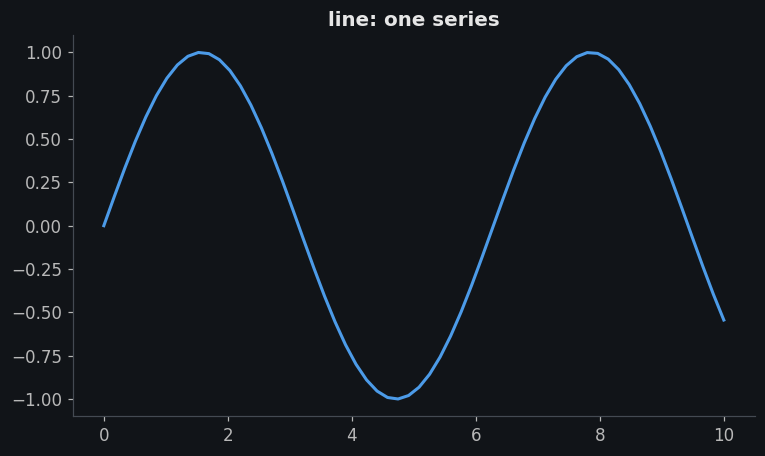

In [8]:
kx.plot(waves.x, waves.y, 'line', title='line: one series');

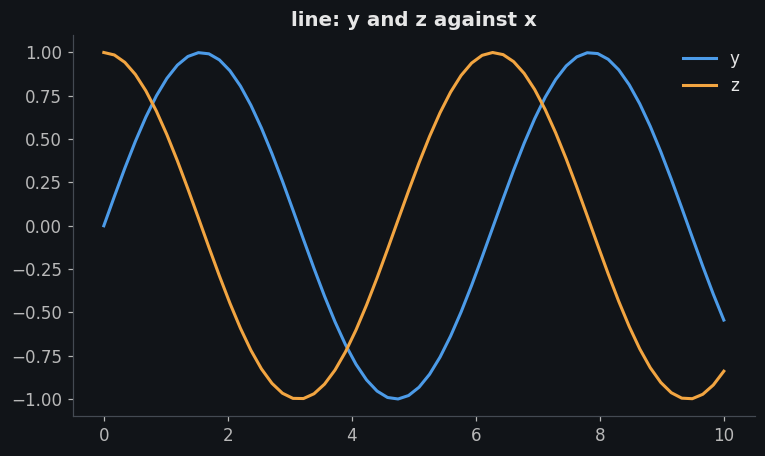

In [9]:
kx.plot(waves.x, waves.y, waves.z, 'line-leg', title='line: y and z against x');

### `step`

Like `line`, drawn as steps centred on each x. Good for counts per period.

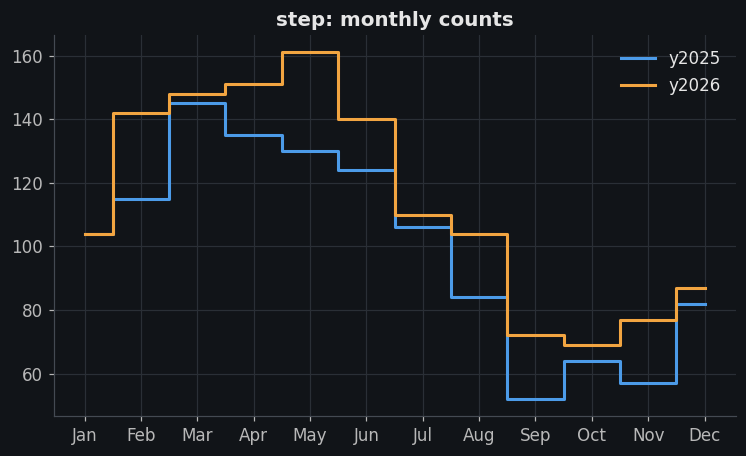

In [10]:
kx.plot(monthly.month, monthly.y2025, monthly.y2026, 'step-leg-grid', title='step: monthly counts');

### `area`

| spec         | result                                                                  |
|--------------|-------------------------------------------------------------------------|
| `area`       | each series filled down to 0, semi-transparent so overlaps stay visible |
| `area-stack` | `z` stacked on top of `y`; the top edge is the total                    |
| `area-norm`  | 100% stack: each series' share of the total at every x (needs `z`)      |

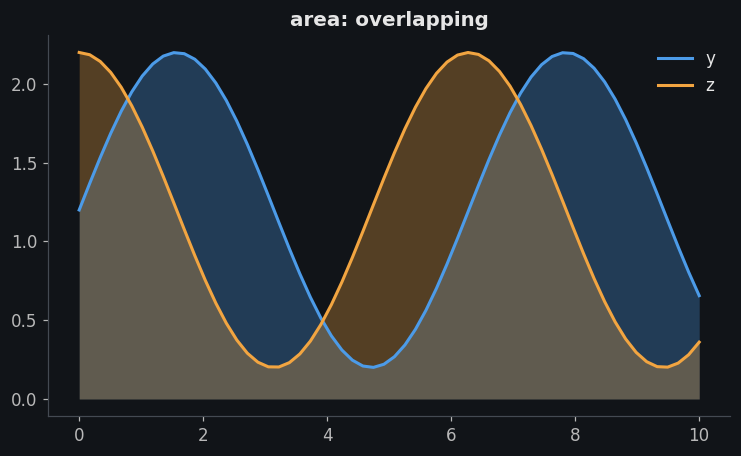

In [11]:
kx.plot(waves.x, waves.y + 1.2, waves.z + 1.2, 'area-leg', title='area: overlapping');

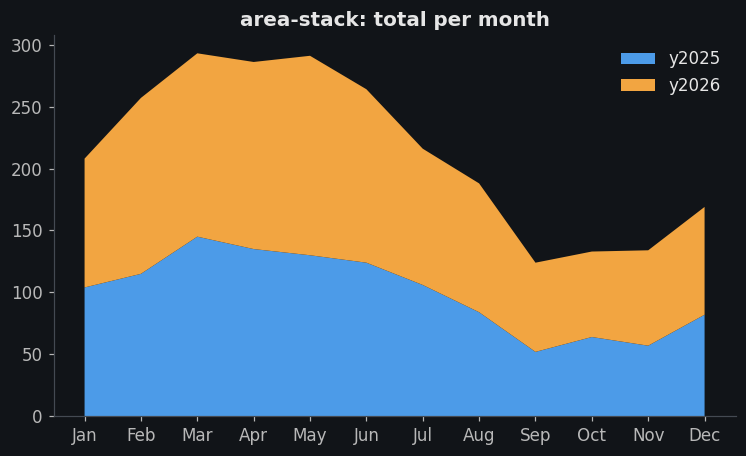

In [12]:
kx.plot(monthly.month, monthly.y2025, monthly.y2026, 'area-stack-leg', title='area-stack: total per month');

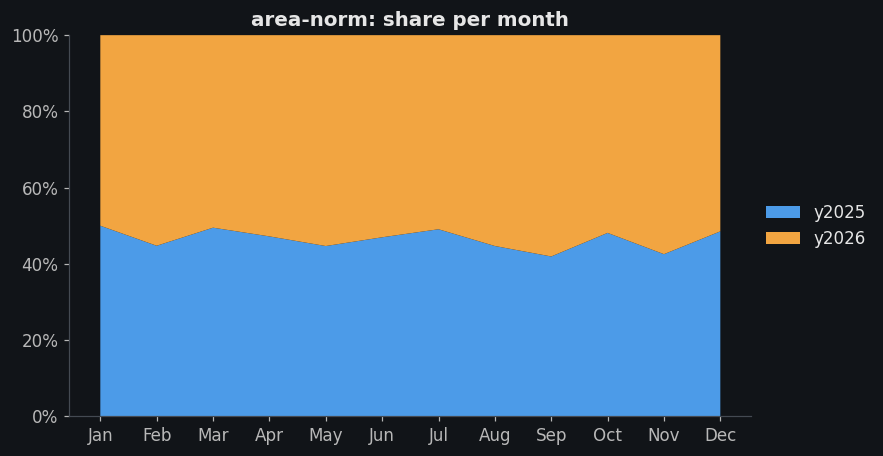

In [13]:
kx.plot(monthly.month, monthly.y2025, monthly.y2026, 'area-norm-leg', title='area-norm: share per month');

With `norm` the area fills the whole plot, so `leg` puts the legend outside on the right.

### `band`

A centre line `y` with a shaded band from `y - z` to `y + z` in the same colour, e.g. mean ± std or a forecast ± error. `z` can be a single number repeated, or vary along x.

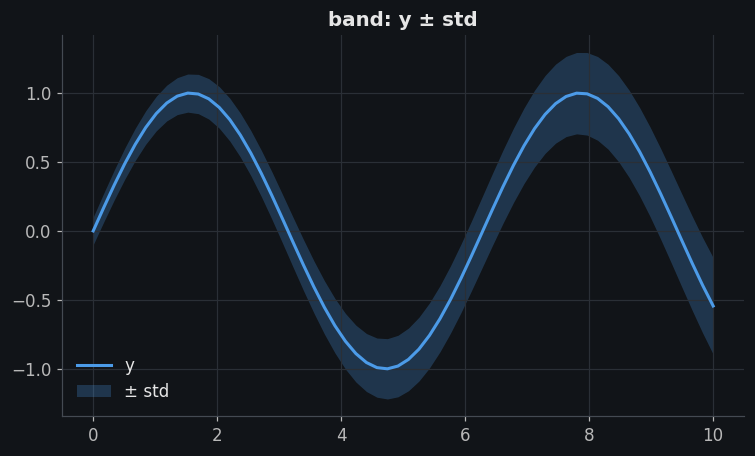

In [14]:
t = waves.x
spread = pd.Series(0.1 + t / 40, name='std')           # uncertainty growing with x
kx.plot(t, waves.y, spread, 'band-leg-grid', title='band: y ± std');

### `scatter`

What `z` does depends on its type:
- **numbers** colour the points and add a colorbar (colormap from `kx.use(cmap=...)`, see section 7)
- **text, bool or pandas categorical** gives one colour per category and a legend titled with `z`'s name. Categories are sorted, unless `z` is a `pd.Categorical`, which keeps its own order.

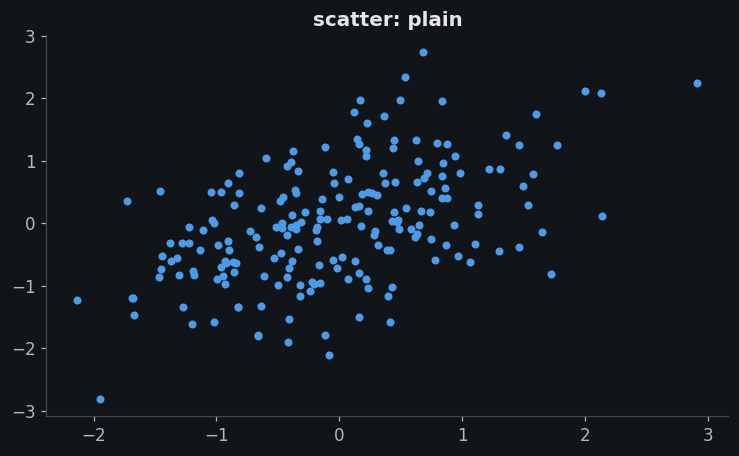

In [15]:
kx.plot(cloud.x, cloud.y, 'scatter', title='scatter: plain');

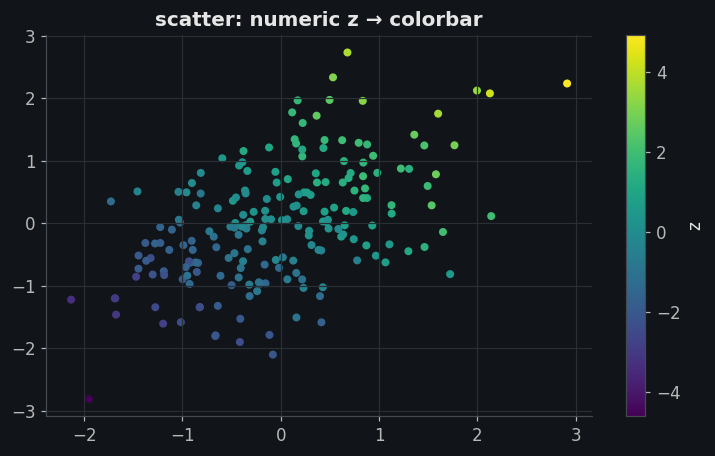

In [16]:
kx.plot(cloud.x, cloud.y, cloud.z, 'scatter-grid', title='scatter: numeric z → colorbar');

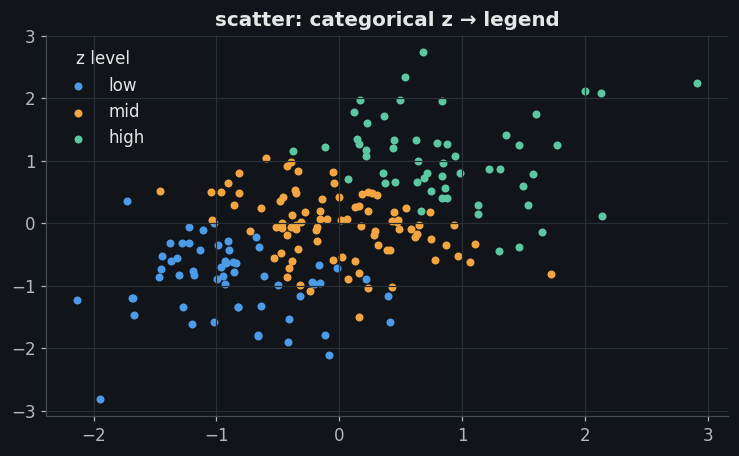

In [17]:
level = pd.Series(pd.cut(cloud.z, [-np.inf, -1, 1, np.inf], labels=['low', 'mid', 'high']), name='z level')
kx.plot(cloud.x, cloud.y, level, 'scatter-grid', title='scatter: categorical z → legend');

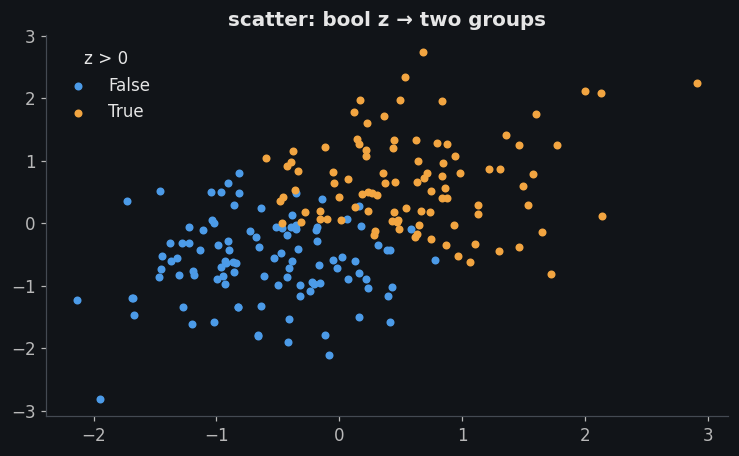

In [18]:
kx.plot(cloud.x, cloud.y, (cloud.z > 0).rename('z > 0'), 'scatter', title='scatter: bool z → two groups');

### `bar`

`x` gives the category labels; with `z` the bars are grouped side by side, or with `stack` `z` is drawn on top of `y` so the bar's top is the total.

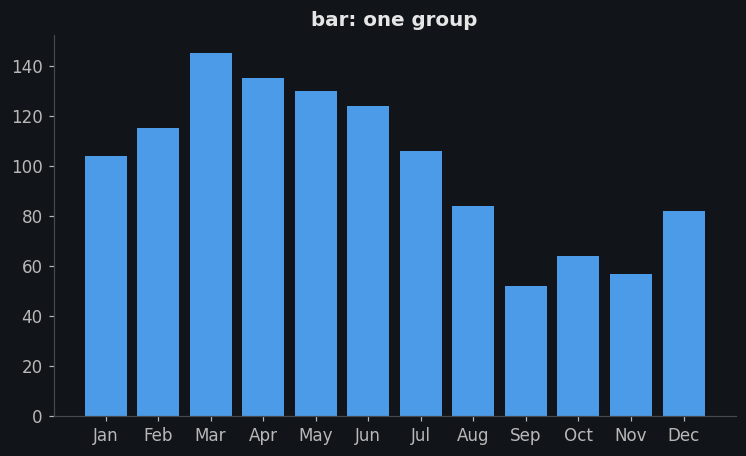

In [19]:
kx.plot(monthly.month, monthly.y2025, 'bar', title='bar: one group');

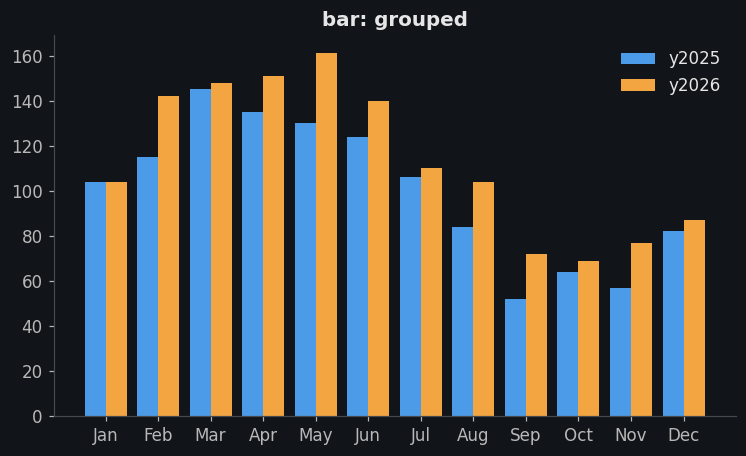

In [20]:
kx.plot(monthly.month, monthly.y2025, monthly.y2026, 'bar-leg', title='bar: grouped');

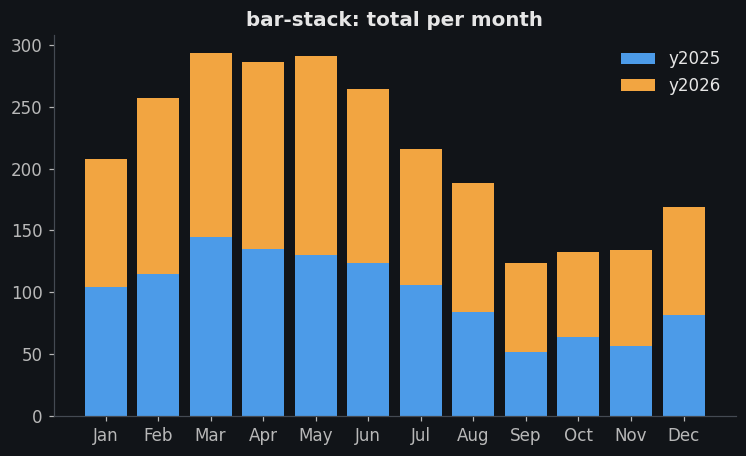

In [21]:
kx.plot(monthly.month, monthly.y2025, monthly.y2026, 'bar-stack-leg', title='bar-stack: total per month');

### `barh`

Like `bar`, lying down: the first category is on top, so it reads like a table. Long category names fit better this way. `stack` works the same.

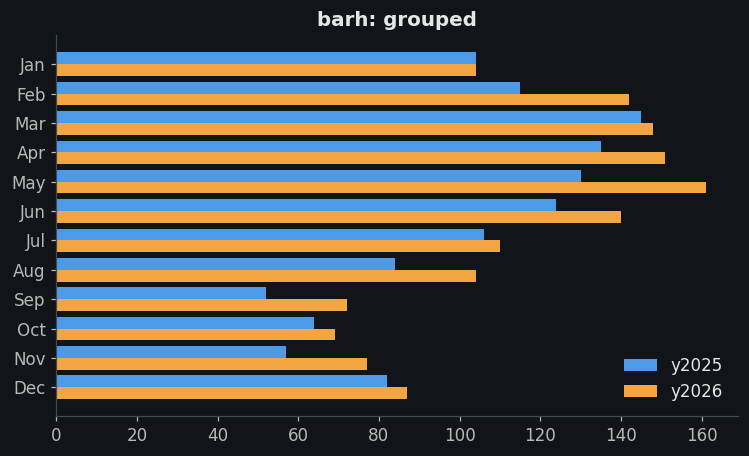

In [22]:
kx.plot(monthly.month, monthly.y2025, monthly.y2026, 'barh-leg', title='barh: grouped');

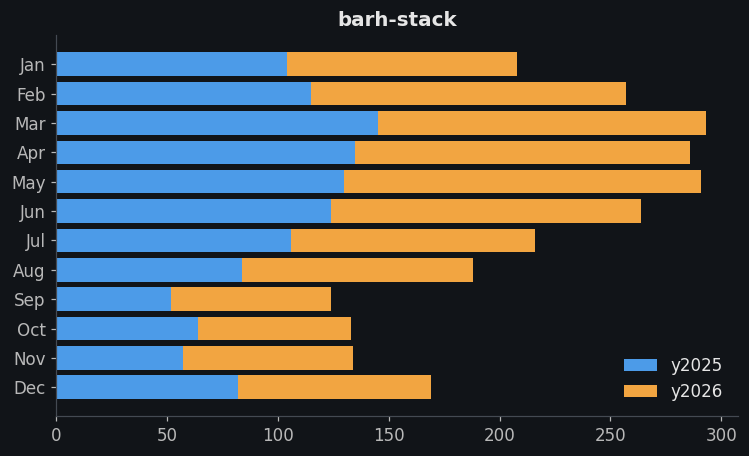

In [23]:
kx.plot(monthly.month, monthly.y2025, monthly.y2026, 'barh-stack-leg', title='barh-stack');

### `hist`

Up to three samples on the same 30 bins, so overlaid bars line up. `y` is optional here.

| spec            | result                                                                    |
|-----------------|---------------------------------------------------------------------------|
| `hist`          | overlaid, semi-transparent                                                |
| `hist-stack`    | stacked on top of each other                                              |
| `hist-norm`     | density: each histogram has area 1, so samples of different sizes compare |
| `hist-cum`      | cumulative counts, drawn as outlines so they don't hide each other        |
| `hist-norm-cum` | the CDF, from 0 to 1                                                      |

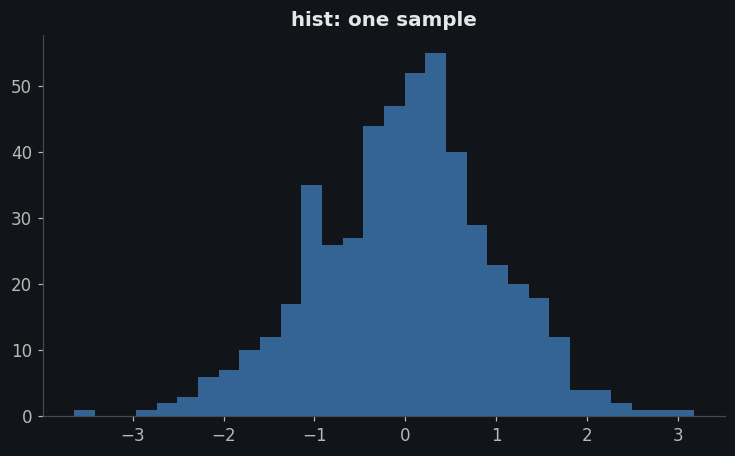

In [24]:
kx.plot(dists.normal, spec='hist', title='hist: one sample');

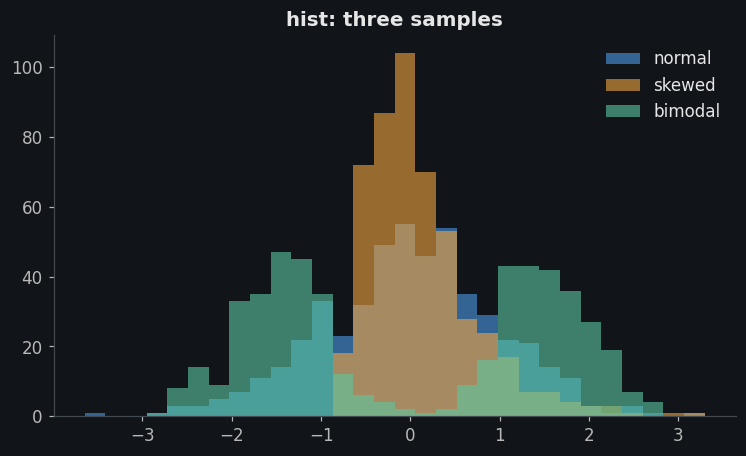

In [25]:
kx.plot(dists.normal, dists.skewed, dists.bimodal, 'hist-leg', title='hist: three samples');

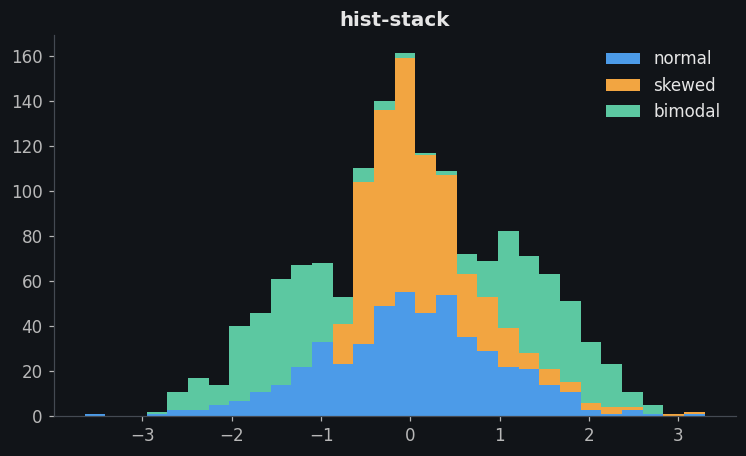

In [26]:
kx.plot(dists.normal, dists.skewed, dists.bimodal, 'hist-stack-leg', title='hist-stack');

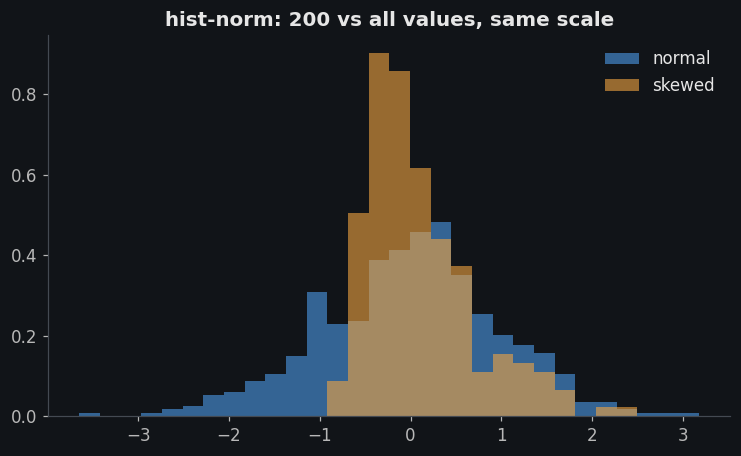

In [27]:
kx.plot(dists.normal, dists.skewed[:200], 'hist-norm-leg', title='hist-norm: 200 vs all values, same scale');

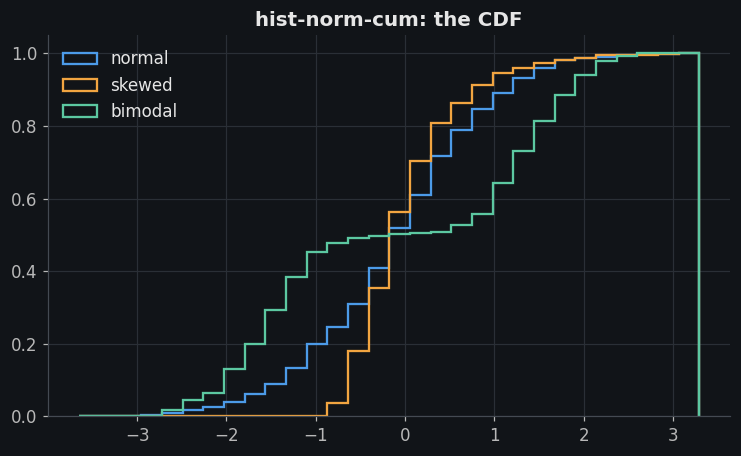

In [28]:
kx.plot(dists.normal, dists.skewed, dists.bimodal, 'hist-norm-cum-leg-grid', title='hist-norm-cum: the CDF');

### `kde`

Smooth density curves, one per sample: a Gaussian kernel density estimate with Silverman's bandwidth, computed in numpy (no scipy needed). Each curve has area 1.

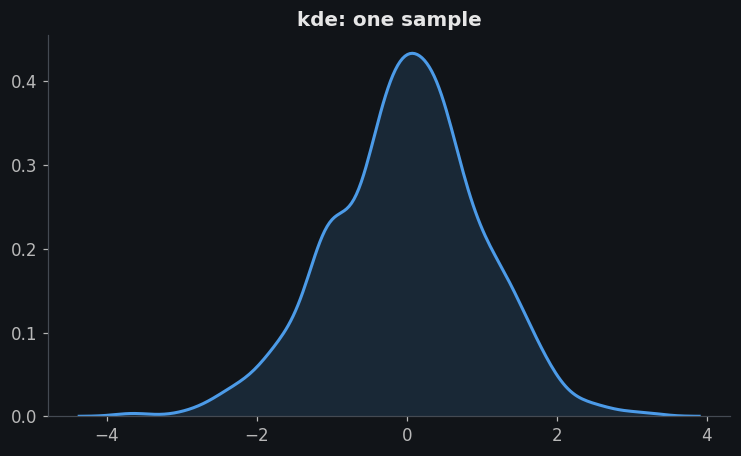

In [29]:
kx.plot(dists.normal, spec='kde', title='kde: one sample');

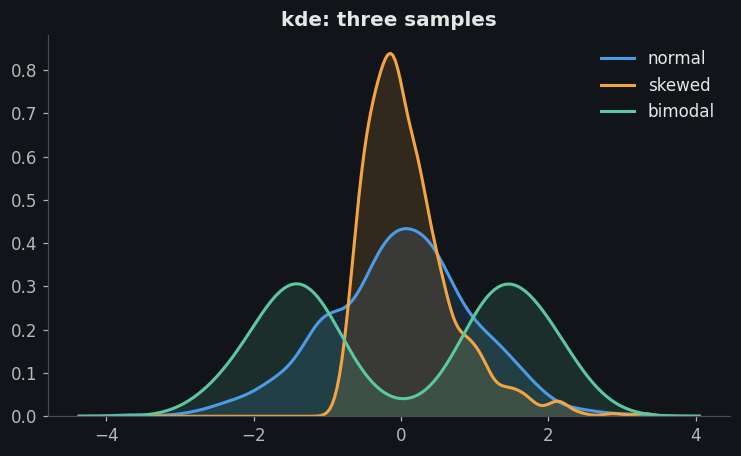

In [30]:
kx.plot(dists.normal, dists.skewed, dists.bimodal, 'kde-leg', title='kde: three samples');

### `ridge`

The same density curves, each on its own row, first sample on top: a ridgeline. With many groups, overlaid `kde` curves become a tangle; ridges stay readable. All ridges share one height scale, so a flat ridge really is a spread-out sample. `overlap=` sets how tall the tallest ridge is, in rows; `mean` and `median` mark each ridge.

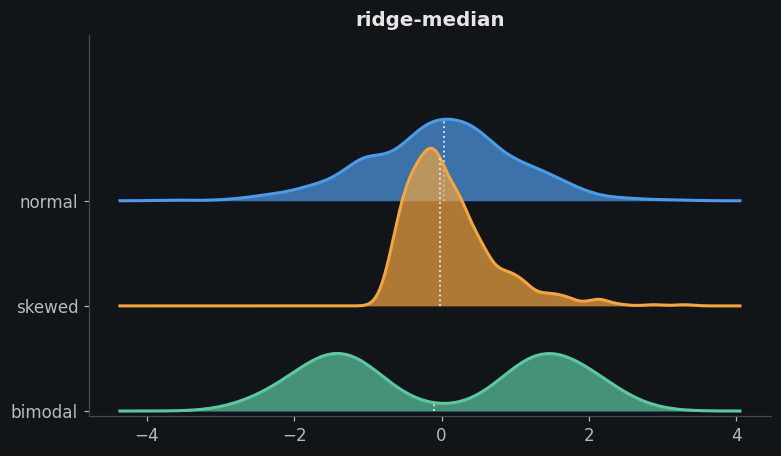

In [31]:
kx.plot(dists.normal, dists.skewed, dists.bimodal, 'ridge-median', title='ridge-median');

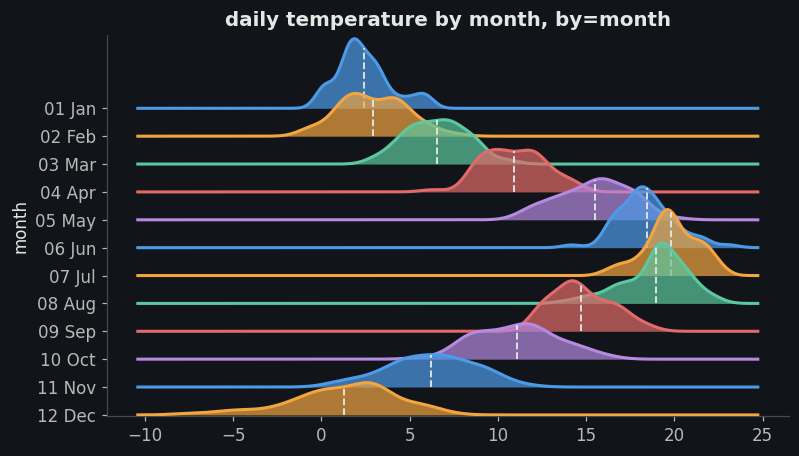

In [32]:
temps = daily.assign(month=pd.to_datetime(daily.date).dt.strftime('%m %b'))
kx.plot(temps, 'temp', spec='ridge-mean', by='month', overlap=2.5, title='daily temperature by month, by=month');

### `ecdf`

The empirical CDF: at each x, the share of values at or below it. Nothing is binned or smoothed, so every value counts. Reading off a quantile is easy: where a curve crosses 0.5 is its median.

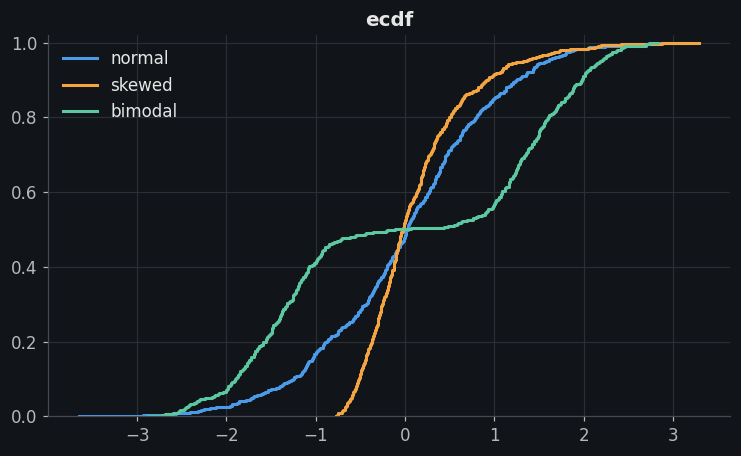

In [33]:
kx.plot(dists.normal, dists.skewed, dists.bimodal, 'ecdf-leg-grid', title='ecdf');

### `box`

Boxes side by side: the median, the quartile box, whiskers to 1.5 × IQR and the points beyond as outliers. Each box is named after its sample.

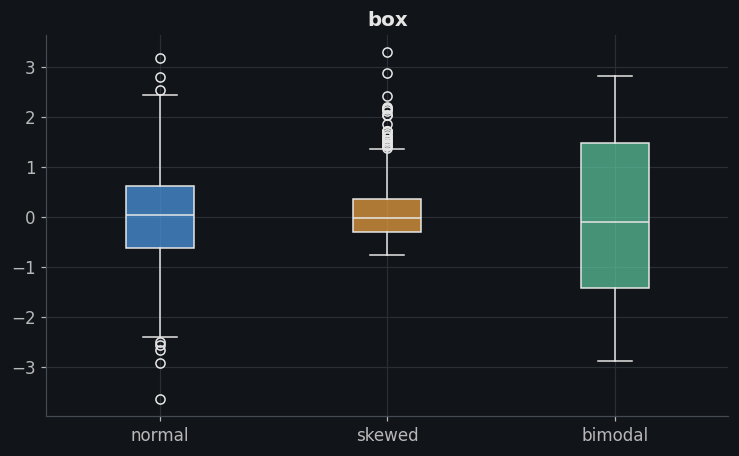

In [34]:
kx.plot(dists.normal, dists.skewed, dists.bimodal, 'box-grid', title='box');

### `violin`

A mirrored density per sample, with the quartiles as a thick line and the median as a dot. Unlike `box`, it shows that `bimodal` has two peaks.

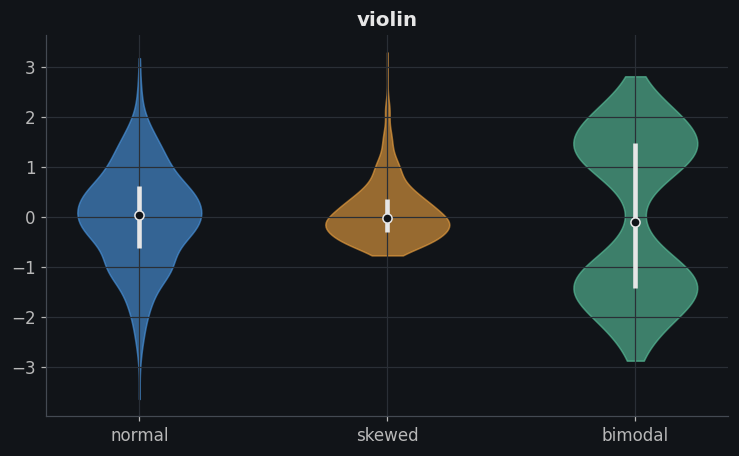

In [35]:
kx.plot(dists.normal, dists.skewed, dists.bimodal, 'violin-grid', title='violin');

### `strip`

Every value as a point, one column per sample, spread sideways at random (the same way every run) so equal values don't hide each other. Good for small samples, where a box or violin hides how few points there are. `jitter=` sets the spread; `mean` and `ann` work as for `box`.

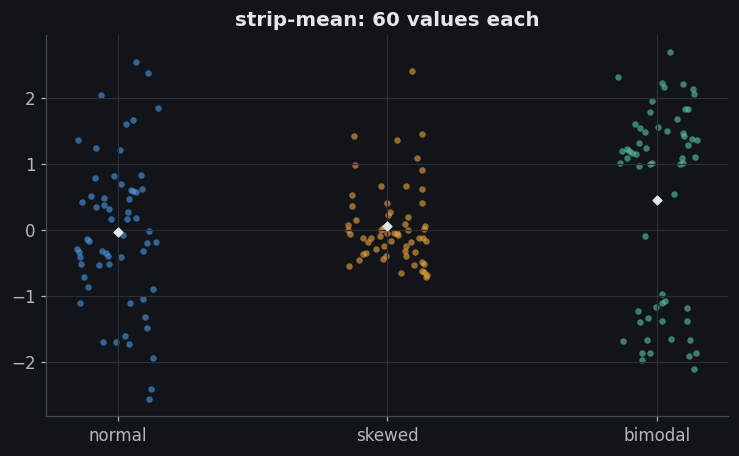

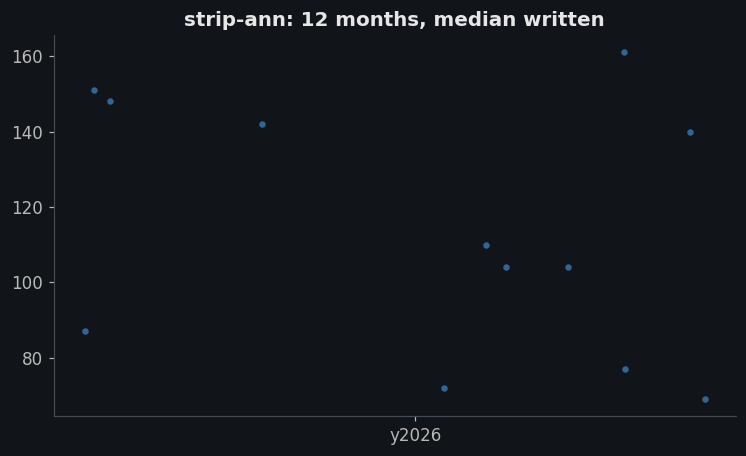

In [36]:
kx.plot(dists.normal[:60], dists.skewed[:60], dists.bimodal[:60], 'strip-mean-grid', title='strip-mean: 60 values each');
kx.plot(monthly, 'y2026', spec='strip-ann', jitter=0.05, title='strip-ann: 12 months, median written');

### `qq`

Each sample's sorted values against the quantiles a normal distribution would have, with a dashed line through its quartiles. A normal sample lies on its line. Points curving away at both ends mean heavier (or lighter) tails than normal, a bend that goes one way means skew, and an S with a flat middle means two groups. The normal quantiles come from Python's `statistics`, so no scipy is needed.

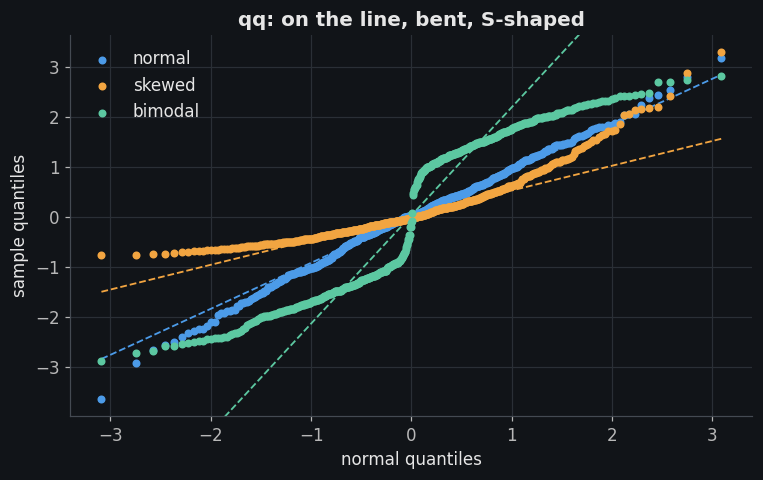

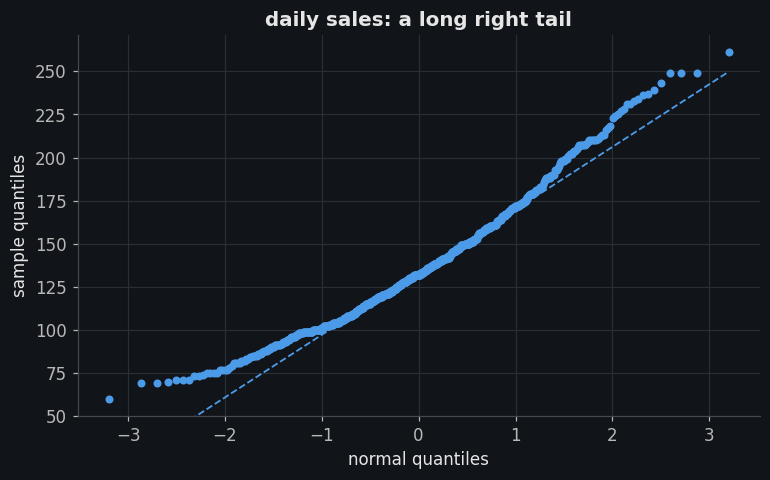

In [37]:
kx.plot(dists.normal, dists.skewed, dists.bimodal, 'qq-leg-grid', title='qq: on the line, bent, S-shaped');
kx.plot(daily, 'sales', spec='qq-grid', title='daily sales: a long right tail');

## 4. Call shapes

- `kx.plot(x, y, z, spec)` is the full form.
- `kx.plot(df, 'x', 'y', 'z', spec)` names columns of a DataFrame instead; `by=` can name a column too.
- With no `z`, the spec can go third: `kx.plot(x, y, 'bar')`.
- `spec=`, `title=` and `ax=` also work as keywords.
- Any other keyword goes to the matplotlib call that draws the kind and wins over kx's own defaults (below).
- `by=` gives a group per `x` value for `kde`, `ecdf`, `box` and `violin` (below).
- A pandas Series' name becomes its legend label; plain numpy arrays are labelled `y` and `z`.

`kx.plot` returns the matplotlib `Axes`, so you can keep customising it.

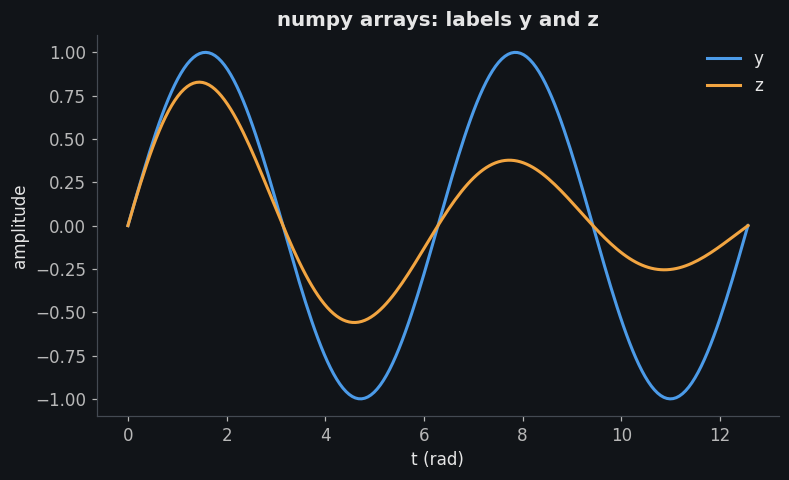

In [38]:
rng = np.random.default_rng(0)
t = np.linspace(0, 4 * np.pi, 200)
a, b = np.sin(t), np.sin(t) * np.exp(-t / 8)

ax = kx.plot(t, a, b, spec='line-leg', title='numpy arrays: labels y and z')
ax.set_xlabel('t (rad)'); ax.set_ylabel('amplitude');

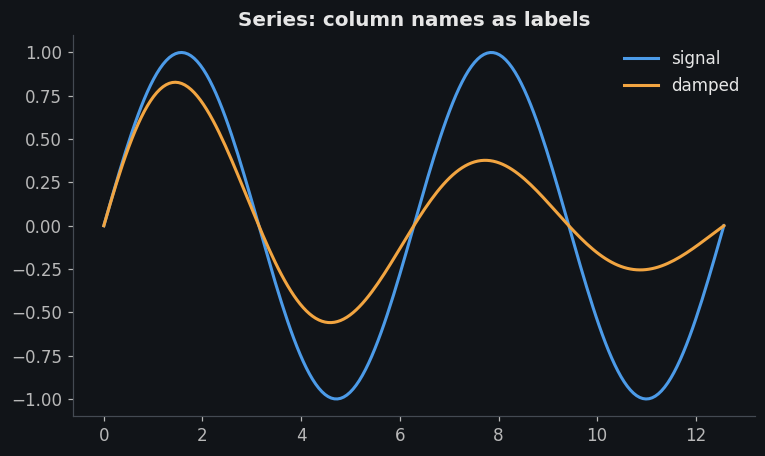

In [39]:
df = pd.DataFrame({'t': t, 'signal': a, 'damped': b})
kx.plot(df.t, df.signal, df.damped, 'line-leg', title='Series: column names as labels');

With a DataFrame first, the next strings are column names, and a last string that isn't a column is the spec. A column named like a kind (say `bar`) is still a column. A mistyped column gets the closest names as a hint.

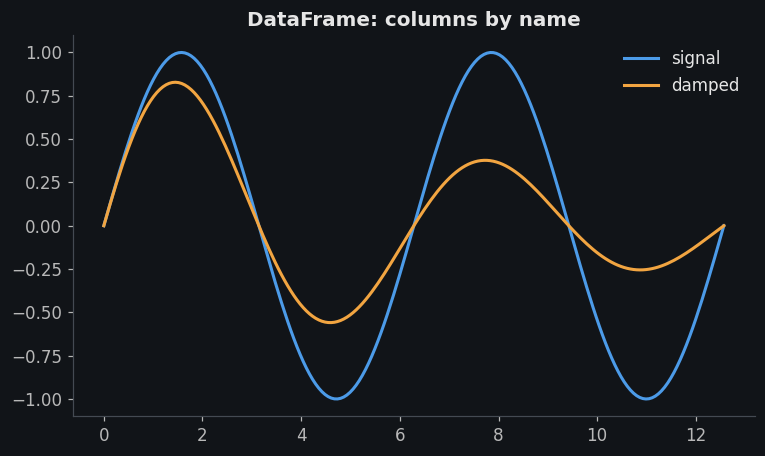

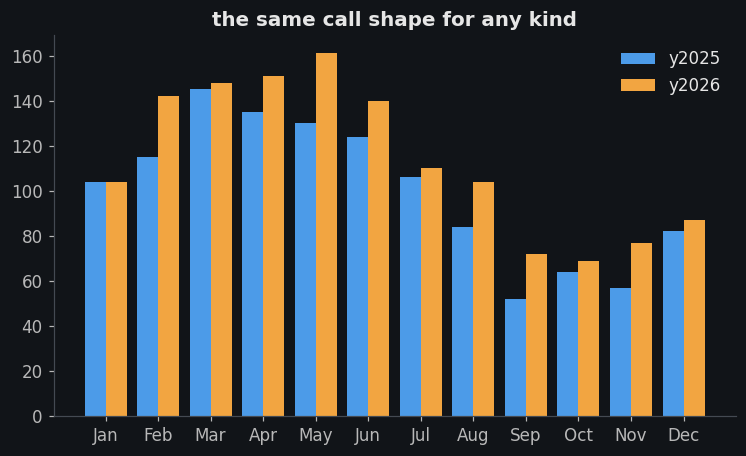

In [40]:
kx.plot(df, 't', 'signal', 'damped', 'line-leg', title='DataFrame: columns by name');
kx.plot(monthly, 'month', 'y2025', 'y2026', 'bar-leg', title='the same call shape for any kind');

In [41]:
try:
    kx.plot(df, 't', 'singal')
except ValueError as e:
    print('ValueError :', e)

ValueError : no column 'singal' in the DataFrame. Did you mean ['signal']?


### Matplotlib keywords

Keywords `kx.plot` doesn't know are passed to the matplotlib call that draws the kind, and they win over kx's defaults: `ax.plot` for `line` and `kde`, `ax.scatter` for `scatter`, `ax.bar` for `bar`, the fills for `area`, `ax.boxplot` for `box` and so on (`kx.grammar(kind)` says which). Two are read by kx itself:
- `bins=` for `hist`: a count, the edges, or a numpy rule like `'auto'`, still shared by every series
- `width=` for `bar` (`height=` for `barh`): the space each category's bars fill, 0.8 by default

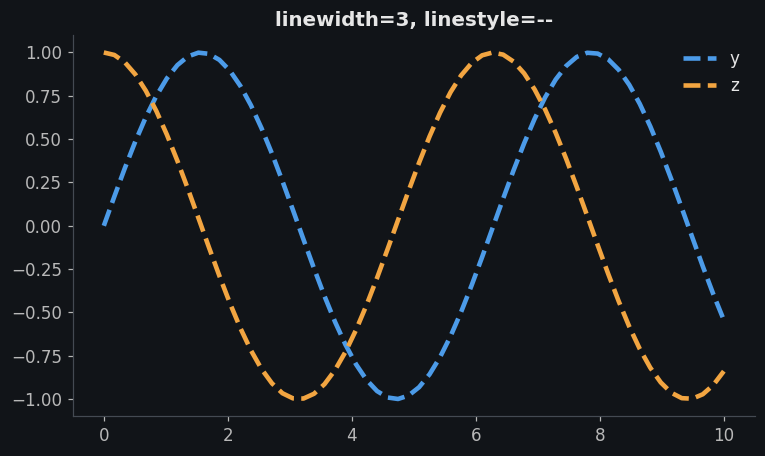

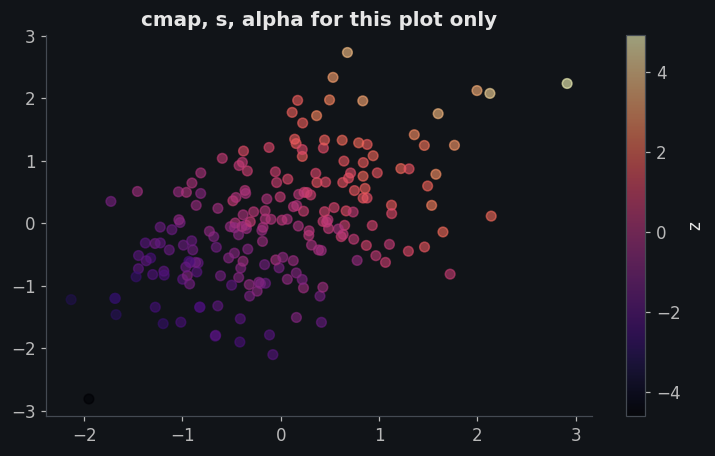

In [42]:
kx.plot(waves.x, waves.y, waves.z, 'line-leg', linewidth=3, linestyle='--', title='linewidth=3, linestyle=--');
kx.plot(cloud.x, cloud.y, cloud.z, 'scatter', cmap='magma', s=40, alpha=0.6, title='cmap, s, alpha for this plot only');

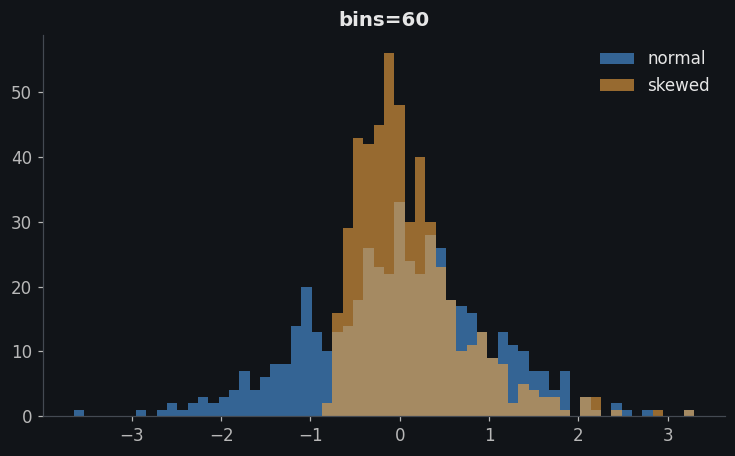

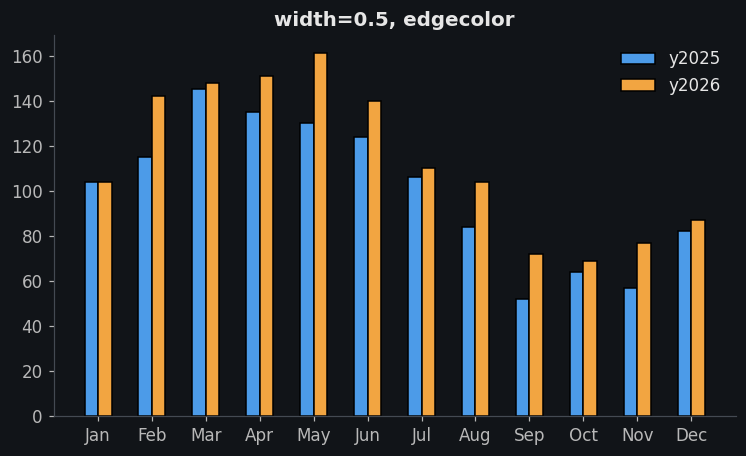

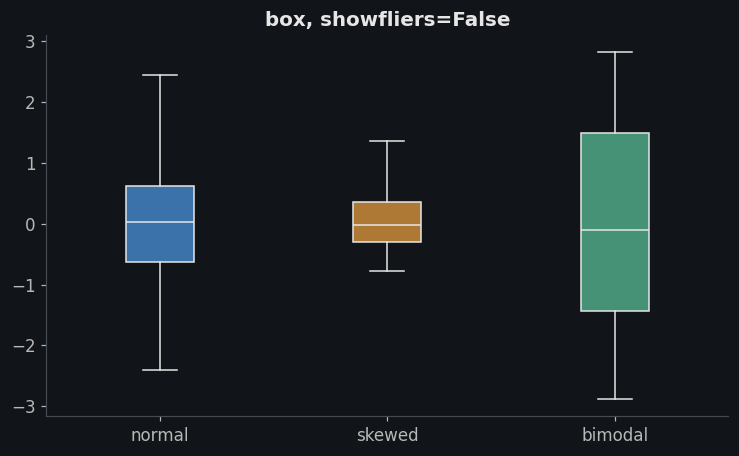

In [43]:
kx.plot(dists.normal, dists.skewed, spec='hist-leg', bins=60, title='bins=60');
kx.plot(monthly.month, monthly.y2025, monthly.y2026, 'bar-leg', width=0.5, edgecolor='black', title='width=0.5, edgecolor');
kx.plot(dists.normal, dists.skewed, dists.bimodal, 'box', showfliers=False, title='box, showfliers=False');

The spec can't be given twice (third argument *and* `spec=`), and every kind except the distribution kinds (`hist`, `kde`, `ridge`, `ecdf`, `box`, `violin`, `strip`, `qq`) needs `y`.

In [44]:
for call in (lambda: kx.plot(t, a, 'line', spec='bar'),
             lambda: kx.plot(t, spec='line')):
    try:
        call()
    except (TypeError, ValueError) as e:
        print(type(e).__name__, ':', e)

TypeError : spec given twice ('line' and spec='bar')
ValueError : kind 'line' needs both x and y


### Groups with `by=`

Data often comes long: one column of values and one column saying which group each value is in. `by=` splits `x` into one curve, box or violin per group, and names the legend or the axis after the `by` Series. Groups are sorted, unless `by` is a `pd.Categorical`, which keeps its own order.

In [45]:
long = dists.melt(var_name='dist', value_name='value')   # 3 columns -> value + group
long.sample(5, random_state=0)

,dist,value
471,normal,1.2263
9,normal,-1.9368
1499,bimodal,-1.8395
54,normal,0.3877
1411,bimodal,0.8209


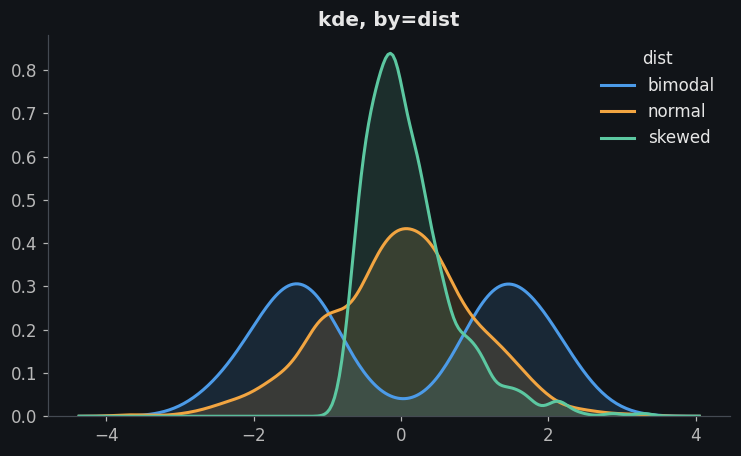

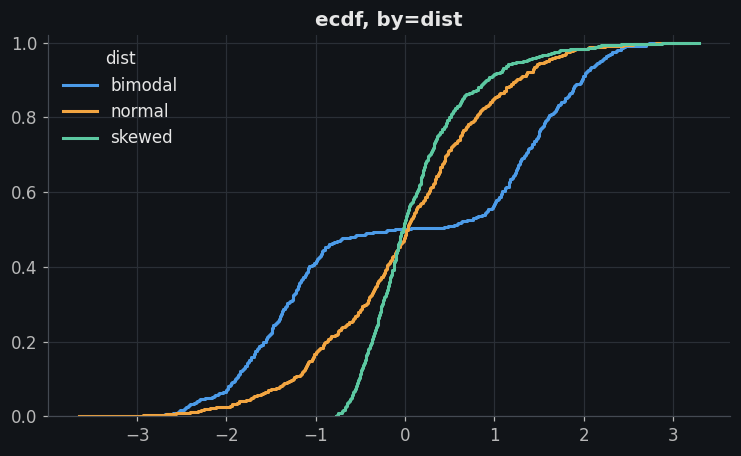

In [46]:
kx.plot(long, 'value', spec='kde', by='dist', title='kde, by=dist');
kx.plot(long.value, spec='ecdf-grid', by=long.dist, title='ecdf, by=dist');

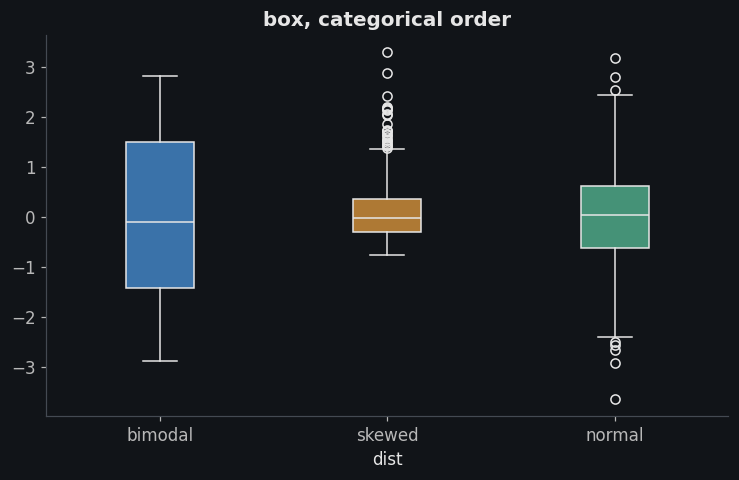

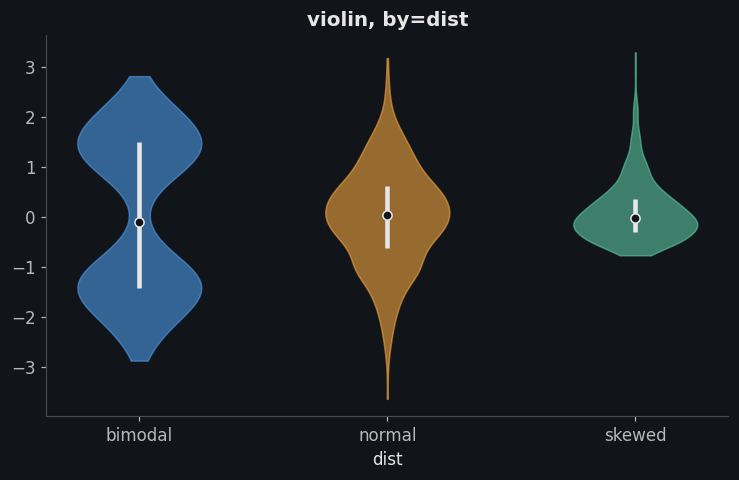

In [47]:
order = pd.Categorical(long.dist, categories=['bimodal', 'skewed', 'normal'])
kx.plot(long.value, spec='box', by=pd.Series(order, name='dist'), title='box, categorical order');
kx.plot(long.value, spec='violin', by=long.dist, title='violin, by=dist');

`by=` only works with those four kinds, and replaces `y` and `z`:

In [48]:
for call in (lambda: kx.plot(long.value, spec='hist', by=long.dist),
             lambda: kx.plot(long.value, long.value, spec='kde', by=long.dist)):
    try:
        call()
    except ValueError as e:
        print('ValueError :', e)
plt.close('all')

ValueError : by= only works with kind ['box', 'count', 'ecdf', 'kde', 'qq', 'ridge', 'strip', 'violin'], not 'hist'
ValueError : by= splits x into groups; pass only x, not y or z


## 5. Flags

Flags that work with every kind:

| flag                      | effect                                                           |
|---------------------------|------------------------------------------------------------------|
| `grid`                    | turn on the grid                                                 |
| `leg`                     | show the legend                                                  |
| `legout`                  | legend outside, right of the plot                                |
| `tight`                   | `tight_layout()` on the figure                                   |
| `rot`                     | x tick labels rotated 45°                                        |
| `wrap`                    | long tick labels broken onto lines of about 12 characters        |
| `logx` / `logy` / `logxy` | log scale on x, y or both                                        |
| `symlogy`                 | symmetric log y: log both ways, linear near 0, so negatives work |
| `zero`                    | stretch the value axis to include 0                              |
| `eq`                      | equal aspect: one unit is as long on x as on y                   |
| `pct`                     | value axis as percent: 0.25 → 25%                                |
| `si`                      | value axis with SI prefixes: 1500 → 1.5k                         |

The value axis is y, except for `barh`, where it is x.

Flags for some kinds:

| flag              | kinds                                     | effect                                                        |
|-------------------|-------------------------------------------|---------------------------------------------------------------|
| `stack`           | `area`, `bar`, `barh`, `hist`, `count`    | stack the series                                              |
| `norm`            | `area`, `hist`                            | `area`: 100% stack (implies `stack`); `hist`: density, area 1 |
| `norm`            | `count`, `crosstab`                       | shares instead of counts                                      |
| `corr`            | `heat`                                    | the correlations of the numeric columns                       |
| `all`             | `missing`                                 | also the columns with nothing missing                         |
| `cum`             | `hist`                                    | cumulative; `hist-norm-cum` is the CDF                        |
| `date`            | `line`, `step`, `area`, `band`, `scatter` | `x` read as dates (strings work too), compact date ticks      |
| `mk`              | `line`, `step`, `area`, `band`            | a marker on every point                                       |
| `sort`            | `bar`, `barh`, `count`                    | largest first (by `y`, or by the total with `stack`)          |
| `sort`            | `nullmap`                                 | the rows with the most missing values on top                  |
| `ann`             | `bar`, `barh`, `count`, `missing`         | the value on each bar                                         |
| `ann`             | `heat`, `crosstab`, `cm`                  | the value in each cell                                        |
| `mean` / `median` | `hist`, `kde`, `ecdf`                     | a dashed / dotted line at each series' mean / median          |
| `mean`            | `box`, `violin`                           | a diamond at each mean                                        |
| `ann`             | `hist`, `kde`, `ecdf`, `box`, `violin`    | write the mean / median values                                |
| `nocb`            | `scatter`, `heat`, `crosstab`, `hexbin`,  | no colorbar                                                   |
|                   | `cm`, `resid`                             |                                                               |
| `sym`             | `scatter`, `heat`, `hexbin` (with `z`)    | colour limits ±max\|z\|, so 0 is the middle colour            |
| `logc`            | `scatter`, `heat`, `crosstab`, `hexbin`   | log colour scale (values > 0)                                 |
| `diag`            | `scatter`, `hexbin`                       | a dashed `y = x` line across the range x and y share          |
| `fit`             | `scatter`                                 | a least-squares line, slope and R² in the legend              |
| `best`            | `thresh`, `loss`, `elbow`                 | a dashed line at the best threshold, epoch or k               |
| `norm`            | `cm`                                      | each row sums to 1: the recall of each class                  |
| `norm`            | `proba`                                   | densities, so a small class is as visible as a big one        |

Tokens can come in any order, so `line-grid-leg` and `leg-grid-line` are the same plot.

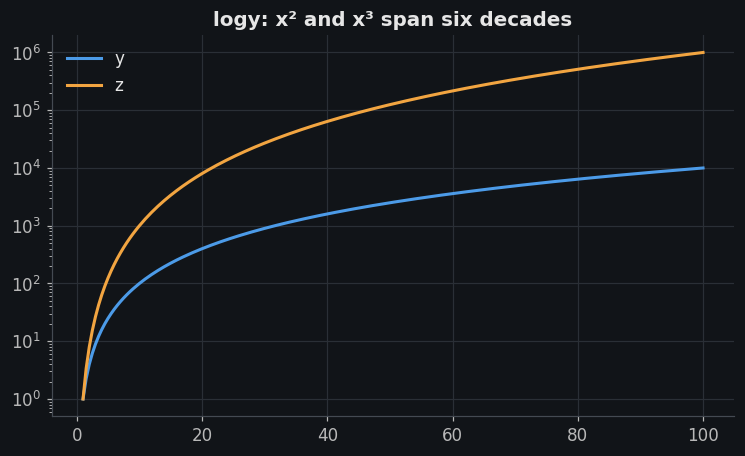

In [49]:
x = np.linspace(1, 100, 200)
kx.plot(x, x ** 2, x ** 3, 'line-logy-grid-leg', title='logy: x² and x³ span six decades');

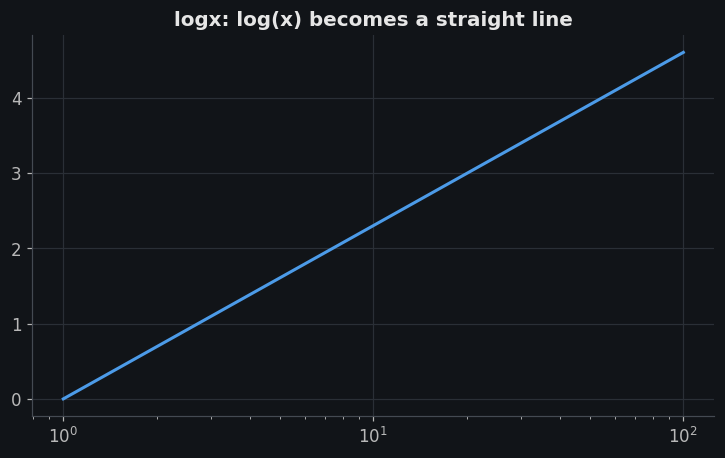

In [50]:
kx.plot(x, np.log(x), 'logx-grid-line', title='logx: log(x) becomes a straight line');

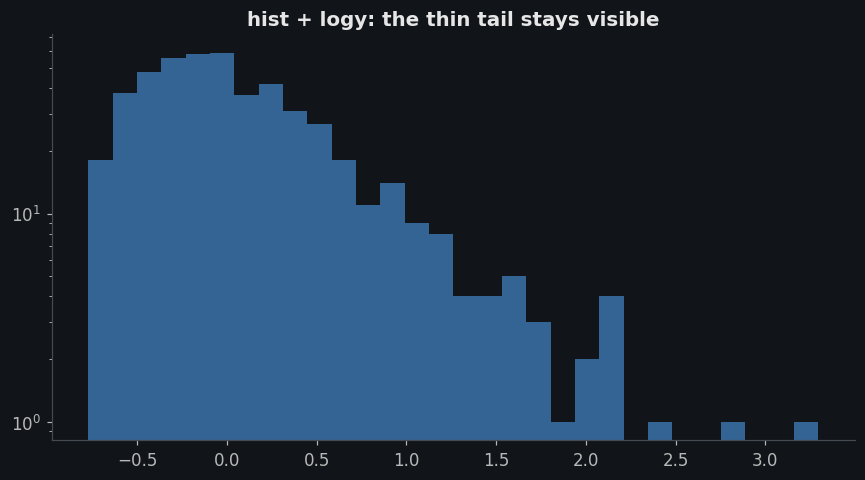

In [51]:
kx.plot(dists.skewed, spec='hist-logy-tight', title='hist + logy: the thin tail stays visible');

### Layout: `legout`, `rot`

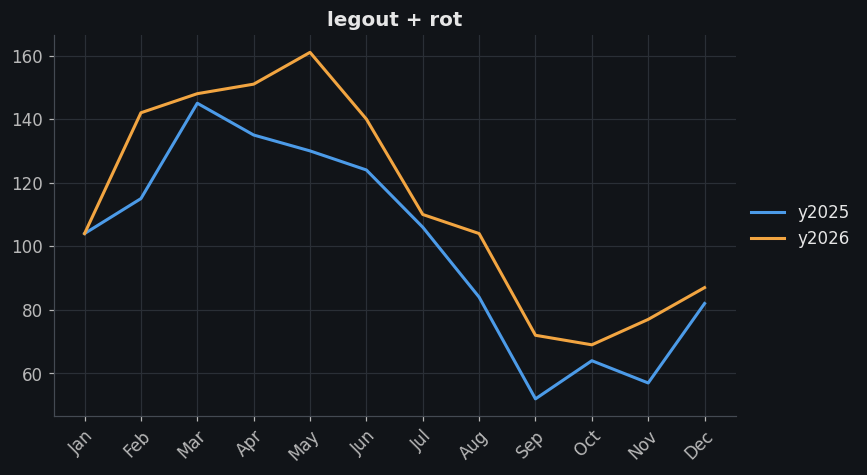

In [52]:
kx.plot(monthly.month, monthly.y2025, monthly.y2026, 'line-legout-rot-grid', title='legout + rot');

### Axes: `logxy`, `symlogy`, `zero`, `eq`, `date`

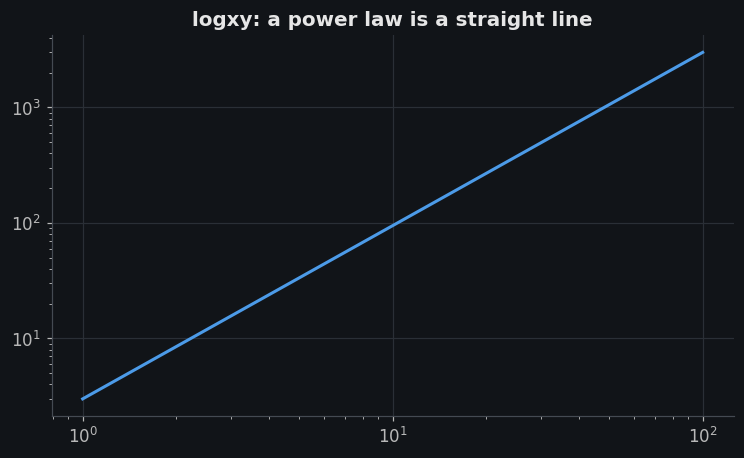

In [53]:
kx.plot(x, 3 * x ** 1.5, 'line-logxy-grid', title='logxy: a power law is a straight line');

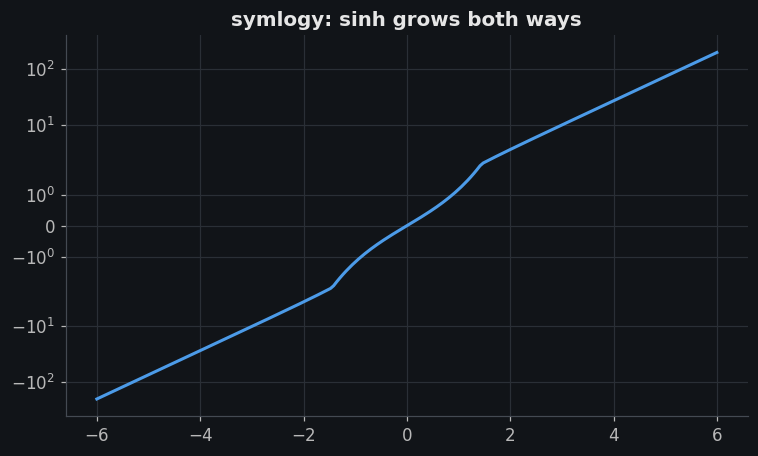

In [54]:
s = np.linspace(-6, 6, 200)
kx.plot(s, np.sinh(s), 'line-symlogy-grid', title='symlogy: sinh grows both ways');

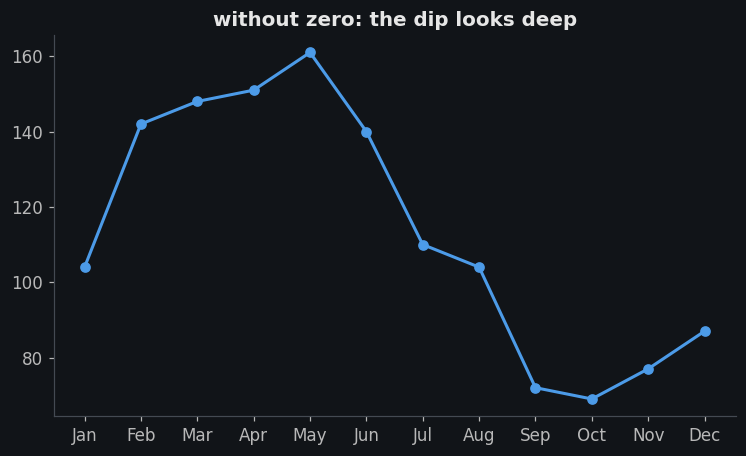

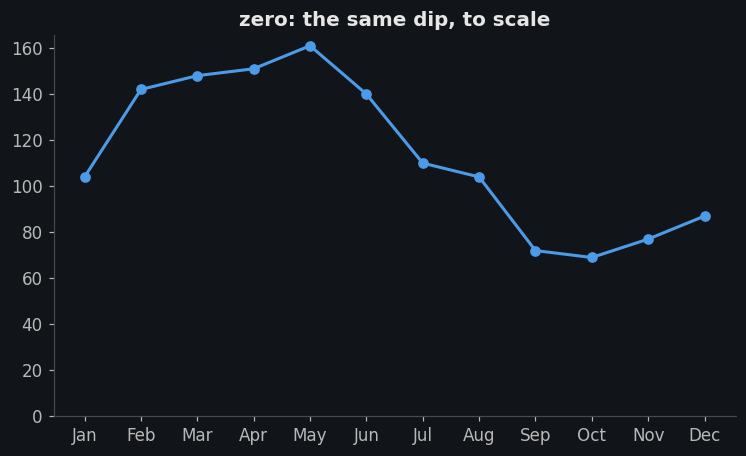

In [55]:
kx.plot(monthly.month, monthly.y2026, 'line-mk', title='without zero: the dip looks deep');
kx.plot(monthly.month, monthly.y2026, 'line-mk-zero', title='zero: the same dip, to scale');

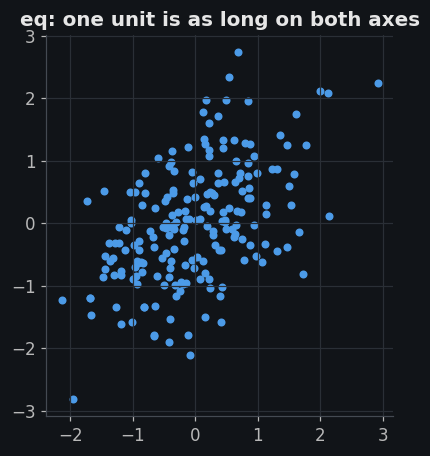

In [56]:
kx.plot(cloud.x, cloud.y, 'scatter-eq-grid', title='eq: one unit is as long on both axes');

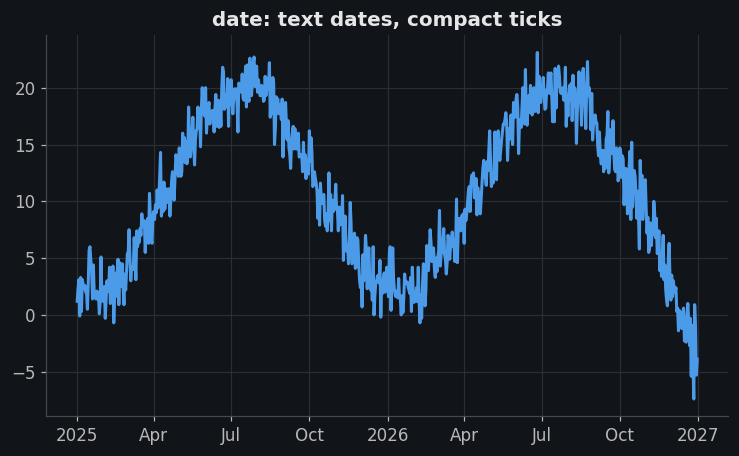

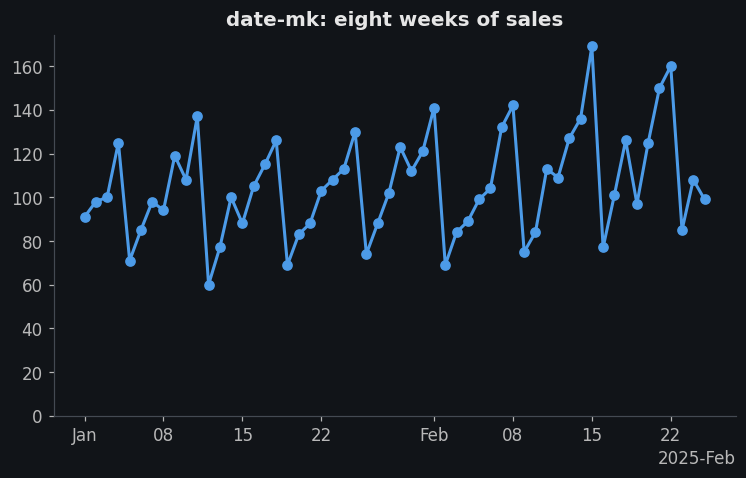

In [57]:
kx.plot(daily.date, daily.temp, 'line-date-grid', title='date: text dates, compact ticks');
kx.plot(daily.date[:56], daily.sales[:56], 'line-date-mk-zero', title='date-mk: eight weeks of sales');

### Number format: `pct`, `si`

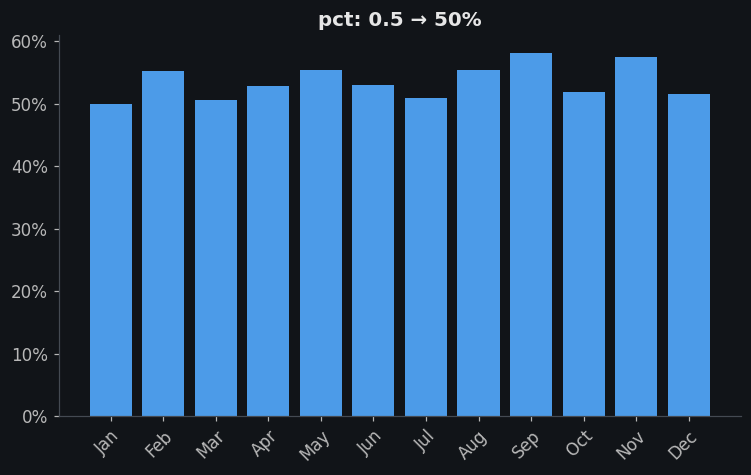

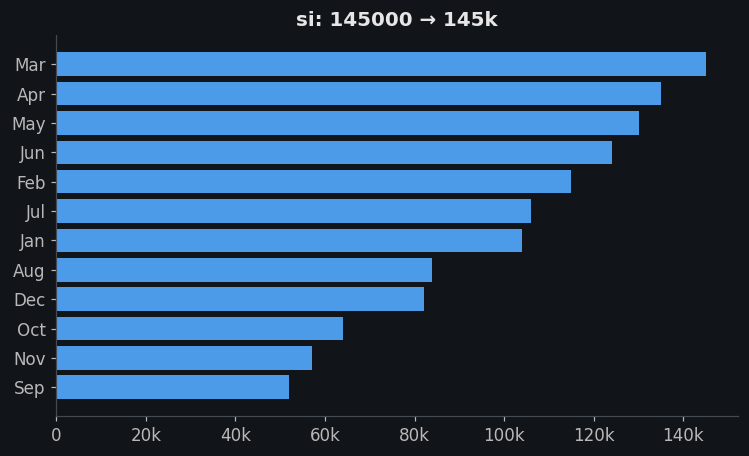

In [58]:
share = monthly.y2026 / (monthly.y2025 + monthly.y2026)
kx.plot(monthly.month, share.rename('2026 share'), 'bar-pct-rot', title='pct: 0.5 → 50%');
kx.plot(monthly.month, monthly.y2025 * 1000, 'barh-si-sort', title='si: 145000 → 145k');

### Markers and annotations: `mk`, `ann`, `mean`, `median`, `sort`

`ann` on bars writes each value; with `stack` it writes each segment's value inside it.

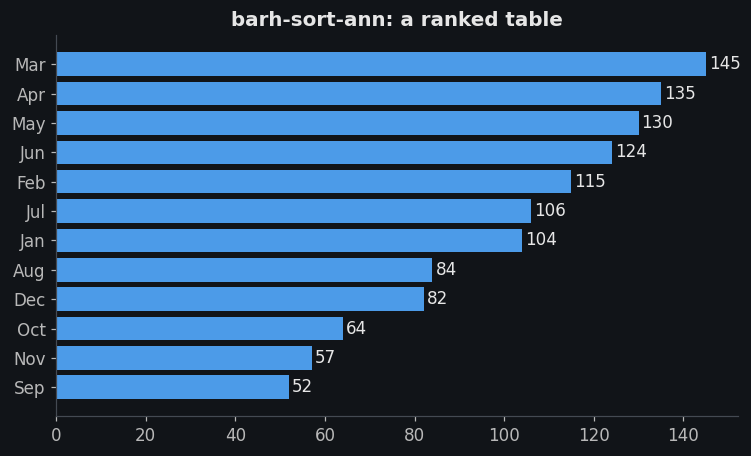

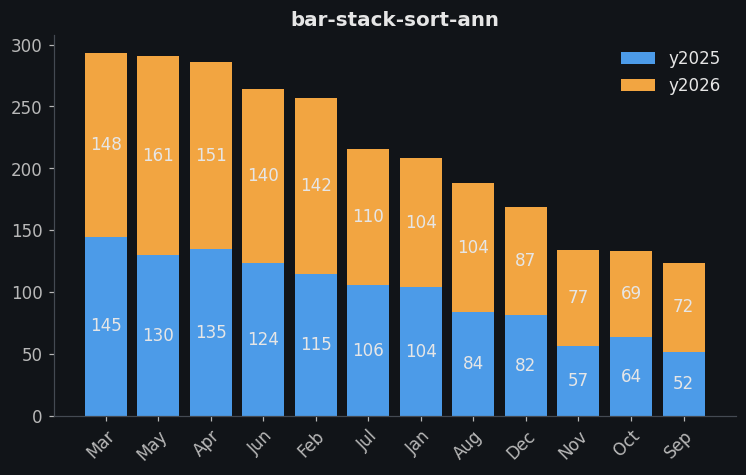

In [59]:
kx.plot(monthly.month, monthly.y2025, 'barh-sort-ann', title='barh-sort-ann: a ranked table');
kx.plot(monthly.month, monthly.y2025, monthly.y2026, 'bar-stack-sort-ann-leg-rot', title='bar-stack-sort-ann');

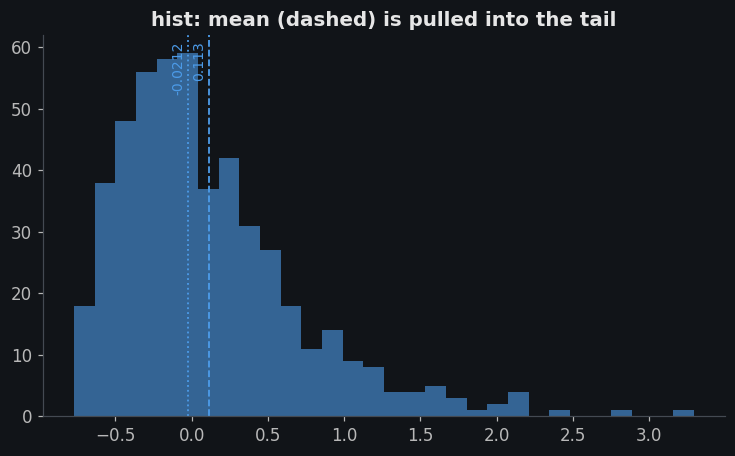

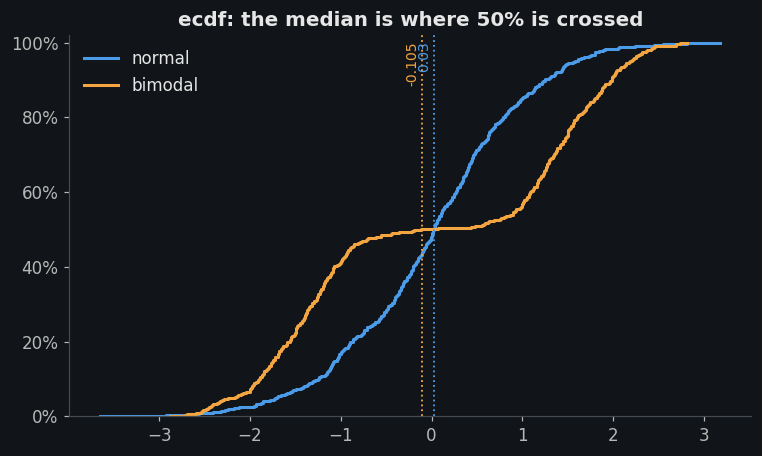

In [60]:
kx.plot(dists.skewed, spec='hist-mean-median-ann', title='hist: mean (dashed) is pulled into the tail');
kx.plot(dists.normal, dists.bimodal, spec='ecdf-median-ann-pct-leg', title='ecdf: the median is where 50% is crossed');

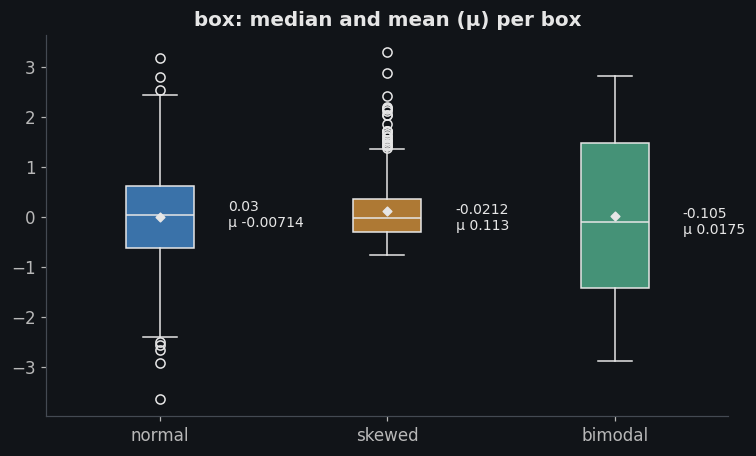

In [61]:
kx.plot(dists.normal, dists.skewed, dists.bimodal, 'box-mean-ann', title='box: median and mean (μ) per box');

### Colour scale: `nocb`, `sym`, `logc`

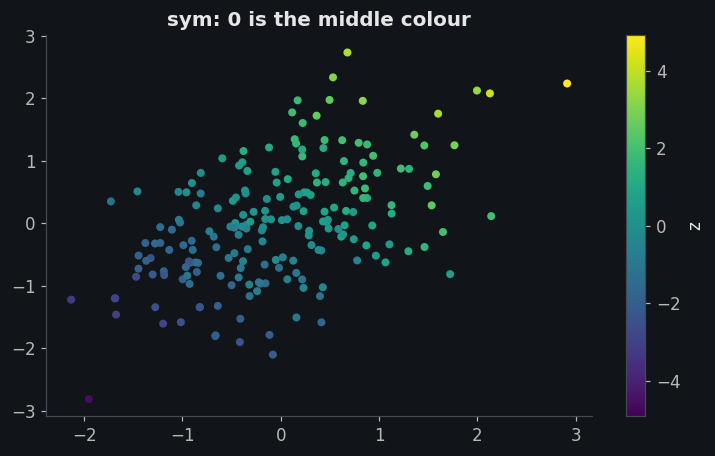

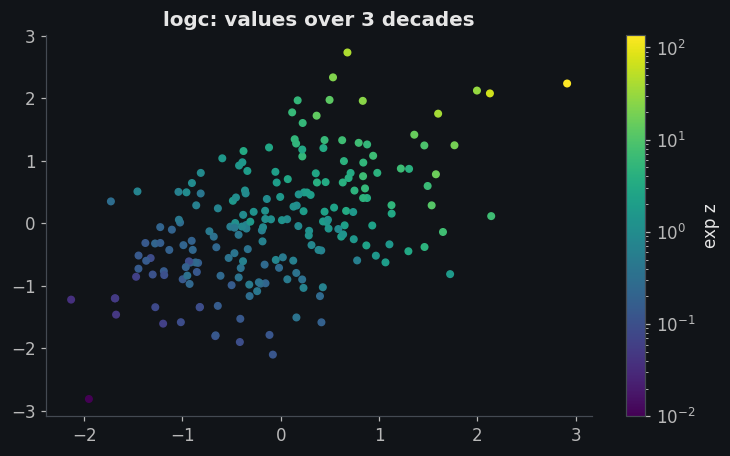

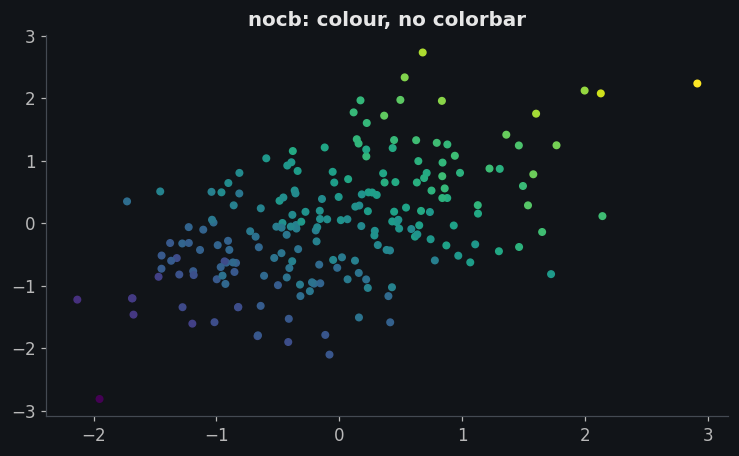

In [62]:
kx.plot(cloud.x, cloud.y, cloud.z, 'scatter-sym', title='sym: 0 is the middle colour');
kx.plot(cloud.x, cloud.y, np.exp(cloud.z).rename('exp z'), 'scatter-logc', title='logc: values over 3 decades');
kx.plot(cloud.x, cloud.y, cloud.z, 'scatter-nocb', title='nocb: colour, no colorbar');

### Reference lines: `diag`, `fit`

`diag` draws a dashed `y = x` line across the range both axes share: on it, the two values agree. `fit` draws the least-squares line, with its slope and R² in the legend; with a categorical `z`, one line per group in the group's colour. On a log axis a straight fit is a curve, so `fit` with `logx` or `logy` raises: fit the logs instead.

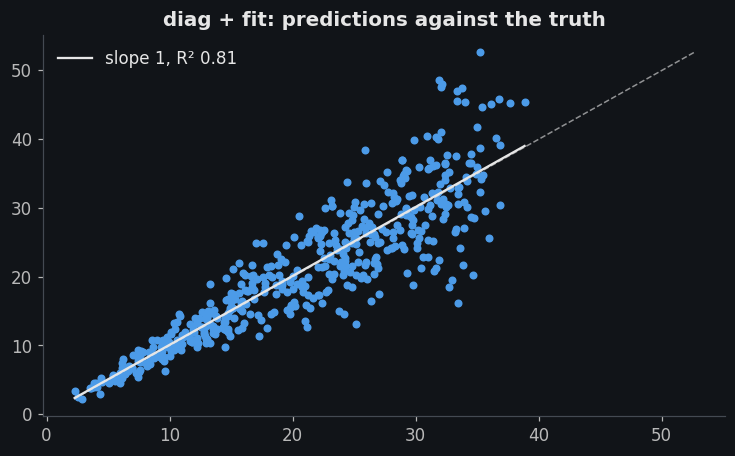

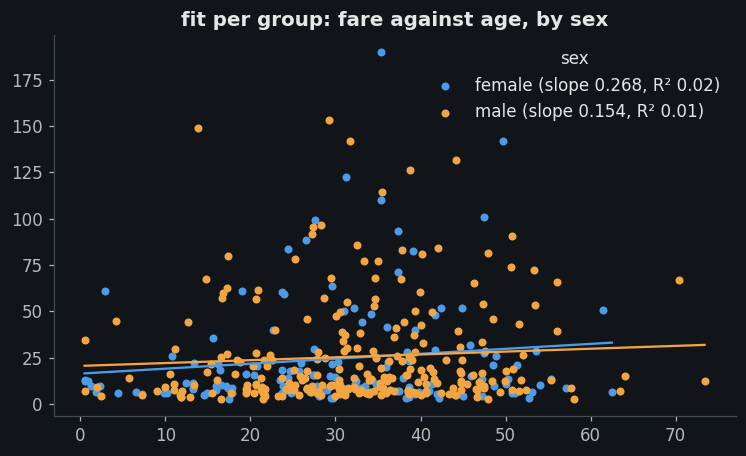

In [63]:
reg = kx.load('regression')
kx.plot(reg, 'actual', 'predicted', 'scatter-diag-fit', title='diag + fit: predictions against the truth');
kx.plot(passengers, 'age', 'fare', 'sex', 'scatter-fit', title='fit per group: fare against age, by sex');

## 6. Themes

| theme     | for                | what it sets                                                               |
|-----------|--------------------|----------------------------------------------------------------------------|
| `dark`    | notebooks          | dark background, muted colours                                             |
| `light`   | notebooks          | white background, tab10-style colours                                      |
| `paper`   | greyscale print    | black-to-grey colours paired with a linestyle cycle, serif, 300 dpi export |
| `science` | one journal column | 3.5 in wide, 8 pt serif, inward ticks on all sides, 600 dpi export         |
| `talk`    | slides             | 16:9, 18 pt sans, thick lines                                              |
| `poster`  | posters            | 12×9 in, 26 pt sans, very thick lines                                      |
| `thesis`  | A4 thesis          | 160 mm text width, Computer Modern 10/9 pt (no LaTeX needed), PDF export   |

There are three ways to use a theme:
- **`kx.use('paper')`** sets the default for the rest of the notebook. It resets matplotlib first, so themes never mix.
- **A theme token in the spec**, as in `'line-paper'`, styles that one plot and leaves the notebook default alone.
- **`with kx.context('paper'):`** styles everything in the block, several plots or a whole figure, and puts the previous settings back afterwards. It takes the same arguments as `kx.use`.

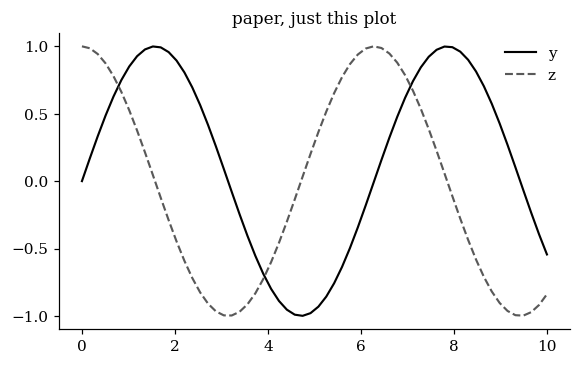

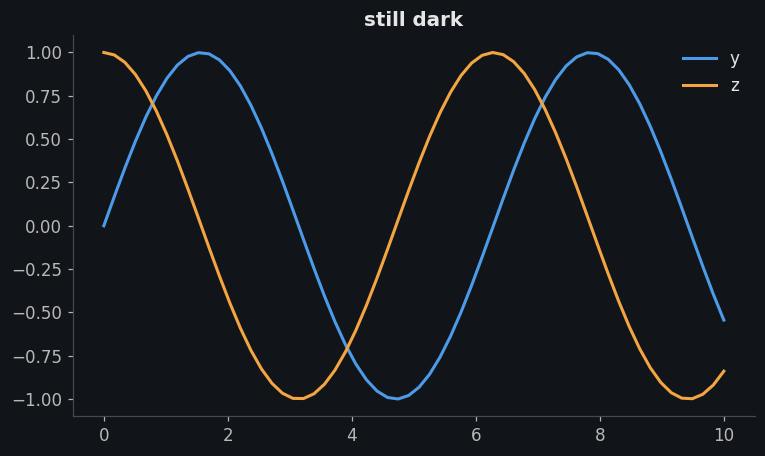

In [64]:
kx.plot(waves.x, waves.y, waves.z, 'line-paper-leg', title='paper, just this plot');
kx.plot(waves.x, waves.y, waves.z, 'line-leg', title='still dark');

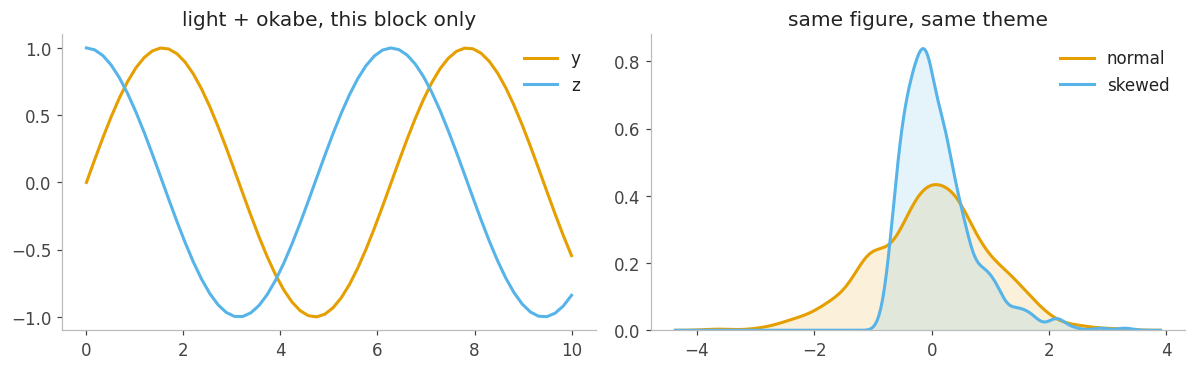

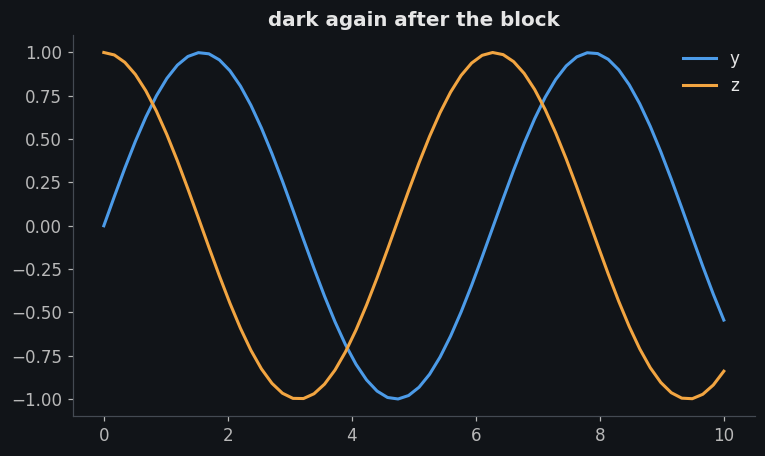

In [65]:
with kx.context('light', palette='okabe'):
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.5))
    kx.plot(waves.x, waves.y, waves.z, 'line-leg', title='light + okabe, this block only', ax=left)
    kx.plot(dists.normal, dists.skewed, spec='kde-leg', title='same figure, same theme', ax=right)
    fig.tight_layout()
kx.plot(waves.x, waves.y, waves.z, 'line-leg', title='dark again after the block');

Each theme at its own figure size:

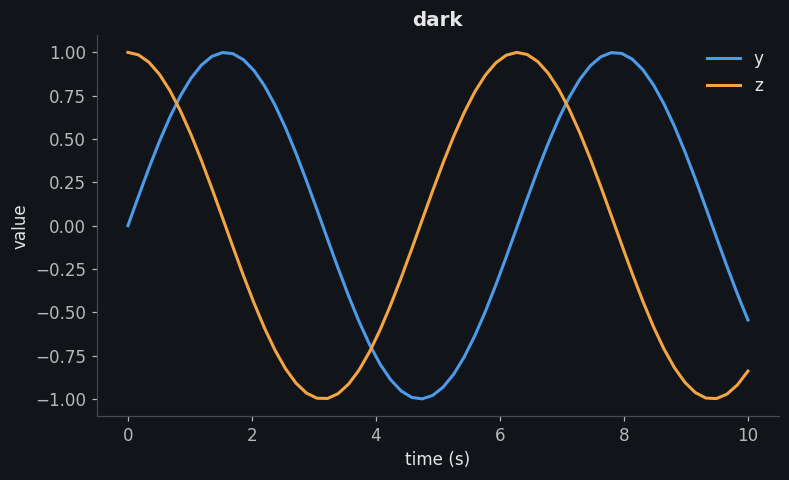

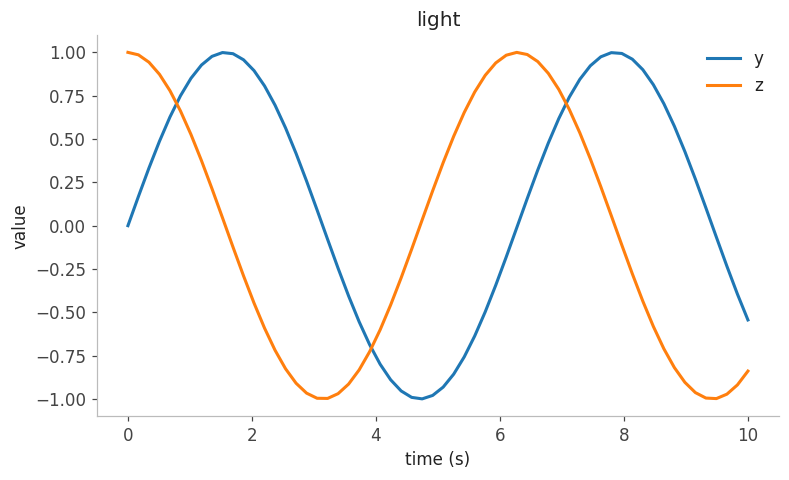

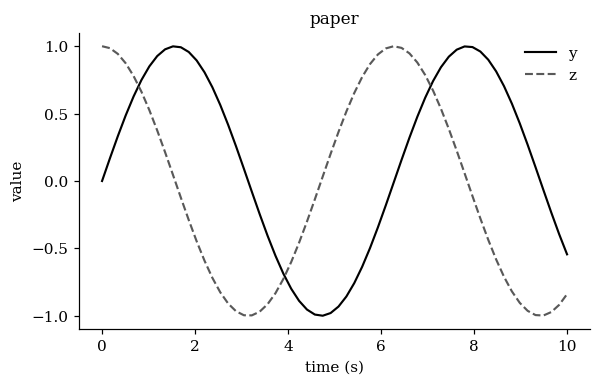

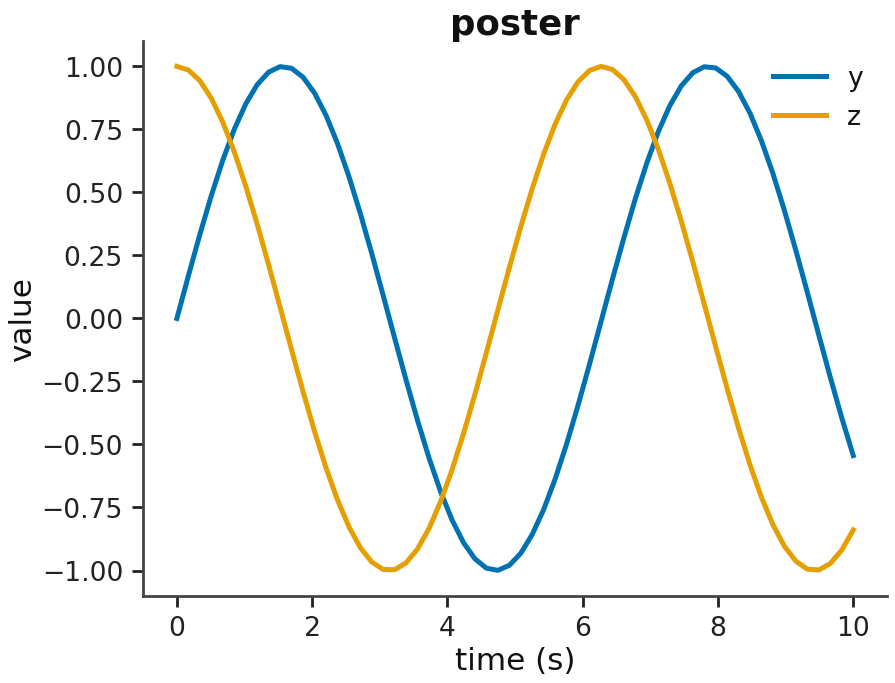

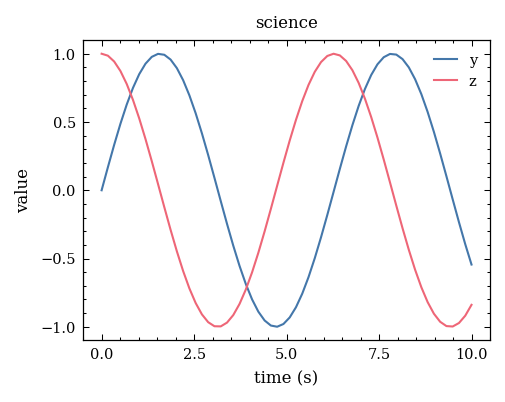

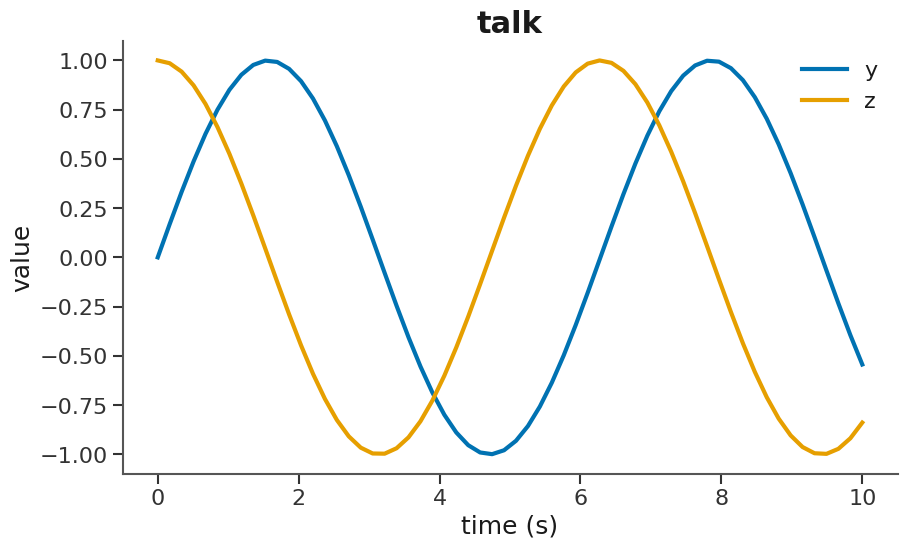

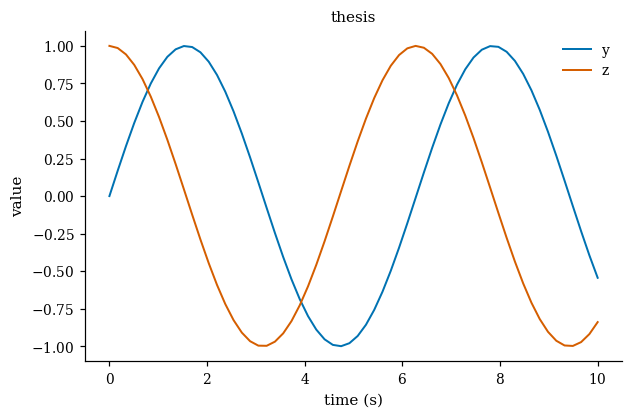

In [66]:
for theme in kx.styles():
    ax = kx.plot(waves.x, waves.y, waves.z, f'line-{theme}-leg', title=theme)
    ax.set_xlabel('time (s)'); ax.set_ylabel('value')
    plt.show()

Every kind in one theme, by passing `ax=` (see section 8):

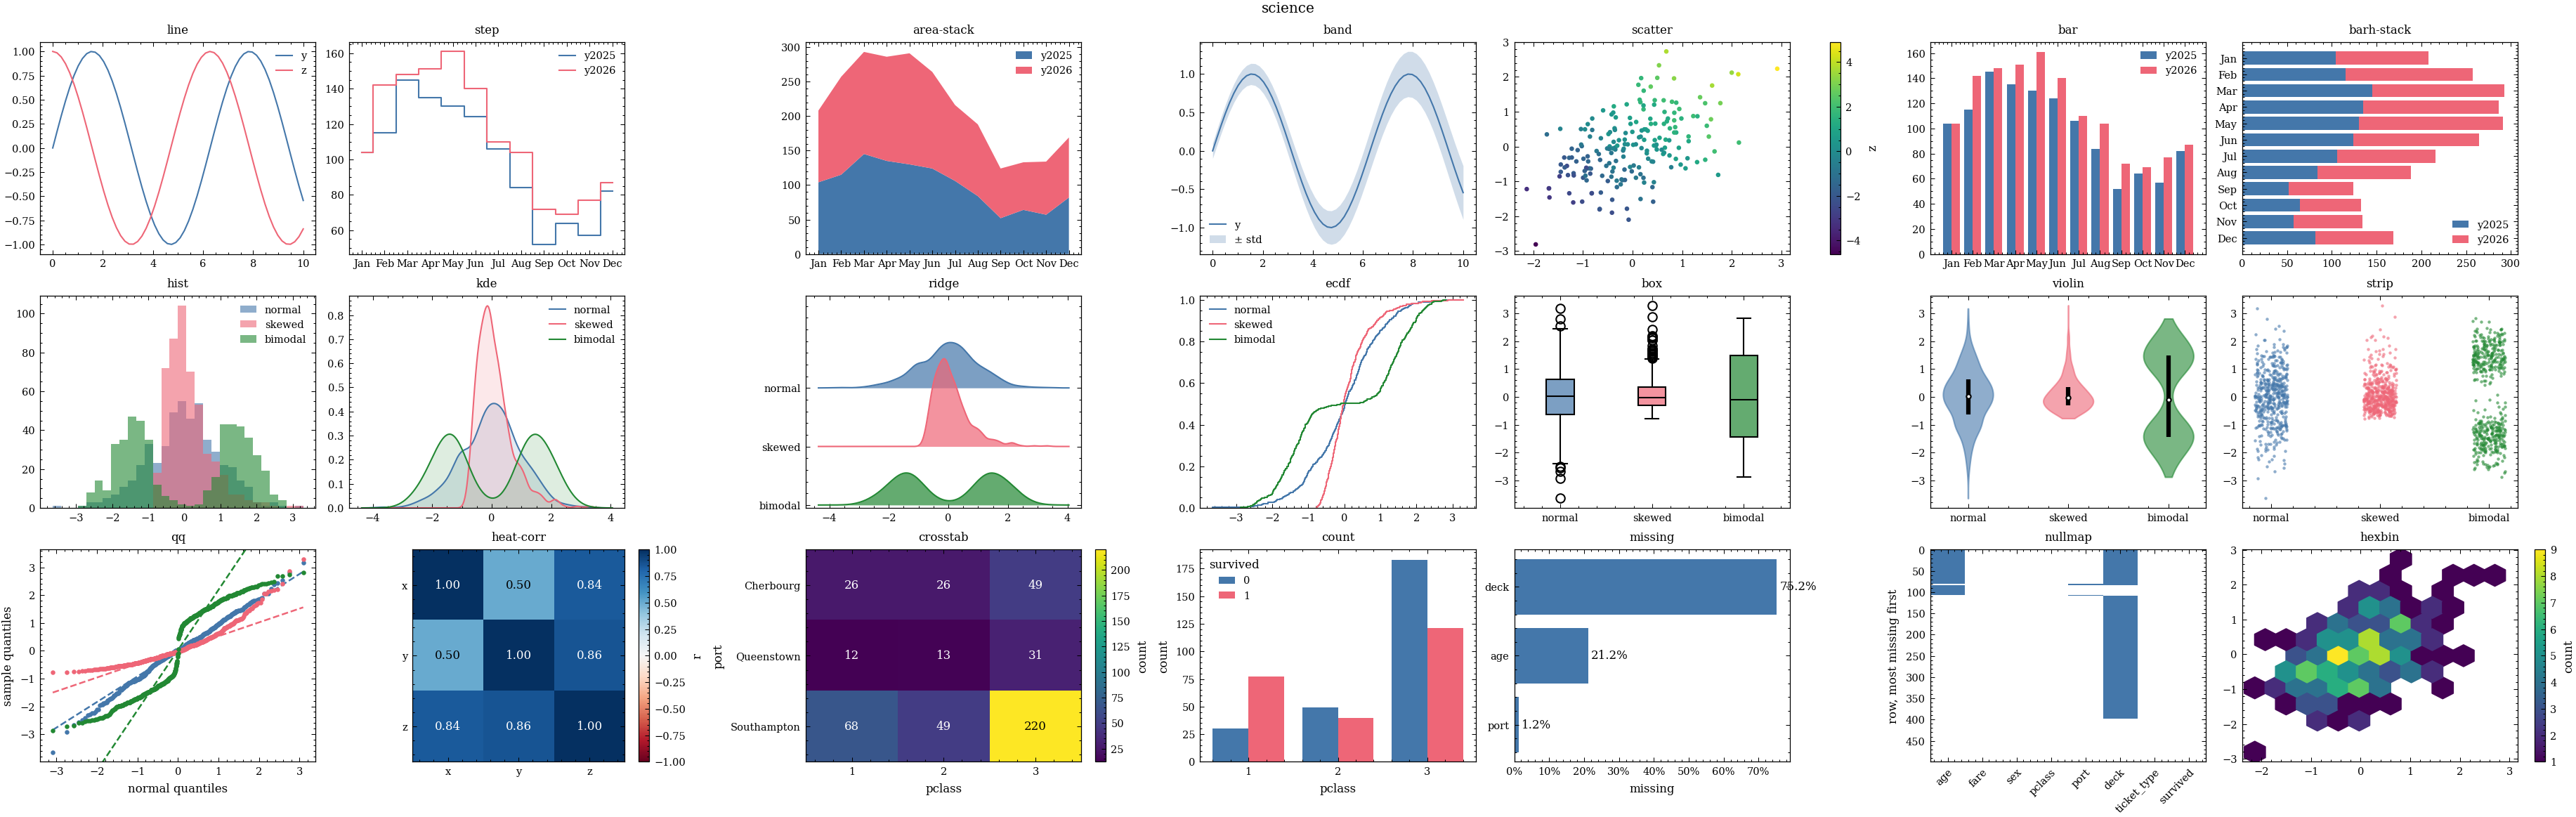

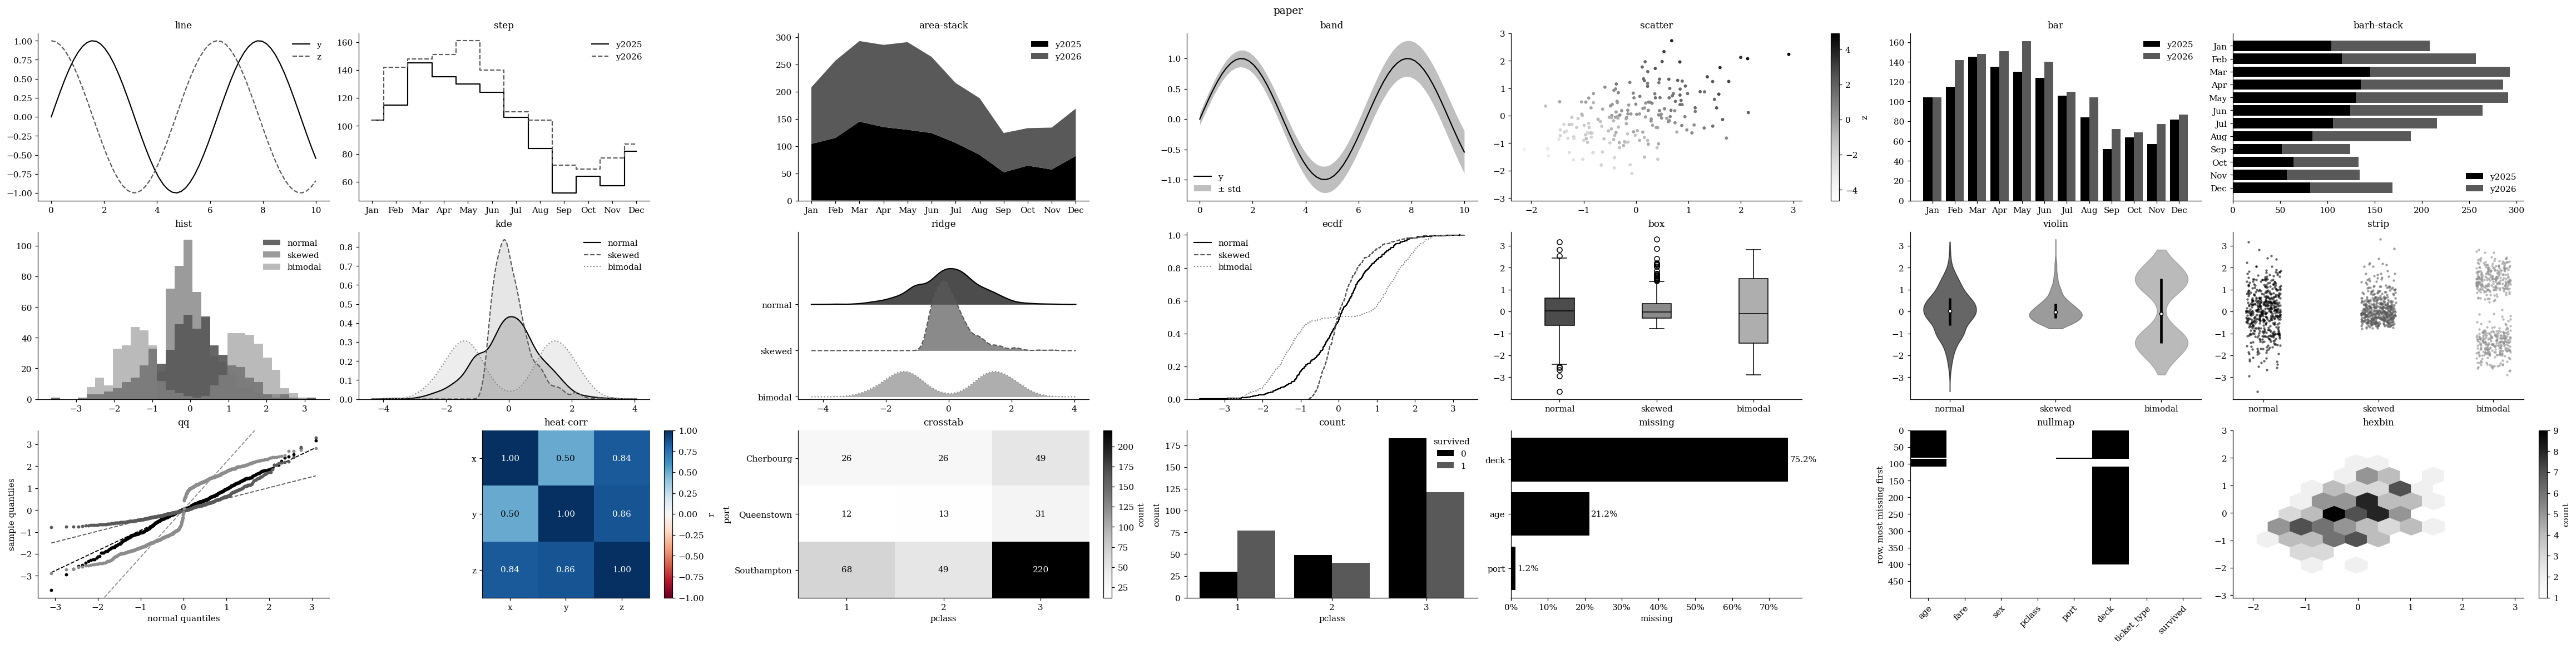

In [67]:
def overview(theme: str) -> None:
    kx.use(theme)
    a = iter(axs := kx.grid(21, cols=7))
    samples = (dists.normal, dists.skewed, dists.bimodal)
    kx.plot(waves.x, waves.y, waves.z, 'line-leg', title='line', ax=next(a))
    kx.plot(monthly.month, monthly.y2025, monthly.y2026, 'step-leg', title='step', ax=next(a))
    kx.plot(monthly.month, monthly.y2025, monthly.y2026, 'area-stack-leg', title='area-stack', ax=next(a))
    kx.plot(waves.x, waves.y, (0.1 + waves.x / 40).rename('std'), 'band-leg', title='band', ax=next(a))
    kx.plot(cloud.x, cloud.y, cloud.z, 'scatter', title='scatter', ax=next(a))
    kx.plot(monthly.month, monthly.y2025, monthly.y2026, 'bar-leg', title='bar', ax=next(a))
    kx.plot(monthly.month, monthly.y2025, monthly.y2026, 'barh-stack-leg', title='barh-stack', ax=next(a))
    for k in ('hist', 'kde', 'ridge', 'ecdf', 'box', 'violin', 'strip', 'qq'):
        kx.plot(*samples, spec=k + ('-leg' if k in ('hist', 'kde', 'ecdf') else ''), title=k, ax=next(a))
    kx.plot(cloud, 'heat-corr-ann', title='heat-corr', ax=next(a))
    kx.plot(passengers, 'pclass', 'port', 'crosstab-ann', title='crosstab', ax=next(a))
    kx.plot(passengers, 'pclass', spec='count-leg', by='survived', title='count', ax=next(a))
    kx.plot(passengers, 'missing-ann-wrap', title='missing', ax=next(a))
    kx.plot(passengers, 'nullmap-sort-rot', title='nullmap', ax=next(a))
    kx.plot(cloud.x, cloud.y, 'hexbin', gridsize=12, title='hexbin', ax=next(a))
    axs[0].figure.suptitle(theme); plt.show()

overview('science')
overview('paper')
kx.use('dark')

## 7. Palettes, colormaps and rcParams

### Palettes

`kx.use(theme, palette=...)` swaps the theme's colours for a **named palette** from `kx/styles/palettes/` (`kx.palettes()` lists them, `kx.palette(name)` returns the colours) or for your own list of colours.

| palettes                                            | source                                                                                     |
|-----------------------------------------------------|--------------------------------------------------------------------------------------------|
| `okabe`                                             | Okabe & Ito: 8 colours that stay distinguishable for every common type of colour blindness |
| `tolbright` `tolvibrant` `tollight` `tolhc` `tolmc` | Paul Tol                                                                                   |
| `petroff6` `petroff8` `petroff10`                   | Petroff (2021)                                                                             |
| `tab10` `tab20` `tableaucb`                         | Tableau; `tab20` has 20 colours, light/dark pairs                                          |
| `set1` `set2` `dark2` `paired`                      | ColorBrewer; `paired` has 12, light/dark pairs                                             |
| `ibm`                                               | IBM Design                                                                                 |

In [68]:
print(kx.palettes())
kx.palette('okabe')

['dark2', 'ibm', 'okabe', 'paired', 'petroff10', 'petroff6', 'petroff8', 'set1', 'set2', 'tab10', 'tab20', 'tableaucb', 'tolbright', 'tolhc', 'tollight', 'tolmc', 'tolvibrant']


['#E69F00',
 '#56B4E9',
 '#009E73',
 '#F0E442',
 '#0072B2',
 '#D55E00',
 '#CC79A7',
 '#000000']

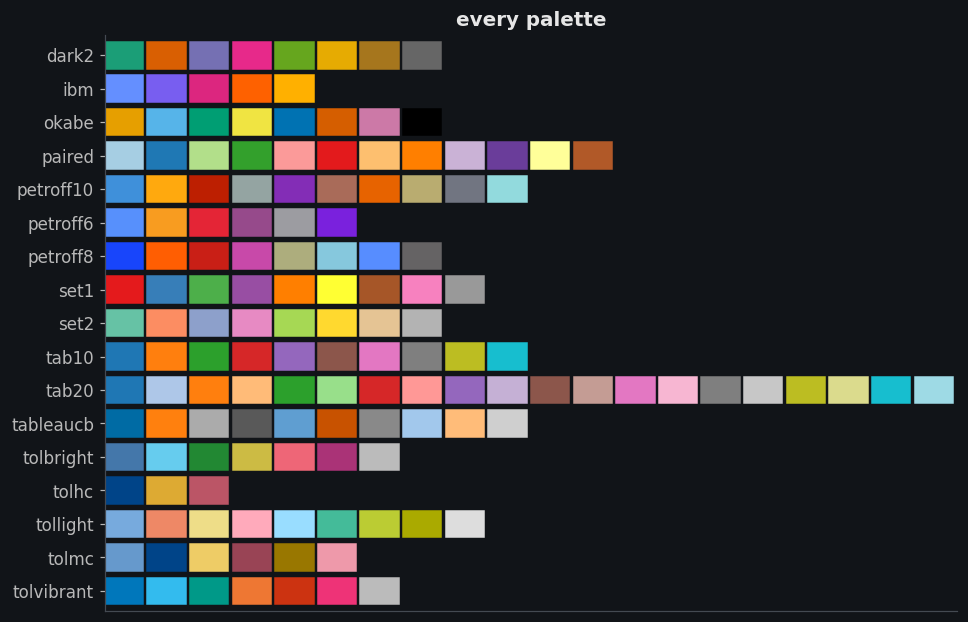

In [69]:
names = kx.palettes()
fig, ax = plt.subplots(figsize=(10, 0.4 * len(names)))
for row, name in enumerate(names):
    for col, c in enumerate(kx.palette(name)):
        ax.add_patch(plt.Rectangle((col, row), 0.9, 0.8, color=c))
ax.set_xlim(0, 20); ax.set_ylim(len(names), -0.2)
ax.set_yticks([r + 0.4 for r in range(len(names))], names); ax.set_xticks([])
ax.set_title('every palette');

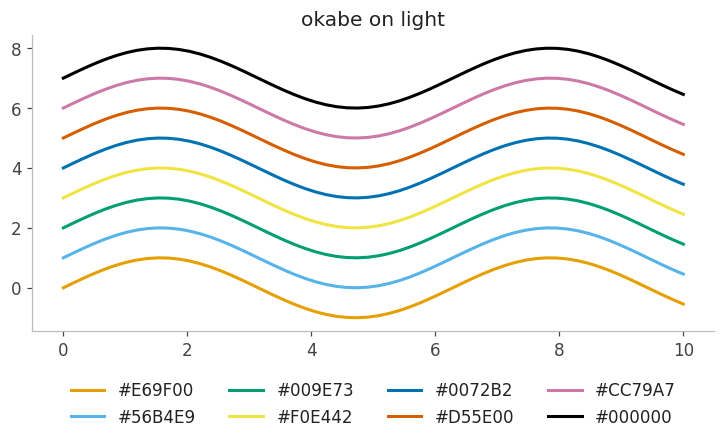

In [70]:
kx.use('light', palette='okabe')
fig, ax = plt.subplots(figsize=(8, 3.5))
for i, c in enumerate(kx.palette('okabe')):
    ax.plot(waves.x, waves.y + i, label=c)
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.12)); ax.set_title('okabe on light');

Only the colours change. Other properties the theme cycles through stay, such as `paper`'s linestyles, so `paper` + `okabe` gives colour for screens and dash patterns for greyscale print.

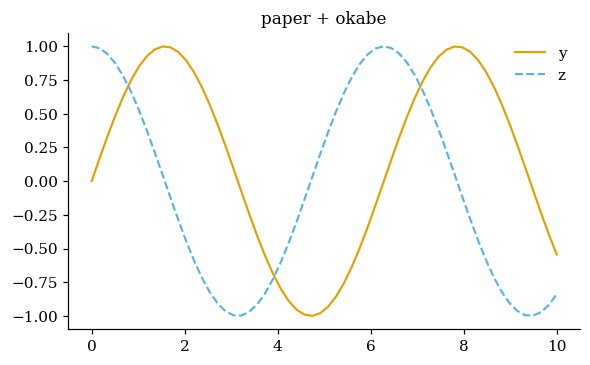

In [71]:
kx.use('paper', palette='okabe')
kx.plot(waves.x, waves.y, waves.z, 'line-leg', title='paper + okabe');

### Colormaps

`kx.use(theme, cmap=...)` sets the colormap used for continuous colour, such as `scatter` with `z`. `kx.cmaps()` lists the supported ones that your matplotlib version has (`berlin`, `managua` and `vanimo` need matplotlib 3.10 or newer). The cmocean and Crameri ones are vendored in `kx/styles/cmaps/`, so they work with any matplotlib.

| type                   | cmaps                                                  | use for                                                                                       |
|------------------------|--------------------------------------------------------|-----------------------------------------------------------------------------------------------|
| sequential             | `viridis` `magma` `plasma` `inferno` `cividis` `turbo` | low → high values (`cividis` is colour-blind safe; `turbo` is a rainbow, for spotting detail) |
| sequential, cmocean    | `thermal` `haline` `deep`                              | temperature, salinity, depth                                                                  |
| sequential, Crameri    | `batlow` `lipari` `hawaii` `oslo` `davos`              | low → high, perceptually uniform and colour-blind friendly                                    |
| cyclic                 | `twilight` `romaO`                                     | angles, phase, time of day                                                                    |
| diverging              | `coolwarm` `balance` `vik` `roma` `bam` `cork`         | values around a midpoint such as 0                                                            |
| diverging, dark centre | `berlin` `managua` `vanimo`                            | as above, on light backgrounds                                                                |

`berlin`, `managua` and `vanimo` are dark in the middle, so on the `dark` theme values near 0 fade into the background. Use `coolwarm` or `vik` there, or pair the dark-centred ones with `light`.

Add `_r` to any name to reverse it: `cmap='batlow_r'`.

In [72]:
import matplotlib
print('matplotlib', matplotlib.__version__)
kx.cmaps()

matplotlib 3.10.0


['balance',
 'bam',
 'batlow',
 'berlin',
 'blues',
 'cividis',
 'coolwarm',
 'cork',
 'davos',
 'deep',
 'greys',
 'haline',
 'hawaii',
 'inferno',
 'lipari',
 'magma',
 'managua',
 'oslo',
 'plasma',
 'rdbu',
 'roma',
 'romaO',
 'thermal',
 'turbo',
 'twilight',
 'vanimo',
 'vik',
 'viridis']

`cmap=` just sets matplotlib's `image.cmap`, so for one-off panels inside a figure `plt.rc_context` does the same job:

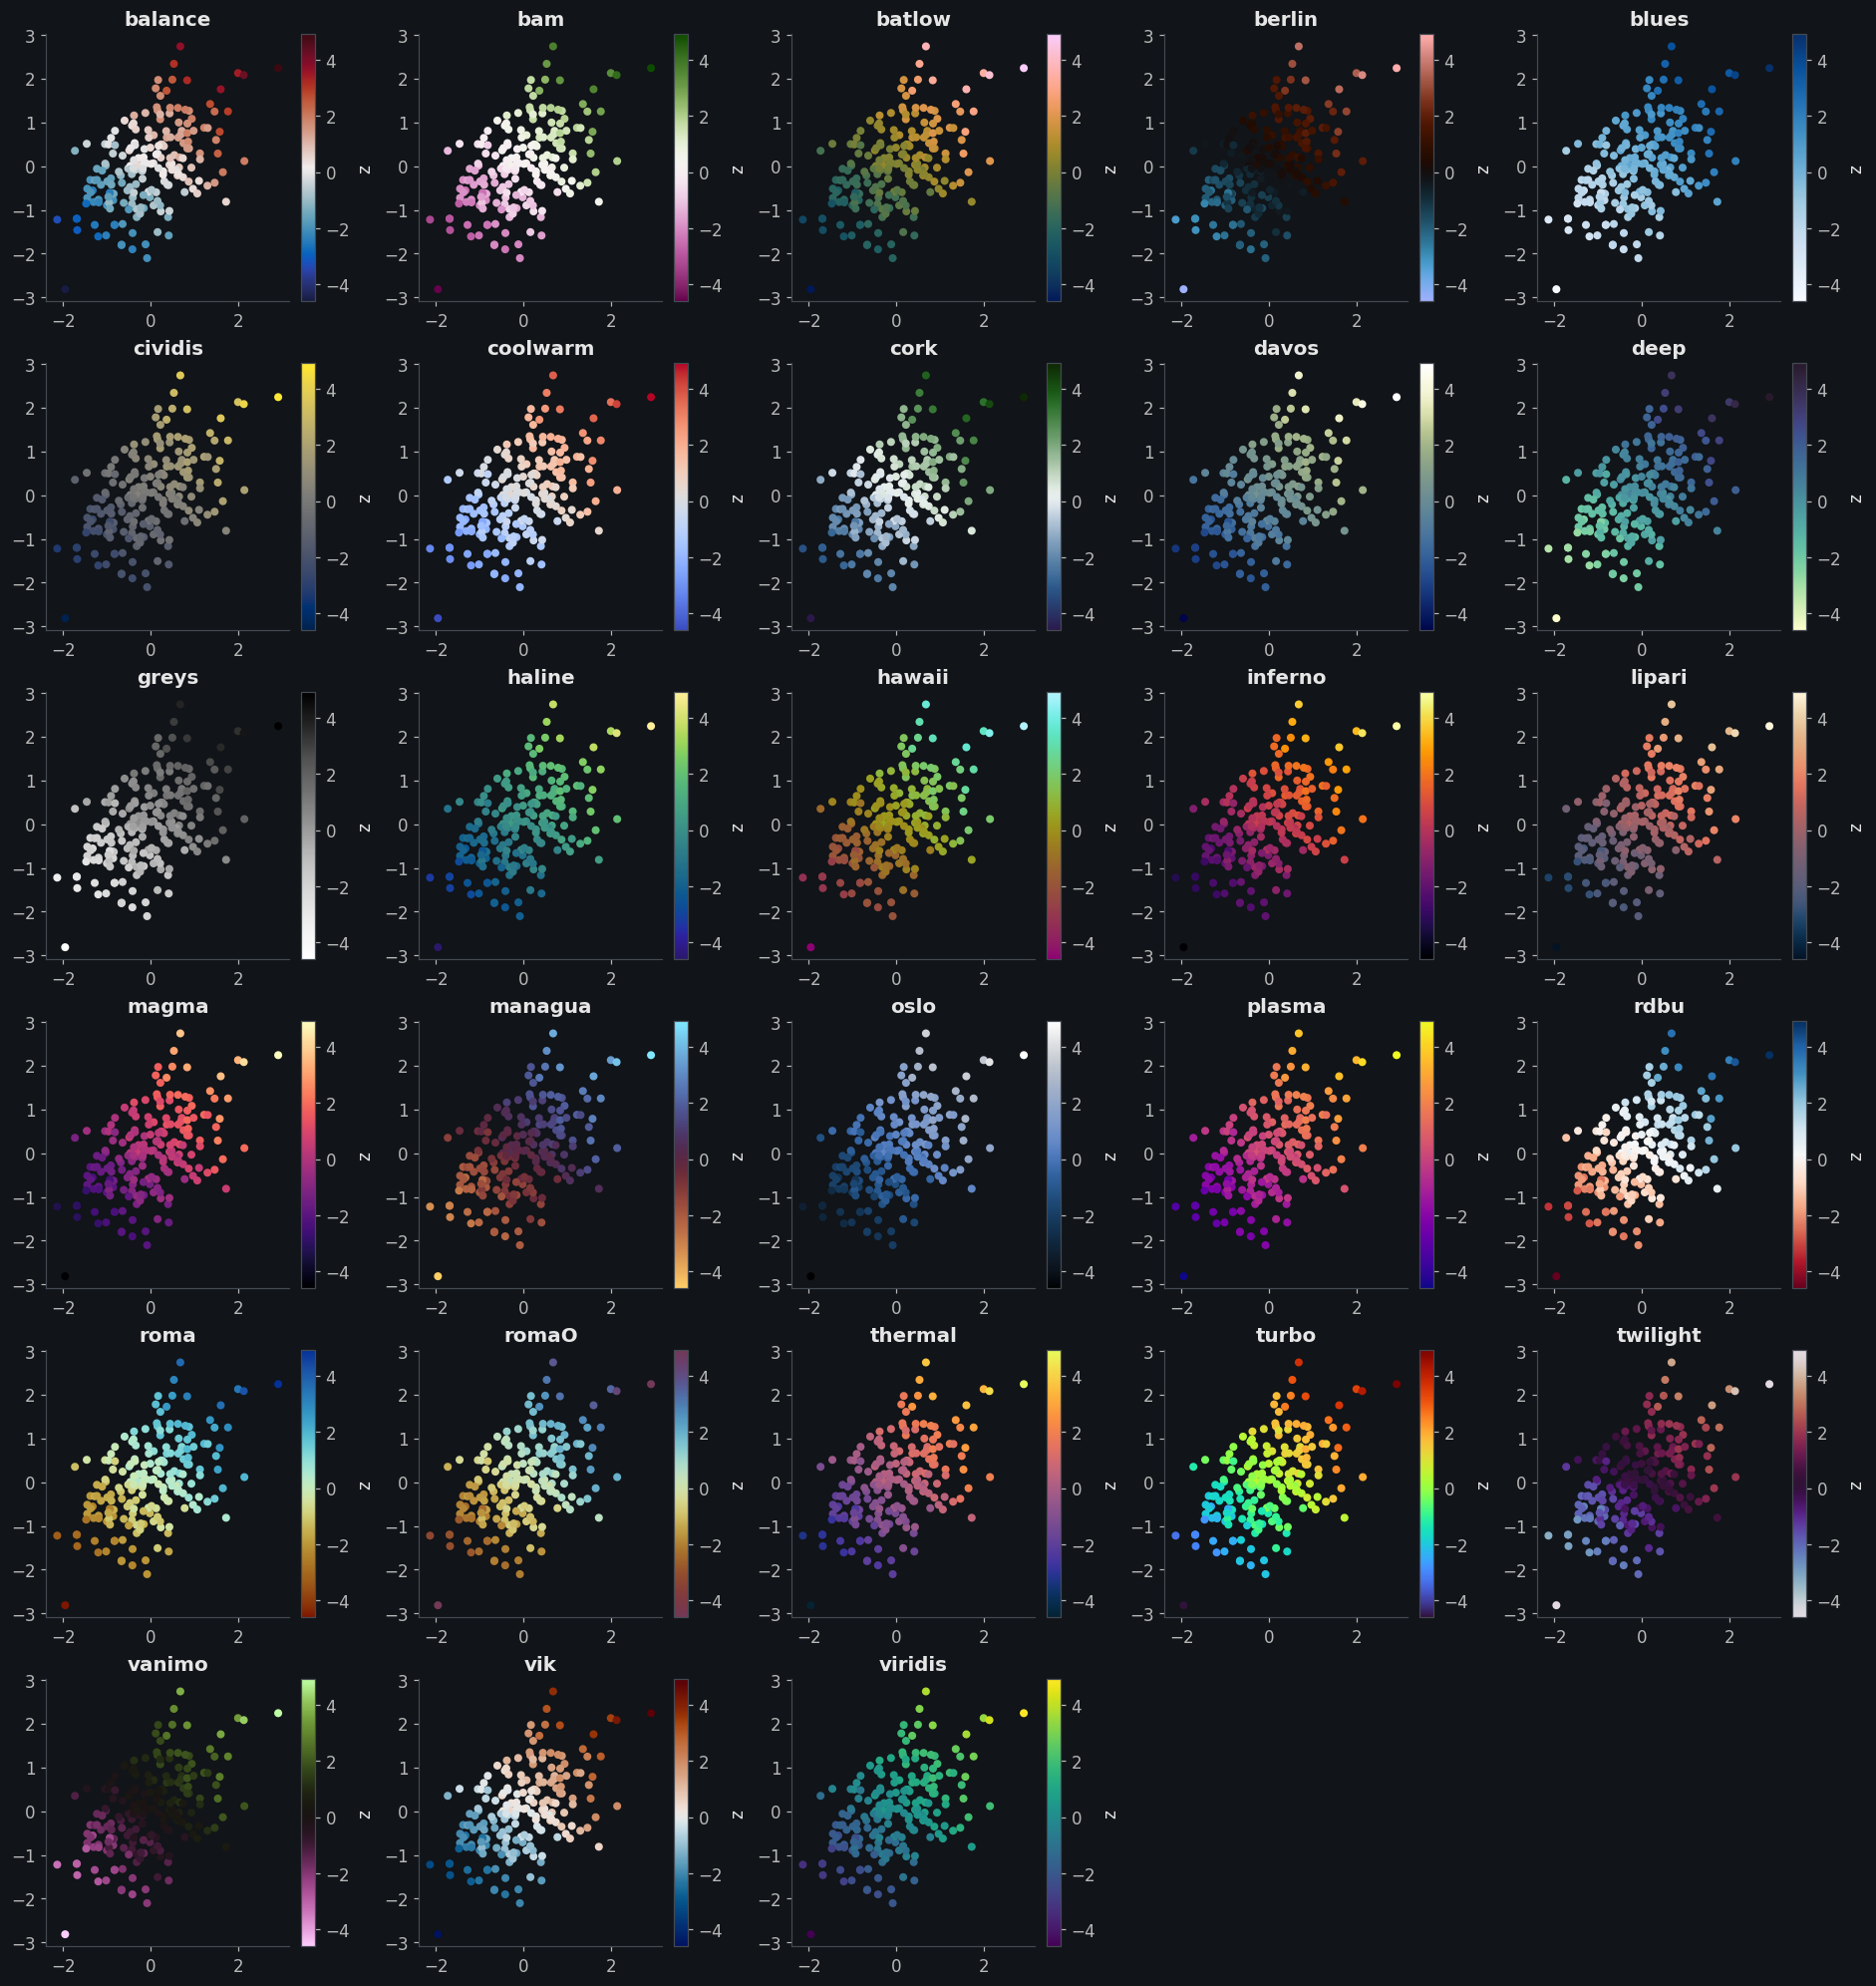

In [73]:
kx.use('dark')
names = kx.cmaps()
for ax, name in zip(kx.grid(len(names), cols=5, figsize=(17, 3 * -(-len(names) // 5))), names):
    with plt.rc_context({'image.cmap': name}):
        kx.plot(cloud.x, cloud.y, cloud.z, 'scatter', title=name, ax=ax)

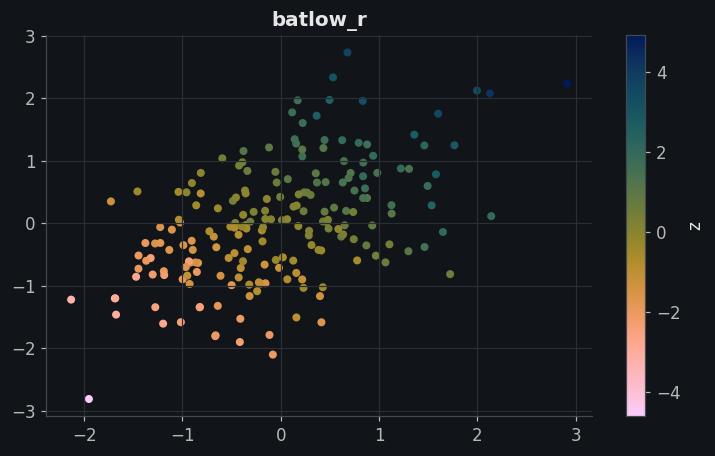

In [74]:
kx.use('dark', cmap='batlow_r')                    # '_r' reverses any colormap in kx.cmaps()
kx.plot(cloud.x, cloud.y, cloud.z, 'scatter-grid', title='batlow_r');

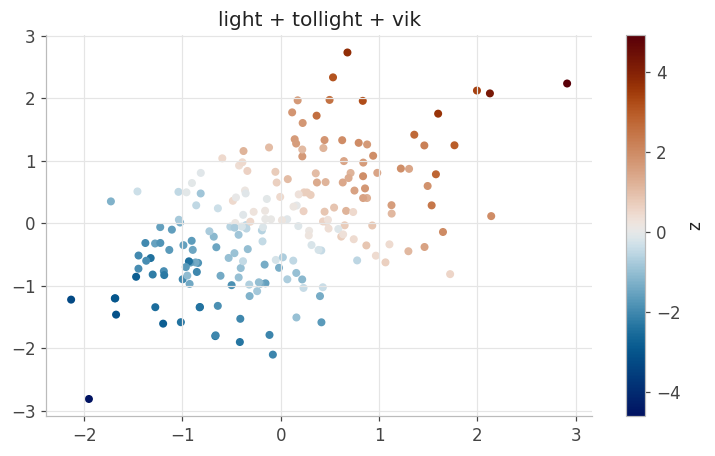

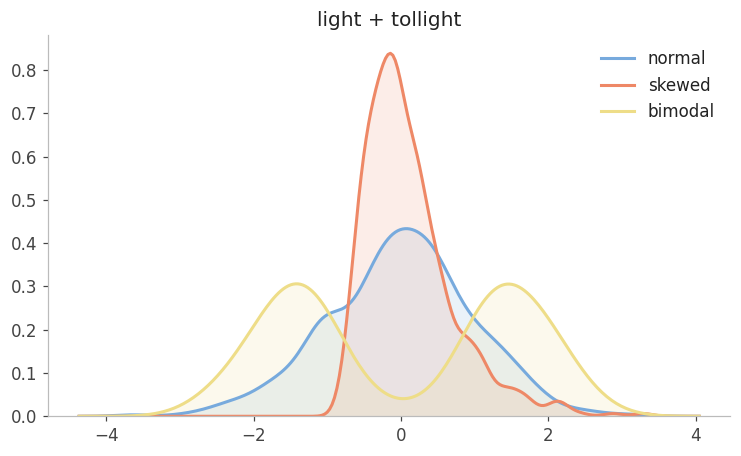

In [75]:
kx.use('light', palette='tollight', cmap='vik')   # theme, palette and colormap together
kx.plot(cloud.x, cloud.y, cloud.z, 'scatter-grid', title='light + tollight + vik');
kx.plot(dists.normal, dists.skewed, dists.bimodal, 'kde-leg', title='light + tollight');

### rcParams

Any rcParam can also be passed as a keyword. Write the dots in rcParam names as double underscores: `figure__figsize` means `figure.figsize`.

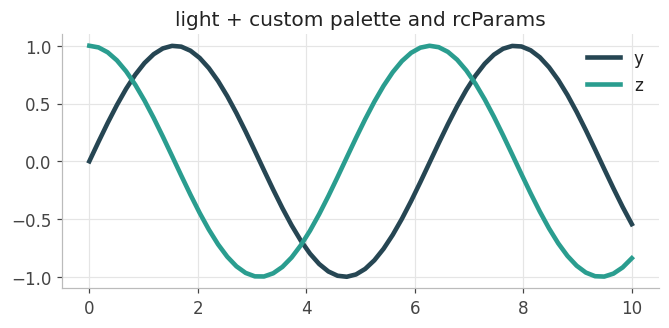

In [76]:
kx.use('light', palette=['#264653', '#2a9d8f', '#e76f51'],   # or your own colours
       figure__figsize=(7, 3), lines__linewidth=3, axes__grid=True)
kx.plot(waves.x, waves.y, waves.z, 'line-leg', title='light + custom palette and rcParams');
kx.use('dark')

## 8. Subplots with `ax=` and `kx.grid`

Pass `ax=` to draw into your own layout. `kx.plot` returns that axis.

`kx.grid(n, cols=3)` makes the layout for you: a figure of `n` panels as a flat array of axes, each panel the size of one plot in the current theme, with the empty cells of the last row removed. Other keywords go to `plt.subplots`, e.g. `sharex=True` or `figsize=`. It uses constrained layout, which leaves room for colorbars and outside legends, so no `tight_layout()` is needed.

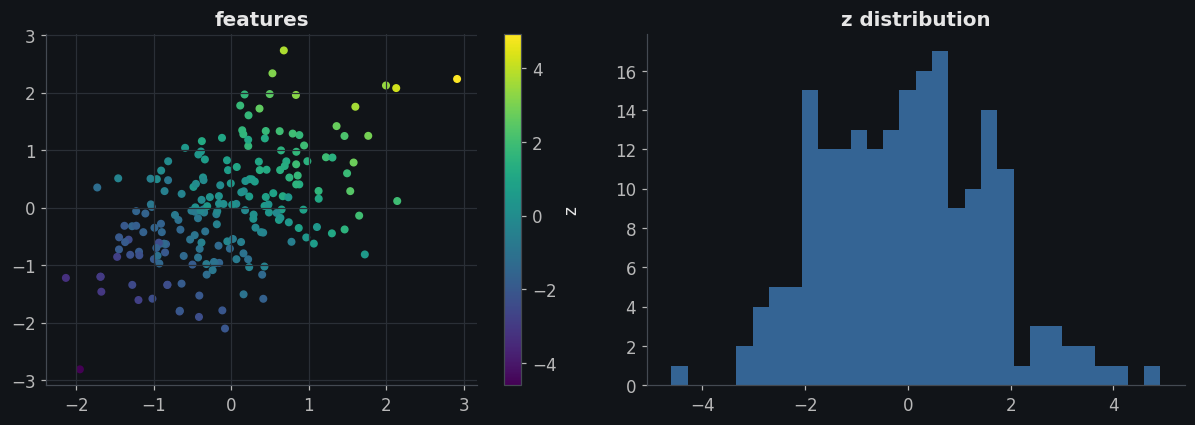

In [77]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
kx.plot(cloud.x, cloud.y, cloud.z, 'scatter-grid', title='features', ax=left)
kx.plot(cloud.z, spec='hist', title='z distribution', ax=right)
fig.tight_layout()

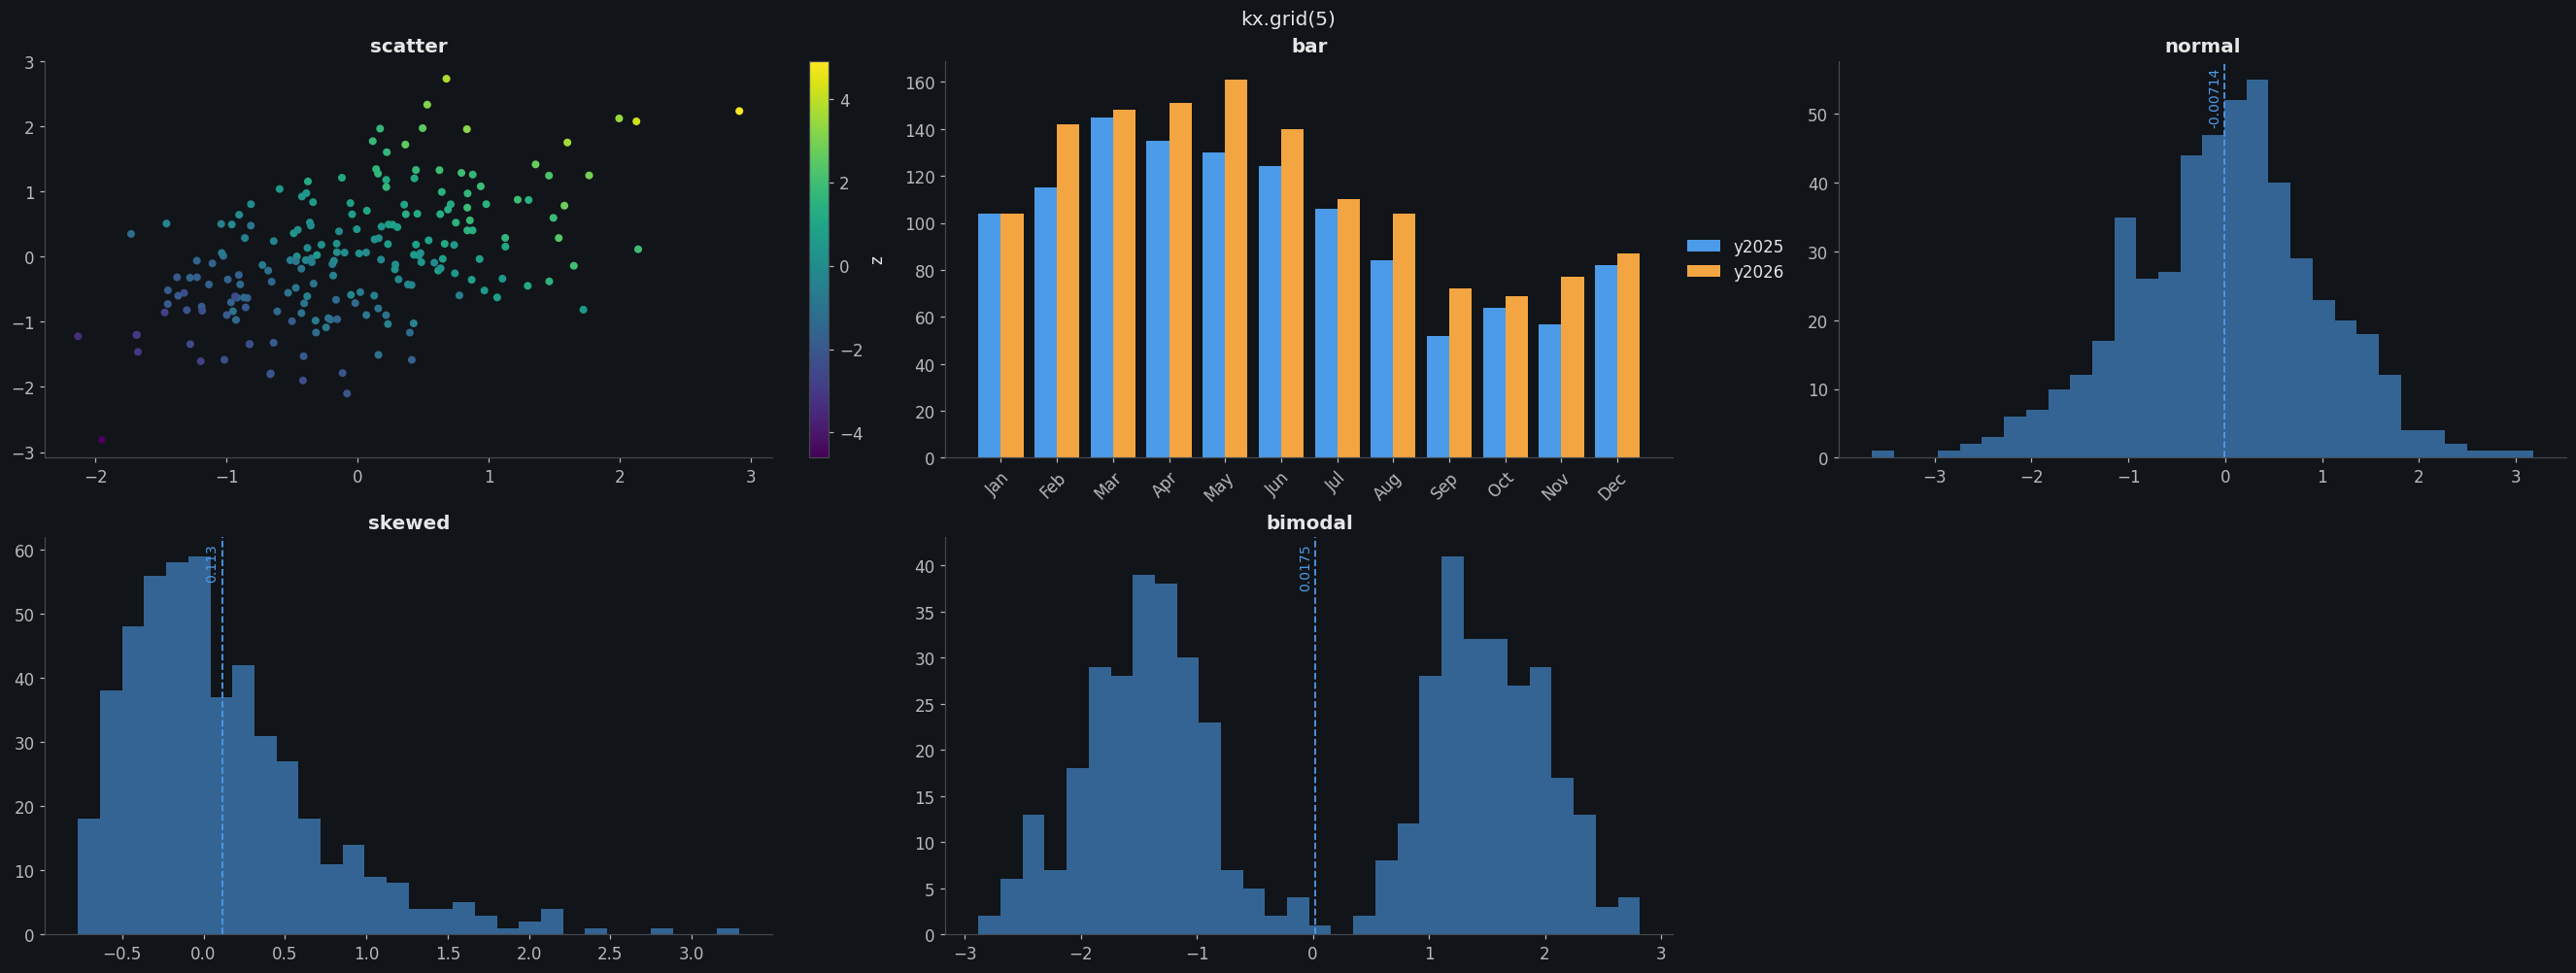

In [78]:
axs = kx.grid(5)                                    # 3 per row: 3 + 2, the 6th cell removed
kx.plot(cloud, 'x', 'y', 'z', 'scatter', title='scatter', ax=axs[0])
kx.plot(monthly, 'month', 'y2025', 'y2026', 'bar-legout-rot', title='bar', ax=axs[1])
for ax, col in zip(axs[2:], dists.columns):
    kx.plot(dists, col, spec='hist-mean-ann', title=col, ax=ax)
axs[0].figure.suptitle('kx.grid(5)');

## 9. Saving figures

`kx.save('name.png')` saves the current figure and returns the path. Kaggle only keeps files written to `/kaggle/working`, so there a relative name goes into that folder; elsewhere it goes into the current folder. Missing folders are created, and other keywords go to `savefig`. Pass `ax` (or a figure) to save a figure that isn't the current one, for example after `plt.show()`.

The print themes come with sensible save settings: `paper` saves at 300 dpi, `science` at 600 dpi, and `thesis` saves a vector PDF when the name has no extension. Draw and save inside `with kx.context(...)` so those settings are active when you save.

/kaggle/working/figure_science.png


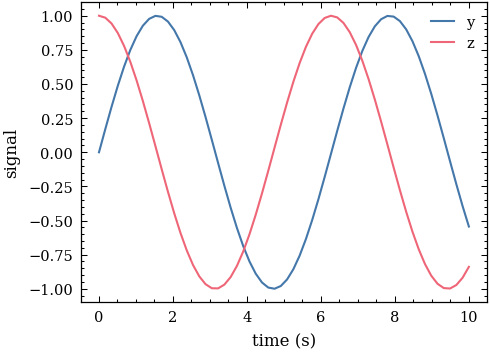

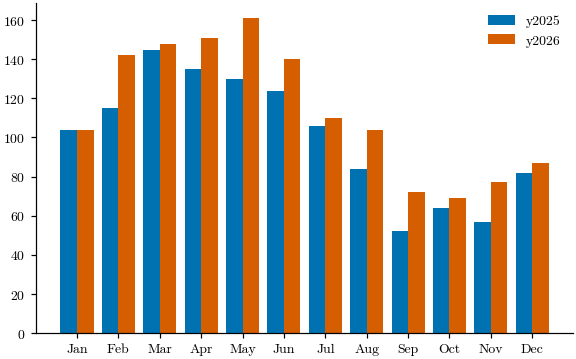

/kaggle/working/figure_thesis.pdf


In [79]:
with kx.context('science'):
    ax = kx.plot(waves.x, waves.y, waves.z, 'line-leg')
    ax.set_xlabel('time (s)'); ax.set_ylabel('signal')
    print(kx.save('figure_science.png'))      # 600 dpi, tight bbox, white background
    plt.show()

with kx.context('thesis'):
    ax = kx.plot(monthly.month, monthly.y2025, monthly.y2026, 'bar-leg')
    plt.show()
    print(kx.save('figure_thesis', ax))       # after show: pass ax; no extension -> PDF

## 10. Strict errors

Unknown tokens, two kinds, two themes, a flag on a kind that doesn't support it (such as `cum` outside `hist`), flags that ask for opposite things (such as `pct` and `si`), an unknown colormap, or a missing required `z` raise a `ValueError` instead of being guessed at. A mistyped token gets the closest valid ones as a hint.

In [80]:
for spec in ('line-nope', 'line-lgo', 'scater-drak', 'line--dark', 'line-scatter', 'dark-light', 'line-stack', 'line-cum', 'kde-stack', 'band', 'area-norm',
             'line-pct-si', 'line-logy-logxy', 'line-sort', 'hist-ann', 'scatter-nocb'):
    try:
        kx.plot(waves.x, waves.y, spec=spec)
    except ValueError as e:
        print(f'{spec!r:18} {e}')
try:
    kx.use('dark', cmap='rainbow')
except ValueError as e:
    print(f"{'cmap=rainbow':18} {e}")
plt.close('all')

'line-nope'        unknown tokens: ['nope']. Run kx.grammar() to see valid ones.
'line-lgo'         unknown tokens: ['lgo']. Did you mean 'leg' or 'legout' for 'lgo'? Run kx.grammar() to see valid ones.
'scater-drak'      unknown tokens: ['scater', 'drak']. Did you mean 'poster' or 'scatter' for 'scater', 'dark' for 'drak'? Run kx.grammar() to see valid ones.
'line--dark'       unknown tokens: ['']. An empty token means a '-' too many. Run kx.grammar() to see valid ones.
'line-scatter'     spec 'line-scatter' has more than one kind: ['line', 'scatter']
'dark-light'       spec 'dark-light' has more than one theme: ['dark', 'light']
'line-stack'       flag 'stack' only works with kind ['area', 'bar', 'barh', 'count', 'hist'], not 'line'
'line-cum'         flag 'cum' only works with kind ['hist'], not 'line'
'kde-stack'        flag 'stack' only works with kind ['area', 'bar', 'barh', 'count', 'hist'], not 'kde'
'band'             kind 'band' needs z: the half-width of the band (y - z to y

## 11. Tables: a first look at a dataset

`passengers` is 500 made-up passengers, built so the first questions about a new dataset have answers: what is missing, how the categories split, and what goes with what. Survival depends on sex, class and age, and the cabin deck is mostly unknown outside first class.

`heat`, `missing` and `nullmap` take the whole table and no column names. For some columns, pass `df[cols]`.

In [81]:
passengers.head()

,age,fare,sex,pclass,port,deck,ticket_type,survived
0,52.4,7.49,male,3,Southampton,NaN,standard single journey,1
1,37.2,25.81,male,3,Southampton,NaN,family return ticket,0
2,NaN,30.99,male,3,Southampton,NaN,standard single journey,0
3,NaN,50.07,female,1,Southampton,G,first class saloon pass,1
4,12.4,11.12,female,3,Southampton,NaN,family return ticket,1


### What is missing: `missing`, `kx.missing`, `nullmap`

`missing` shows the share of NaNs per column, the most missing on top. Columns with nothing missing are left out, unless the spec has `all`. `kx.missing(df)` is short for `kx.plot(df, 'missing-ann')`.

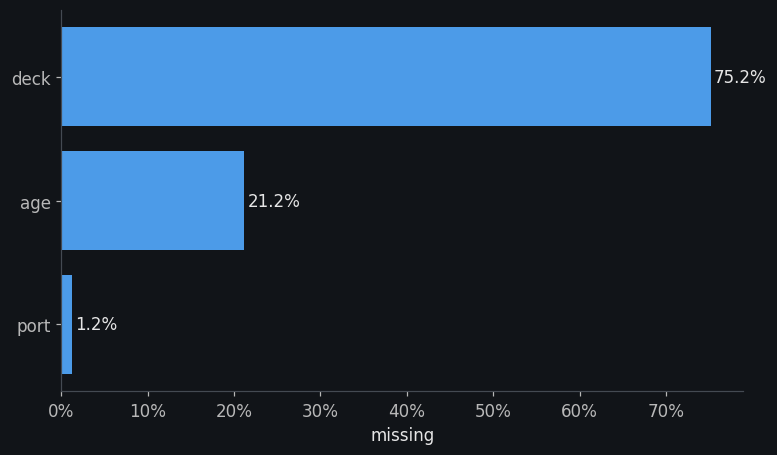

In [82]:
kx.missing(passengers);

`nullmap` shows *where* the gaps are: one row of pixels per row of the table, the missing cells coloured. With `sort`, rows with the same gaps end up together. The `deck` block shows that `deck` is missing for most rows, while `age` is missing for some rows regardless of `deck`.

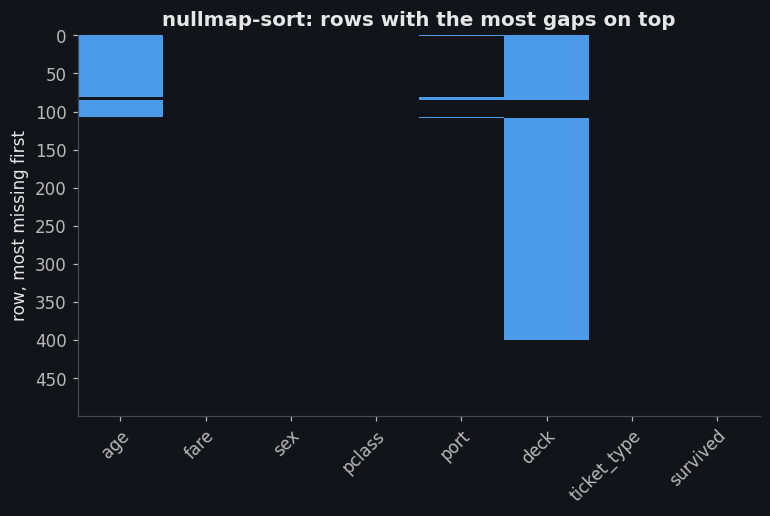

In [83]:
kx.plot(passengers, 'nullmap-sort-rot', title='nullmap-sort: rows with the most gaps on top');

### Categories: `count`, `crosstab`

`count` counts the rows per category, and `by=` splits each bar. With `stack-norm`, each bar becomes 100% and shows the share of each group. `wrap` breaks long labels onto several lines.

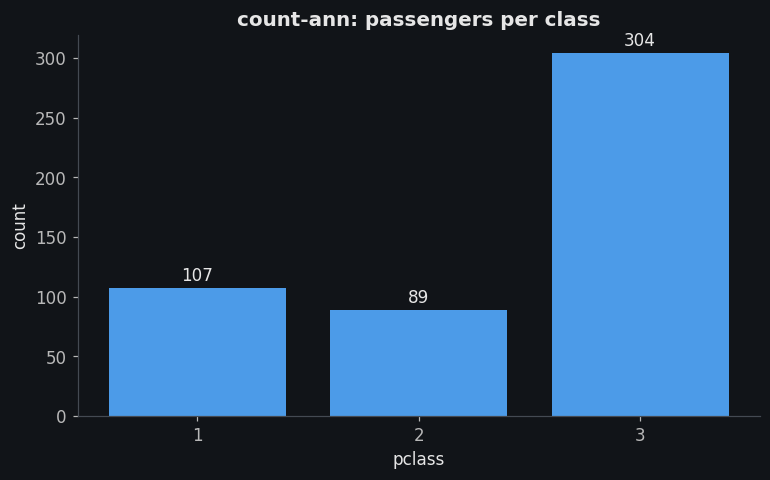

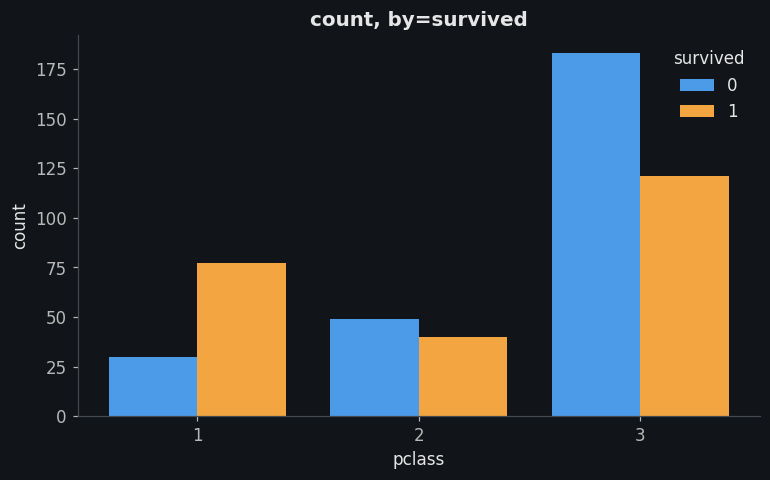

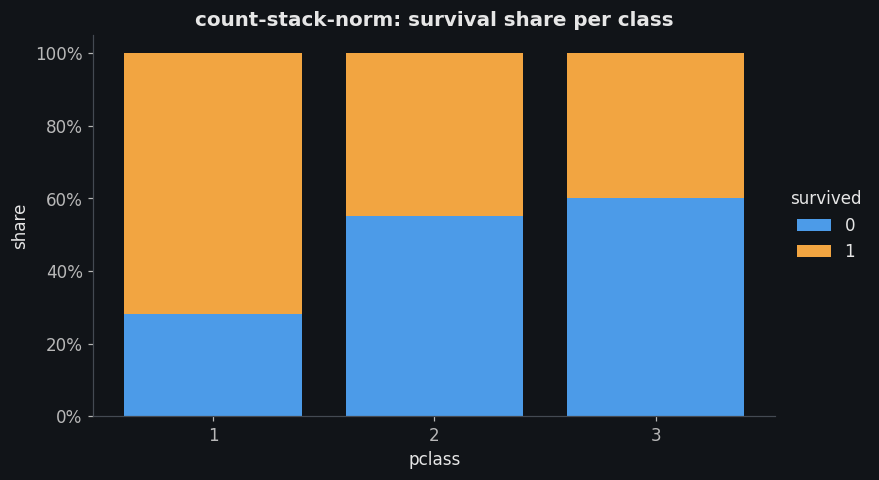

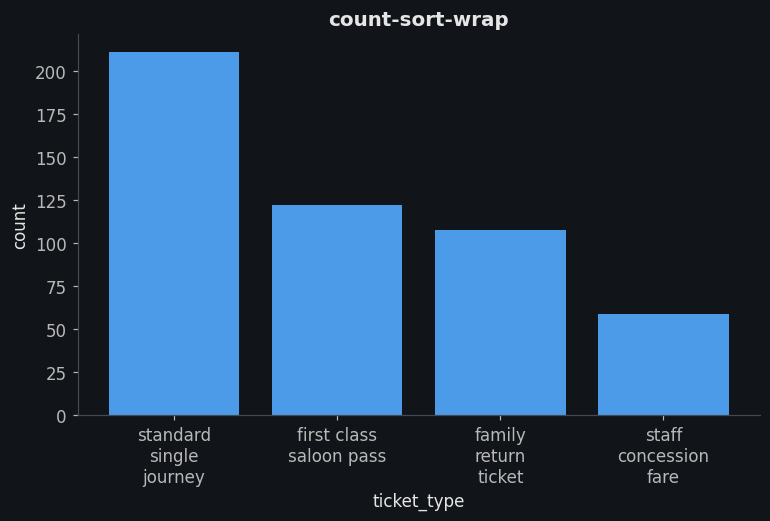

In [84]:
kx.plot(passengers, 'pclass', spec='count-ann', title='count-ann: passengers per class');
kx.plot(passengers, 'pclass', spec='count-leg', by='survived', title='count, by=survived');
kx.plot(passengers, 'pclass', spec='count-stack-norm-leg', by='survived', title='count-stack-norm: survival share per class');
kx.plot(passengers, 'ticket_type', spec='count-sort-wrap', title='count-sort-wrap');

`crosstab` counts the pairs of two categorical columns, like `pd.crosstab(y, x)` drawn as a heat map. With `norm`, each column adds up to 100%, so you compare the mix of `y` within each `x`.

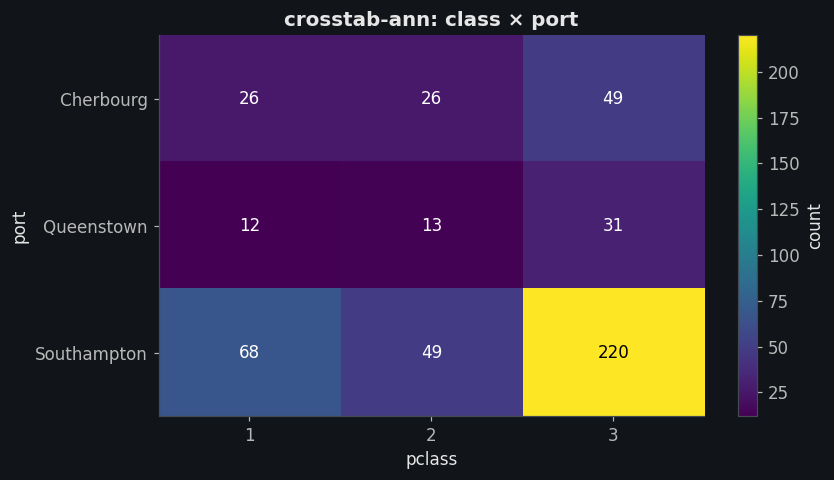

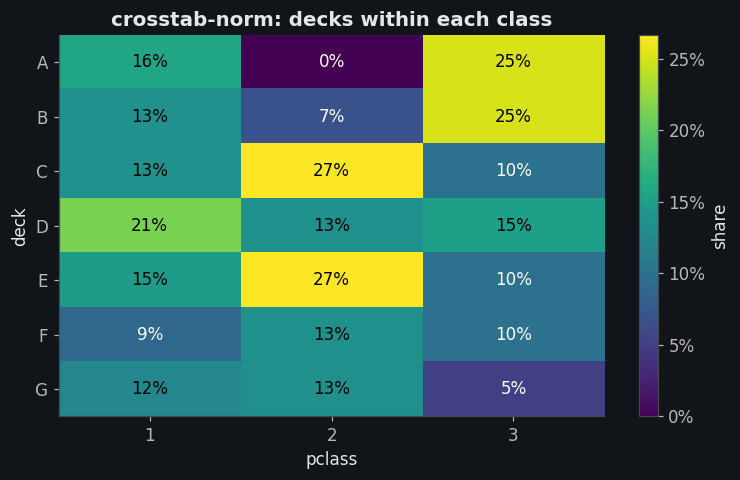

In [85]:
kx.plot(passengers, 'pclass', 'port', 'crosstab-ann', title='crosstab-ann: class × port');
kx.plot(passengers, 'pclass', 'deck', 'crosstab-norm-ann', title='crosstab-norm: decks within each class');

### Numbers: `heat`, `hexbin`

`heat-corr` shows the correlations of the numeric columns, on a fixed −1 to 1 scale. Plain `heat` colours any numeric table: columns along x, index down y.

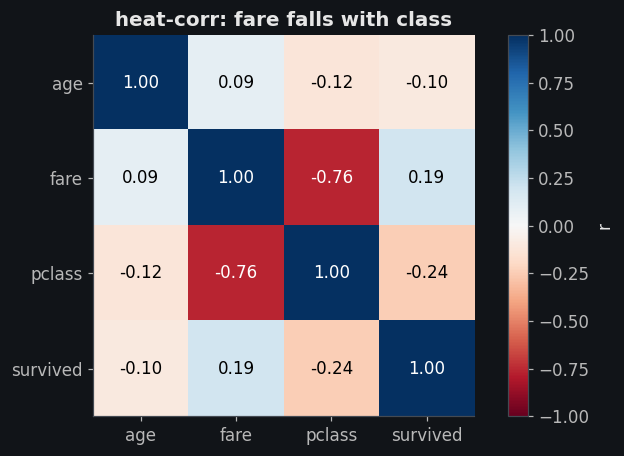

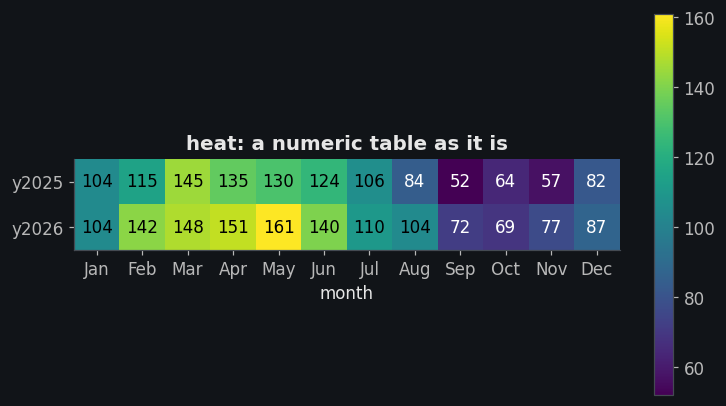

In [86]:
kx.plot(passengers, 'heat-corr-ann', title='heat-corr: fare falls with class');
kx.plot(monthly.set_index('month').T, 'heat-ann', title='heat: a numeric table as it is');

`hexbin` is a scatter for many points: it counts the points in each hexagon (`logc` helps when a few cells hold most of them). With `z`, each hexagon shows the mean `z` instead. Rows with a NaN are left out, and `gridsize=` sets how many hexagons fit across.

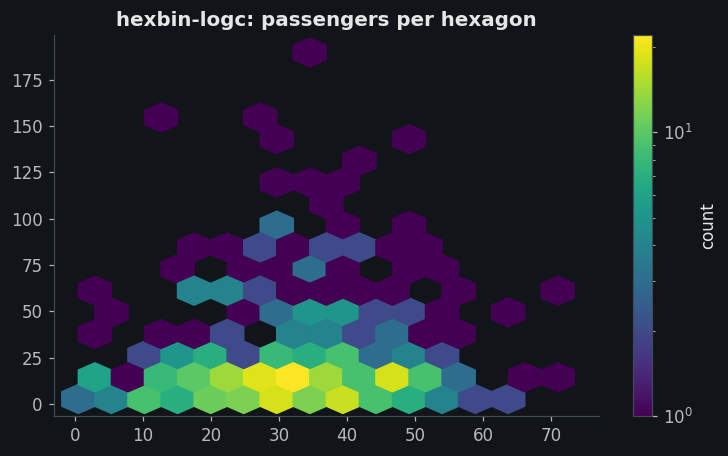

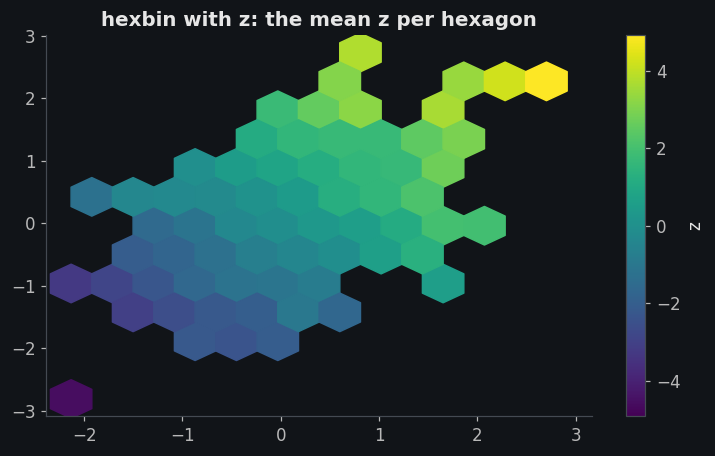

In [87]:
kx.plot(passengers, 'age', 'fare', 'hexbin-logc', gridsize=15, title='hexbin-logc: passengers per hexagon');
kx.plot(cloud, 'x', 'y', 'z', 'hexbin-sym', gridsize=12, title='hexbin with z: the mean z per hexagon');

## 12. Machine learning: evaluating a model

The machine-learning kinds take the truth first and the predictions second, like scikit-learn: `kx.plot(y_true, score, 'roc')`. A second model goes in `z`. The metrics (AUC, average precision, Brier, R²) are computed in numpy, so no scikit-learn is needed, and the plots with a metric draw their legend without `leg`.

The demo data: `binary` is one 0/1 outcome scored by two models, `gbm` (ranks better, but overconfident) and `logreg` (calibrated). `multiclass` has three classes with one probability column each, `regression` has actual and predicted values whose error grows with `x`.

In [88]:
binary, multi, reg = kx.load('binary'), kx.load('multiclass'), kx.load('regression')
binary.head()

,y,gbm,logreg
0,0,0.0008,0.3111
1,0,0.0061,0.3251
2,1,0.5774,0.3050
3,1,0.6356,0.5420
4,0,0.9558,0.7383


### Binary: ranking, `roc`, `pr`, `gain`, `lift`

`roc` shows how well the scores rank positives above negatives, with the AUC. `pr` shows the precision at each recall, with the average precision and a dotted baseline at the positive rate. `gain` and `lift` read like a marketing campaign: taking the top 20% of rows by score, what share of the positives is found, and how many times more than a random 20%. `kx.roc_auc` and `kx.pr_ap` give the numbers.

(0.8033577449777146, 0.759193458964928)

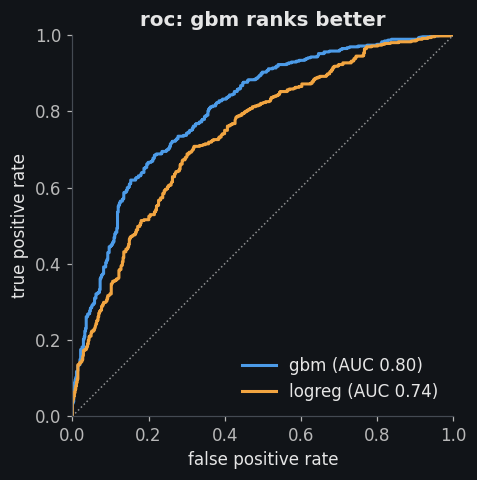

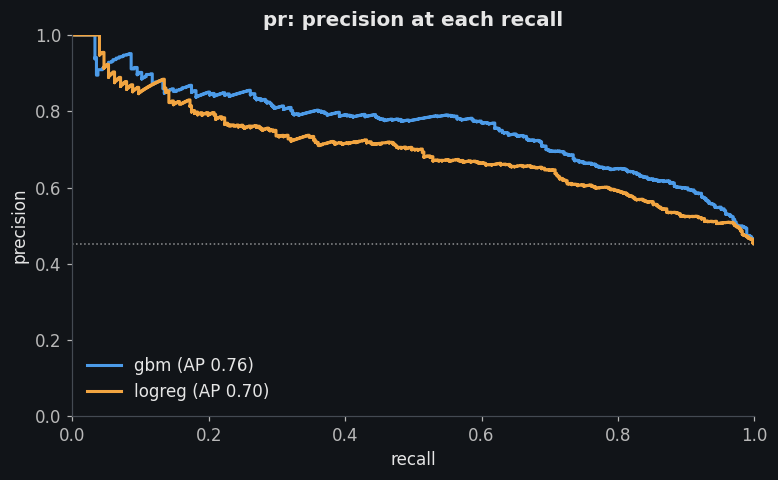

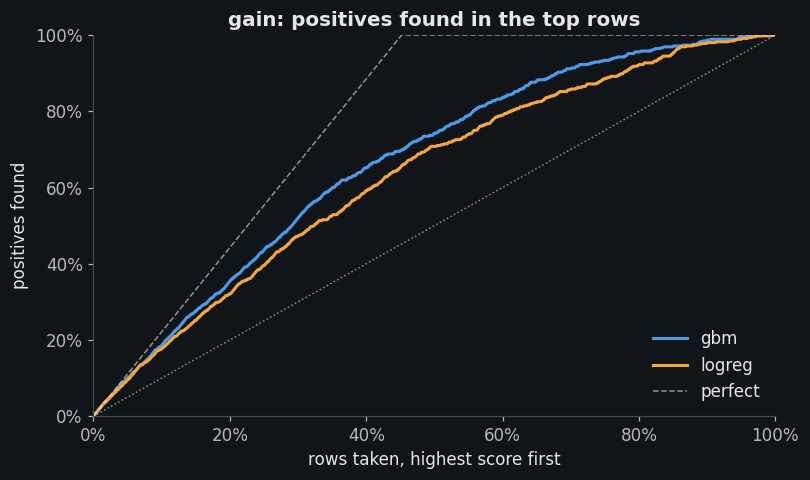

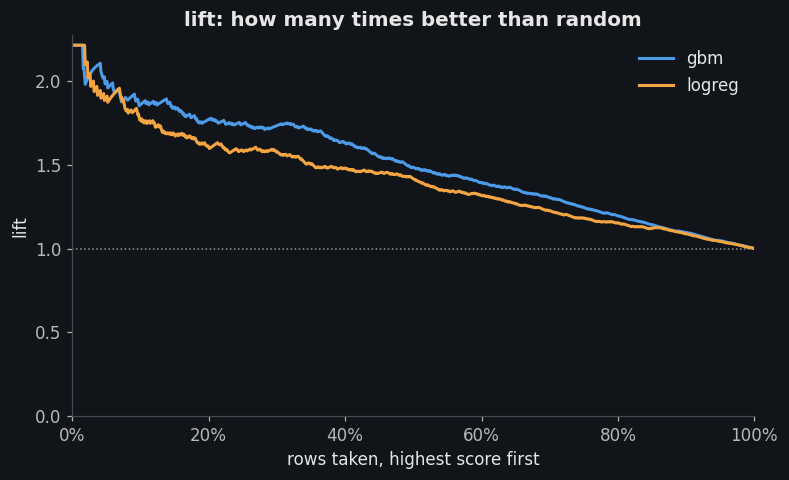

In [89]:
kx.plot(binary, 'y', 'gbm', 'logreg', 'roc', title='roc: gbm ranks better');
kx.plot(binary, 'y', 'gbm', 'logreg', 'pr', title='pr: precision at each recall');
kx.plot(binary, 'y', 'gbm', 'logreg', 'gain', title='gain: positives found in the top rows');
kx.plot(binary, 'y', 'gbm', 'logreg', 'lift', title='lift: how many times better than random');
kx.roc_auc(binary.y, binary.gbm), kx.pr_ap(binary.y, binary.gbm)

### Binary: probabilities, `calib`, `proba`, `thresh`

A better ranking is not a better probability. `calib` puts the mean score in each of 10 bins against how often the outcome happened: on the diagonal, a score of 0.7 comes true 70% of the time. `gbm` is overconfident, `logreg` stays close. `proba` shows the scores of each true class, and `thresh` shows what each cut-off would give; `best` marks the highest F1.

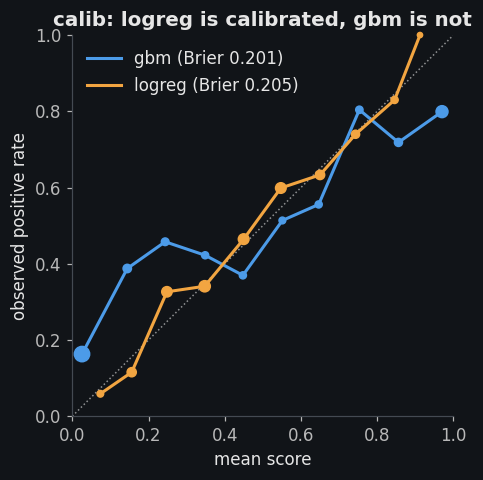

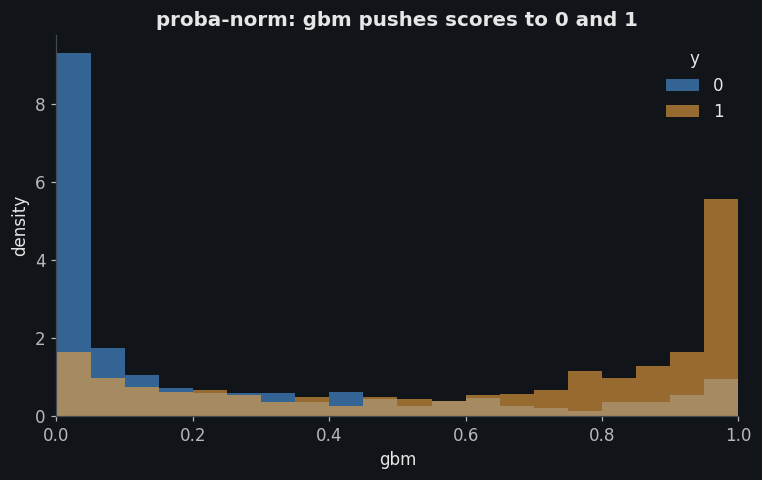

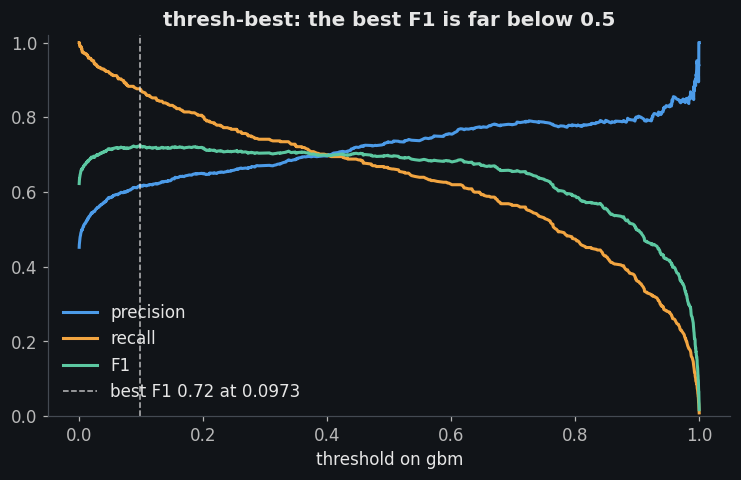

In [90]:
kx.plot(binary, 'y', 'gbm', 'logreg', 'calib', title='calib: logreg is calibrated, gbm is not');
kx.plot(binary, 'y', 'gbm', 'proba-norm', title='proba-norm: gbm pushes scores to 0 and 1');
kx.plot(binary, 'y', 'gbm', 'thresh-best', title='thresh-best: the best F1 is far below 0.5');

### Multiclass: a 2-D score, `cm`

With one column per class, `roc`, `pr` and `proba` draw one curve per class (one-vs-rest), named after the columns. `cm` takes labels, not scores: the true class down the rows and the predicted one along the columns. `norm` makes each row sum to 100%, the recall of each class.

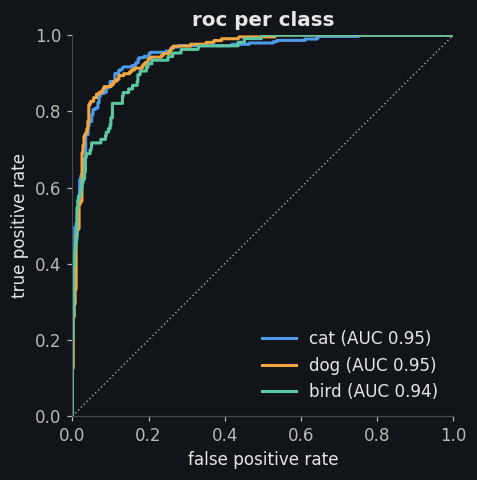

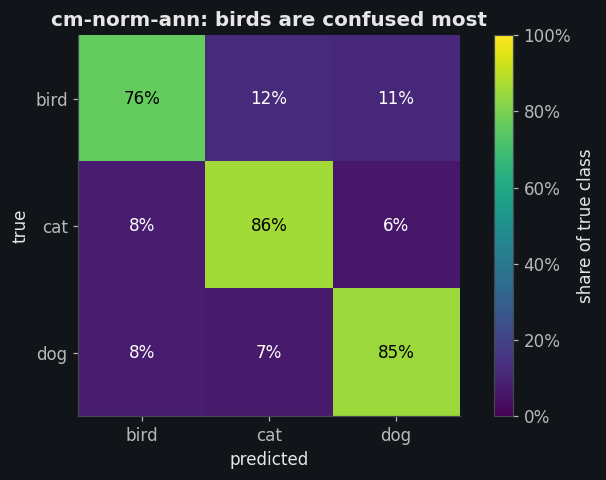

In [91]:
proba = multi[['cat', 'dog', 'bird']]
kx.plot(multi.y, proba, 'roc', title='roc per class');
kx.plot(multi.y, proba.idxmax(axis=1), 'cm-norm-ann', title='cm-norm-ann: birds are confused most');

### Regression: `pva`, `resid`

`pva` puts the predictions against the truth with the `y = x` line and R², RMSE and MAE in the corner; over 5,000 points it switches to hexagons. `resid` shows what is left, `actual - predicted`, against the prediction. A `z` colours the points, here by `x`, to show where the error comes from.

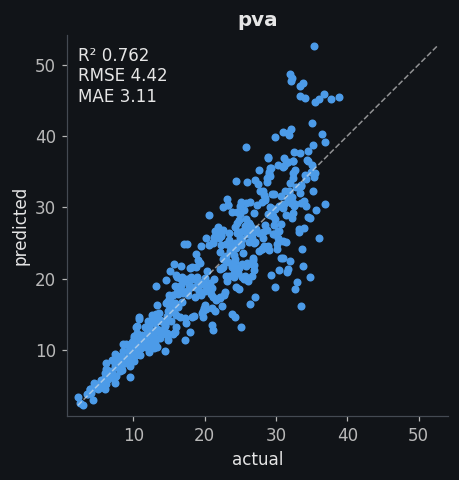

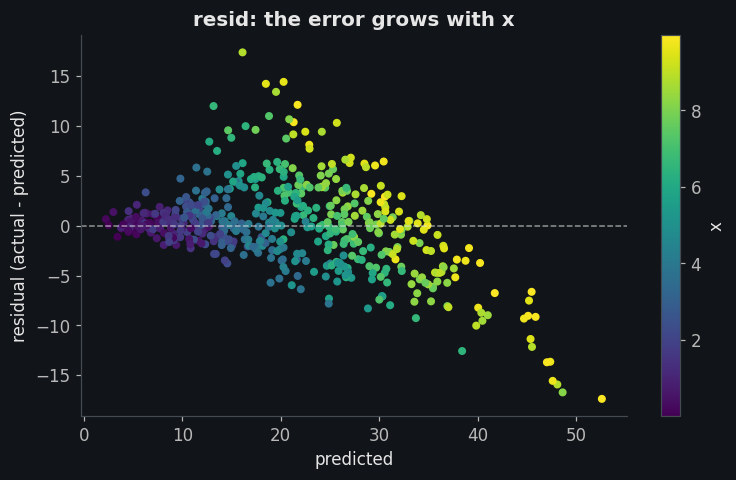

In [92]:
kx.plot(reg, 'actual', 'predicted', 'pva', title='pva');
kx.plot(reg, 'actual', 'predicted', 'x', 'resid', title='resid: the error grows with x');

### Training: `imp`, `loss`, `lcurve`, `vcurve`, `elbow`

`imp` ranks feature importances, `top=` keeps the largest. `loss` takes a training history (a DataFrame, a dict, or the `History` that Keras' `model.fit` returns) and pairs each metric with its `val_` curve; `best` marks the best validation epoch. `lcurve` and `vcurve` take scikit-learn's `learning_curve` and `validation_curve` output: the mean over folds as a line, ± one standard deviation as a band. `elbow` helps pick the number of clusters.

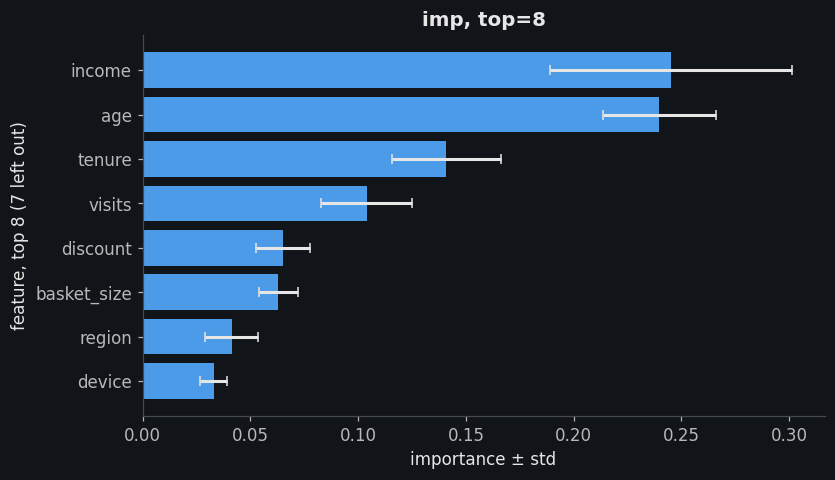

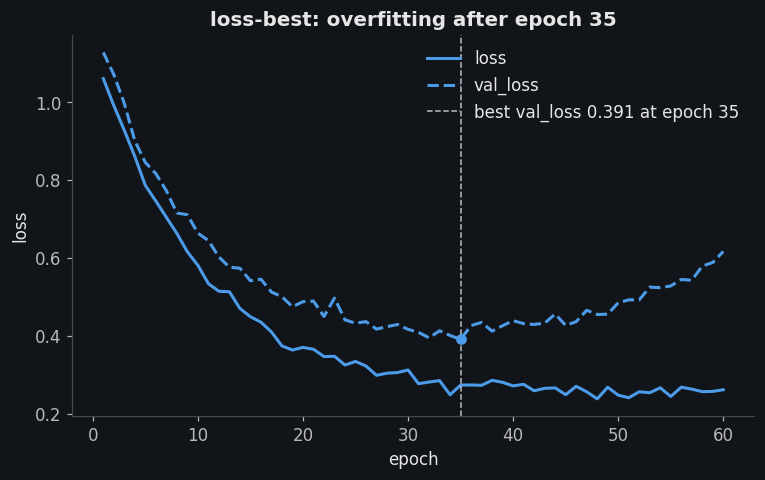

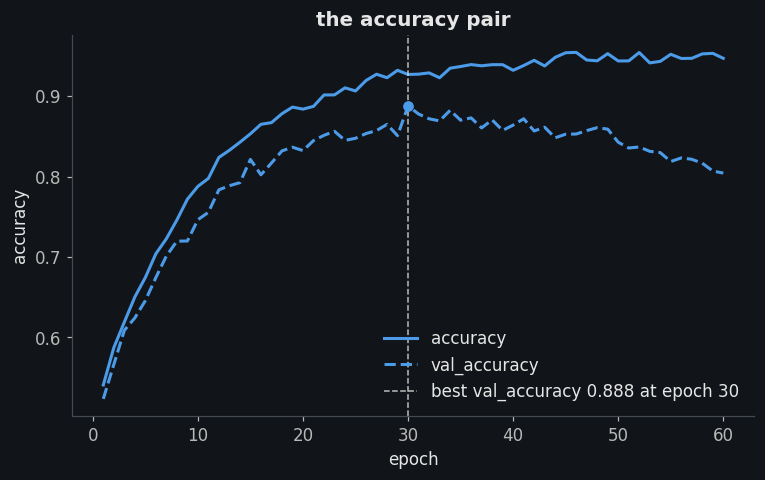

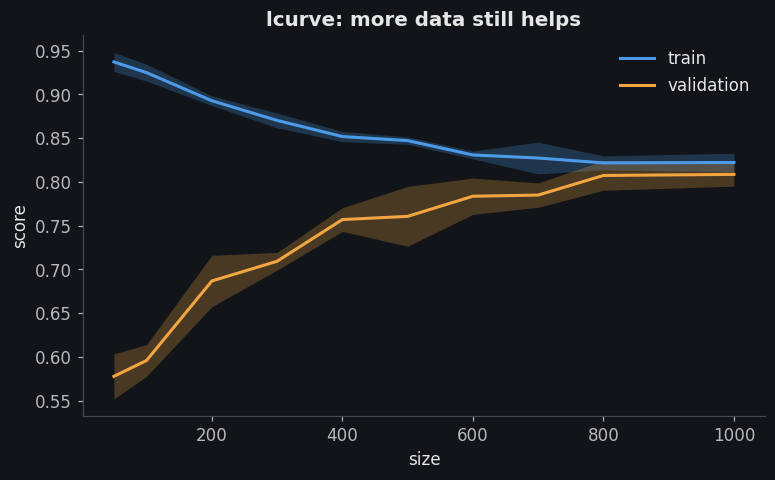

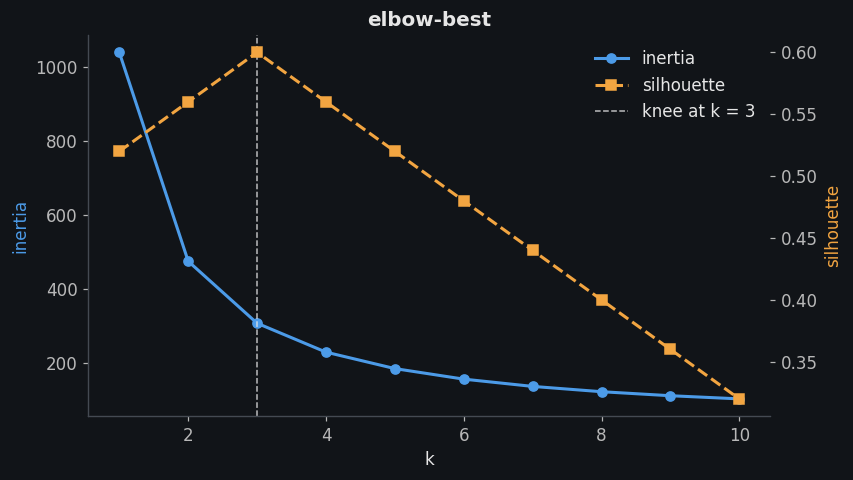

In [93]:
history = kx.load('history')
kx.plot(kx.load('importance'), 'feature', 'importance', 'std', 'imp', top=8, title='imp, top=8');
kx.plot(history, 'loss-best', title='loss-best: overfitting after epoch 35');
kx.plot(history[['accuracy', 'val_accuracy']], 'loss-best', title='the accuracy pair');
curves = kx.load('curves')
kx.plot(curves['size'], curves.filter(like='train_'), curves.filter(like='val_'), 'lcurve', title='lcurve: more data still helps');
ks = np.arange(1, 11)
kx.plot(ks, pd.Series(1000 / ks ** 1.2 + 40, name='inertia'), pd.Series(0.6 - 0.04 * np.abs(ks - 3), name='silhouette'),
        'elbow-best', title='elbow-best');

### One call: `kx.evaluate`

`kx.evaluate(y_true, *scores)` picks the panels from the data: `roc`, `pr`, `calib` and `proba` for a binary task, `roc`, `cm` and `proba` for a 2-D score, and `pva`, `resid` and a histogram of the residuals for a numeric target. It returns the flat array of axes, like `kx.grid`, and `spec=` styles every panel.

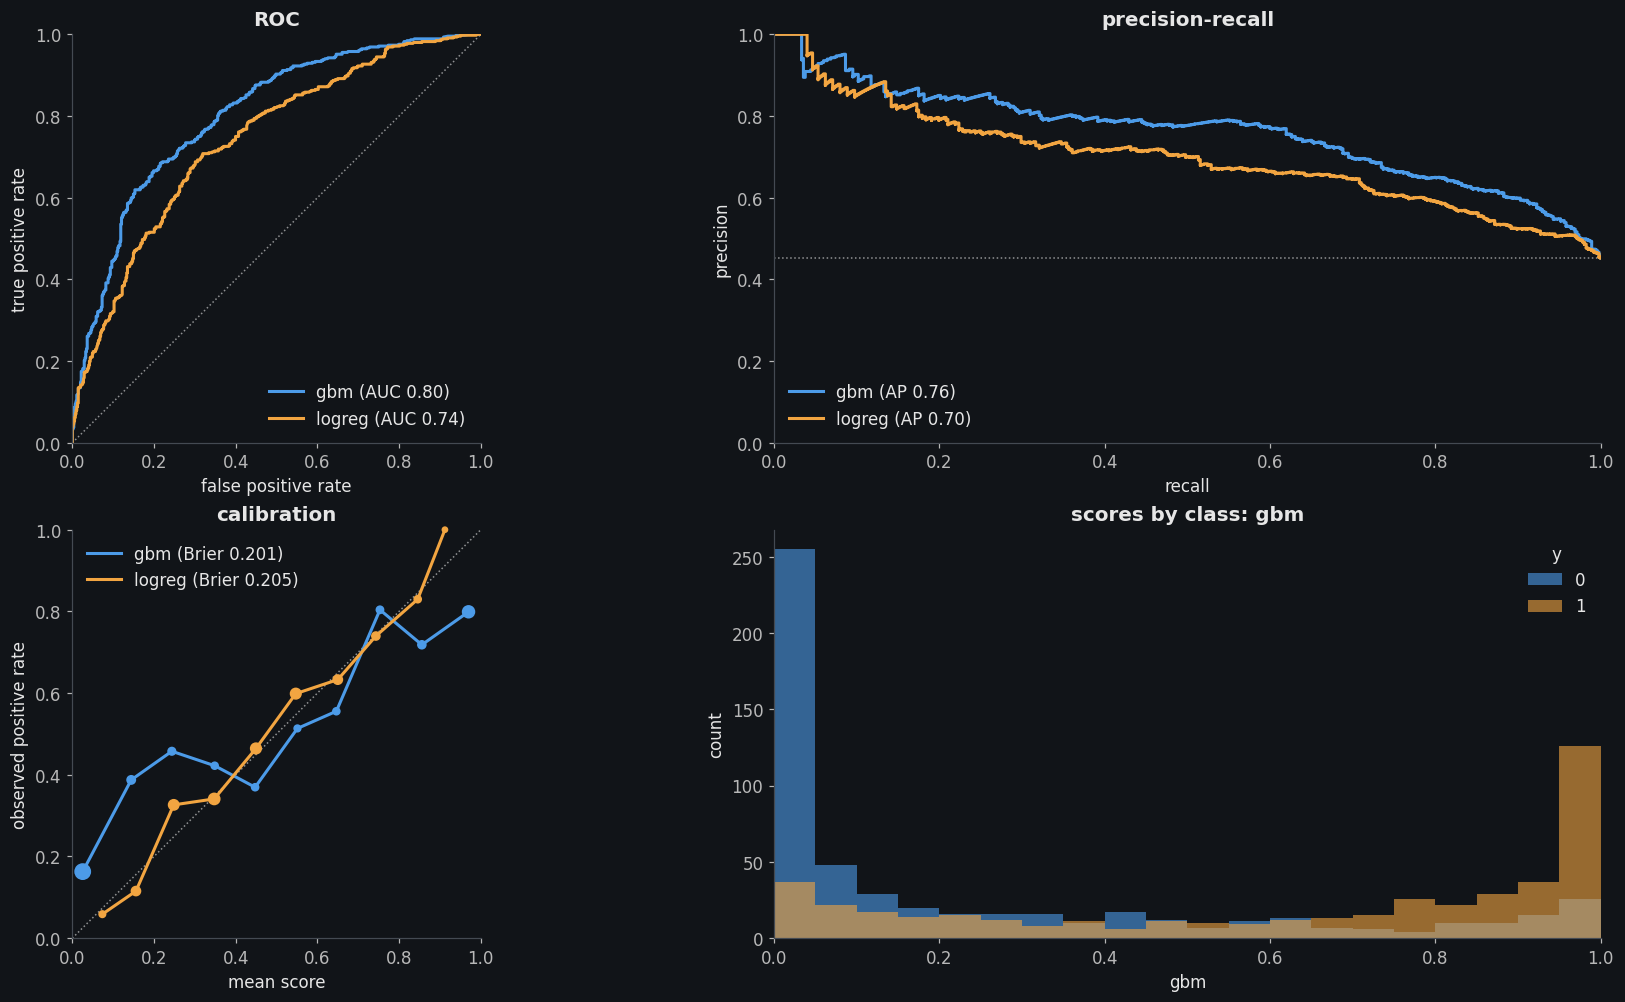

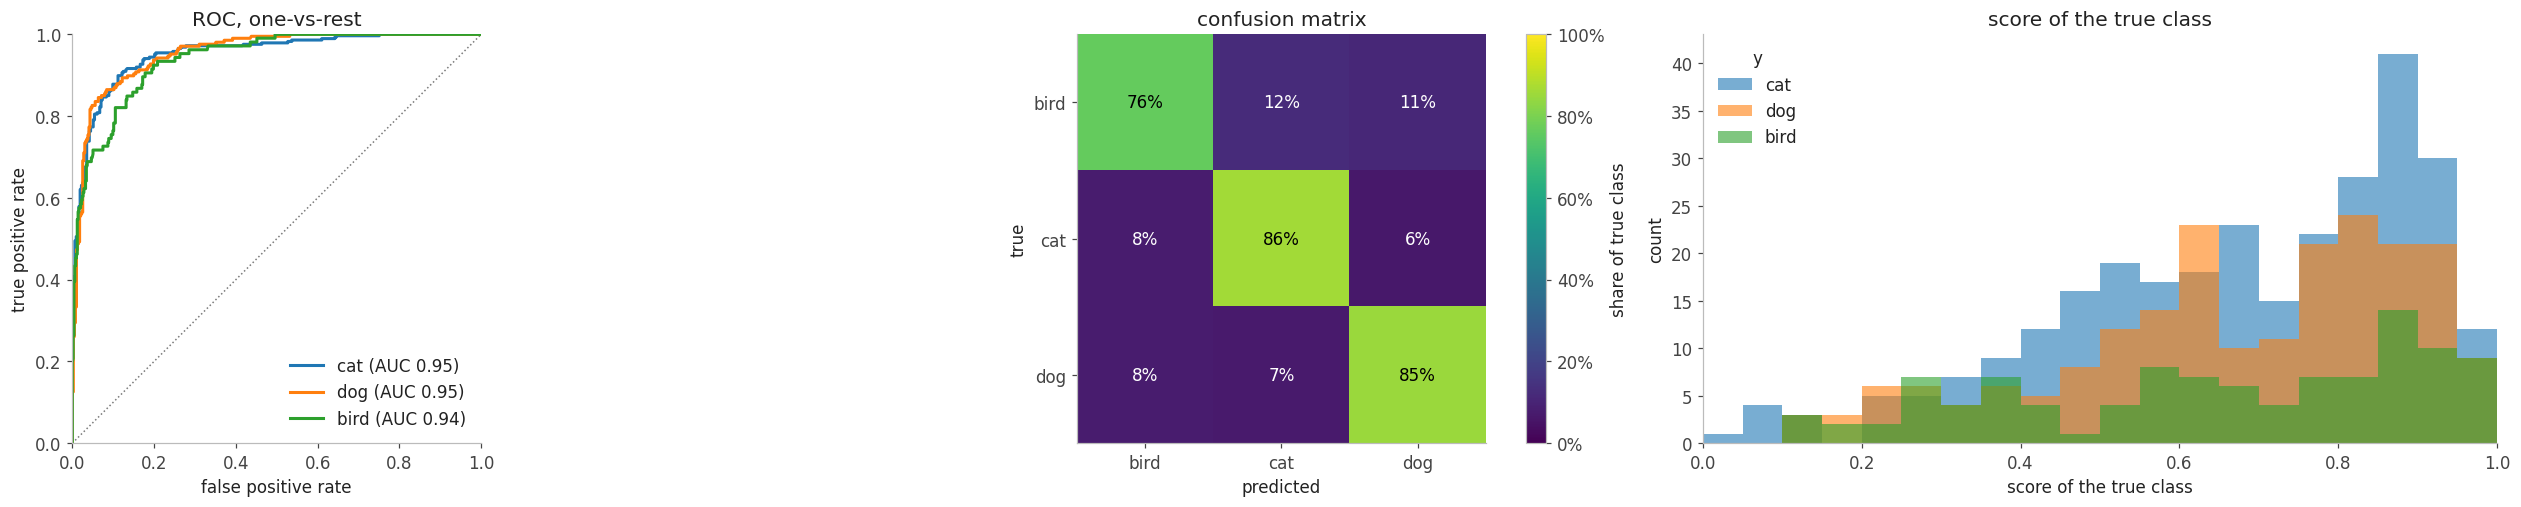

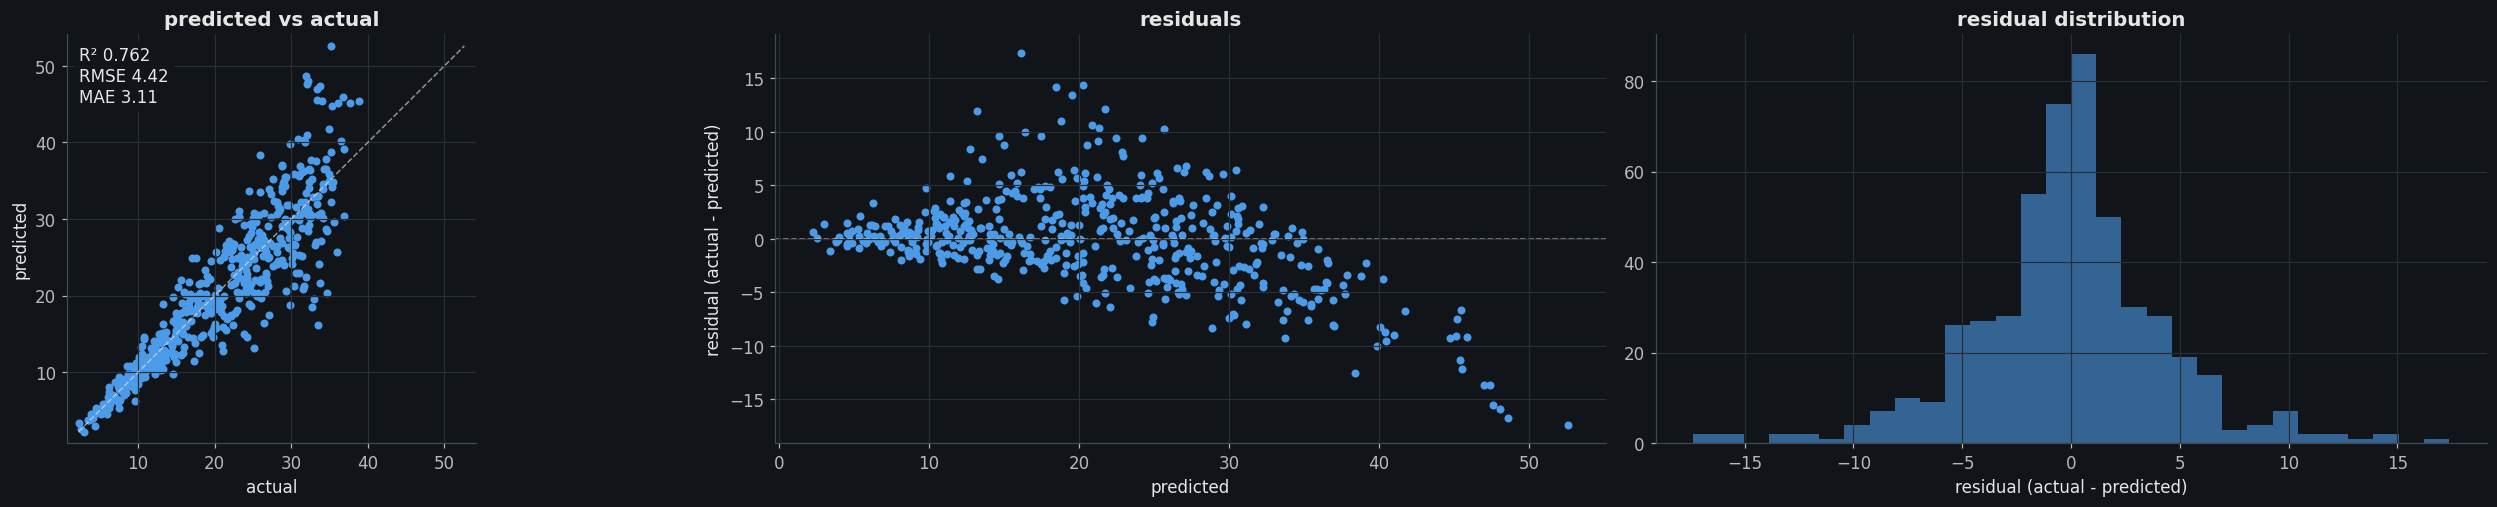

In [94]:
kx.evaluate(binary.y, binary.gbm, binary.logreg);
kx.evaluate(multi.y, proba, spec='light');
kx.evaluate(reg.actual, reg.predicted, spec='grid');

## 13. Transparency

Nothing is hidden. `kx.show(theme)` prints a theme file, `kx.source(kind)` prints the code that draws one kind and `kx.source()` prints every file in the package.

In [95]:
kx.show('science')

# journal single column: 3.5 in wide, 8 pt serif, inward ticks on all four sides
figure.facecolor: FFFFFF
axes.facecolor:   FFFFFF
savefig.facecolor: FFFFFF
text.color:       000000
axes.labelcolor:  000000
axes.edgecolor:   000000
axes.linewidth:   0.6
axes.prop_cycle:  cycler('color', ['4477AA', 'EE6677', '228833', 'CCBB44', '66CCEE', 'AA3377', 'BBBBBB'])
image.cmap:       viridis
figure.figsize:   3.5, 2.6
figure.dpi:       150
savefig.dpi:      600
savefig.bbox:     tight
savefig.pad_inches: 0.02
font.family:      serif
font.serif:       DejaVu Serif, Times New Roman, Times, serif
mathtext.fontset: dejavuserif
font.size:        8
axes.titlesize:   8
axes.labelsize:   8
xtick.labelsize:  7
ytick.labelsize:  7
legend.fontsize:  7
legend.frameon:   False
legend.handlelength: 1.6
xtick.direction:  in
ytick.direction:  in
xtick.top:        True
ytick.right:      True
xtick.minor.visible: True
ytick.minor.visible: True
xtick.major.size: 3
ytick.major.size: 3
xtick.minor.size: 1.5
ytick.m

In [96]:
kx.source('violin')

@kind("violin", flags=("mean", "ann"), needs_y=False, takes_by=True)
def violin(ax: Axes, x: ArrayLike, y: ArrayLike | None, z: ArrayLike | None, flags: set[str],
           by: ArrayLike | None = None, **kw: Any) -> None:
    """Violin plots of x, y, z side by side: a mirrored KDE with the median and quartiles marked.
    by= splits x into one violin per group. mean = a diamond at the mean, ann = the median (and mean) as text.
    kw: ax.violinplot, e.g. widths=0.5."""
    series = _split(x, y, z, by)
    _need(series, "violin", 2)
    values = [v for v, _ in series]
    parts = ax.violinplot(values, **{"showextrema": False, **kw})
    for i, body in enumerate(parts["bodies"]):
        body.set(facecolor=f"C{i}", edgecolor=f"C{i}", alpha=0.6)
    pos = np.arange(1, len(values) + 1)
    q1, med, q3 = np.array([np.percentile(v, [25, 50, 75]) for v in values]).T
    ink = plt.rcParams["text.color"]
    ax.vlines(pos, q1, q3, color=ink, linewidth=3)
    ax.scatter(pos, med, color=plt.rcPa

In [97]:
kx.source()

# ---------- kx/__init__.py ----------
"""
kx: tiny matplotlib helper.

Token grammar for kx.plot(spec):   kind-theme-flag-flag-...
  kind  : line | step | area | band | scatter | bar | barh | hist | kde | ridge | ecdf | box | violin | strip
          | qq | heat | crosstab | count | missing | nullmap | hexbin
          | cm | roc | pr | calib | proba | thresh | gain | lift | pva | resid | imp | loss
          | lcurve | vcurve | elbow
  theme : any file name in styles/
  flags : grid | leg | legout | tight | rot | wrap | logx | logy | logxy | symlogy | zero | eq | pct | si
          and per kind: stack norm cum (bars, area, hist), date mk (lines), sort ann (bars, count),
          stack norm (count),
          mean median ann (distributions), nocb sym logc (scatter, heat, hexbin), corr ann (heat),
          norm ann nocb logc (crosstab), ann all (missing), sort (nullmap), diag (scatter, hexbin),
          fit (scatter), norm ann nocb (cm), norm (proba), best (thresh, loss, elbow),
   

---

Source, issues and the feature tracker: [github.com/vhrabar/kx-plot](https://github.com/vhrabar/kx-plot)